# MUL — Master Notebook

Everything you need, nothing you don't. The 12–14 h training loop is **not in this
notebook at all**, so it cannot be run by accident.

Each section header is tagged:

- **`[RUN]`** — run it, every session
- **`[RUN ONCE]`** — run it tonight / tomorrow, then never again
- **`[SKIP]`** — already done; results load from CSV

---

### Tonight (~35 min hands-on, then 12 h unattended)
`[RUN]` S1–S5 → B1–B9 → then **O1** (the oracle) and go to sleep.

### Tomorrow (~7 h, all resumable)
R12 → R1–R4 → R10–R11 → R5–R8 → R9 → E1.

---

### Prerequisites on disk
`best_model.pth`, `Data_Entry_2017.csv`, `images-224/images-224/`, and your existing
`proofs/` folder from the previous session.

**Back this up before starting:** `cp best_model.pth best_model_epoch12.bak`

# PART 0 — Setup

Definitions only. ~7 min, dominated by the image-path index walk in S3.

## `[RUN]` S1 — Imports, seeds, device

In [1]:
import os
import random
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
import torch.nn.functional as F

# Set seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## `[RUN]` S2 — Dataset class

In [3]:
class ChestXrayDataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.data = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform
        self.labels = self.data['Finding Labels'].str.get_dummies(sep='|')
        
        # Pre-build image path mapping for faster loading
        self.img_paths = {}
        print("Building image path index...")
        for root, _, files in os.walk(self.img_dir):
            for file in files:
                if file.endswith('.png'):
                    self.img_paths[file] = os.path.join(root, file)
        print(f"Indexed {len(self.img_paths)} images")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_name = self.data.iloc[idx]['Image Index']
        img_path = self.img_paths.get(img_name)
        
        if img_path is None:
            raise FileNotFoundError(f"Image {img_name} not found in {self.img_dir}")
        
        image = Image.open(img_path).convert('RGB')
        
        label = torch.tensor(
            self.labels.iloc[idx].values,
            dtype=torch.float32
        )

        if self.transform:
            image = self.transform(image)

        return image, label, idx

## `[RUN]` S3 — Transforms, dataset, train/val split · ~4 min

The path-index walk over 112,120 files happens here.

In [4]:
# Advanced data augmentation including Gaussian Blur to improve model robustness against noise
transform_train = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                        std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                        std=[0.229, 0.224, 0.225])
])

dataset = ChestXrayDataset(
    csv_file='Data_Entry_2017.csv',
    img_dir='images-224/images-224',
    transform=None
)

indices = list(range(len(dataset)))
train_indices, val_indices = train_test_split(
    indices, test_size=0.2, random_state=42, shuffle=True
)

class TransformedSubset(torch.utils.data.Subset):
    def __init__(self, dataset, indices, transform=None):
        super().__init__(dataset, indices)
        self.transform = transform
        
    def __getitem__(self, idx):
        image, label, original_idx = self.dataset[self.indices[idx]]
        if self.transform:
            image = self.transform(image)
        return image, label, original_idx
    
    def __getitems__(self, indices):
        return [self.__getitem__(idx) for idx in indices]

train_dataset = TransformedSubset(dataset, train_indices, transform_train)
val_dataset = TransformedSubset(dataset, val_indices, transform_val)

# --- THE FIX IS HERE ---
# Changed num_workers to 0 to prevent Jupyter multiprocessing deadlocks
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=0, pin_memory=True
)

print("DataLoaders initialized. Fetching first batch...")
test_images, test_labels, test_indices = next(iter(train_loader))
print(f"Batch test successful! Image shape: {test_images.shape}")

Building image path index...
Indexed 112120 images
DataLoaders initialized. Fetching first batch...
Batch test successful! Image shape: torch.Size([32, 3, 224, 224])


## `[RUN]` S4 — Model architecture

In [5]:
class ChestXrayDenseNet(nn.Module):
    def __init__(self, num_classes=15, pretrained=True, dropout_rate=0.3):
        super(ChestXrayDenseNet, self).__init__()
        
        # DenseNet121 is the gold standard architecture for medical imaging
        if pretrained:
            weights = models.DenseNet121_Weights.IMAGENET1K_V1
            self.backbone = models.densenet121(weights=weights)
        else:
            self.backbone = models.densenet121(weights=None)
            
        num_features = self.backbone.classifier.in_features
        
        # Replace the classifier head for 15 classes
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(num_features, 256),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(256),
            nn.Dropout(dropout_rate * 0.5),
            nn.Linear(256, num_classes)
        )
        
    def forward(self, x):
        return self.backbone(x)
        
    def freeze_backbone(self):
        """Freeze backbone layers for initial custom head fine-tuning"""
        for name, param in self.backbone.named_parameters():
            if 'classifier' not in name:
                param.requires_grad = False
                
    def unfreeze_backbone(self):
        """Unfreeze all layers"""
        for param in self.backbone.parameters():
            param.requires_grad = True

model = ChestXrayDenseNet(num_classes=15, pretrained=True).to(device)
print(f"DenseNet121 Model created successfully on {device}")

DenseNet121 Model created successfully on cuda


## `[RUN]` S5 — Loss and criterion

Modified from your original: it reuses `dataset` instead of building a second
`ChestXrayDataset`, which saves a redundant ~3 min index walk. It also drops the
`optimizer`/`scheduler` lines, since nothing here trains the base model.

In [6]:
class FocalLossWithLogits(nn.Module):
    """Dynamically down-weights easy examples to focus on hard-to-predict anomalies"""
    def __init__(self, alpha=1.0, gamma=2.0, pos_weight=None):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.bce_with_logits = nn.BCEWithLogitsLoss(pos_weight=pos_weight, reduction='none')

    def forward(self, inputs, targets):
        bce_loss = self.bce_with_logits(inputs, targets)
        probs = torch.sigmoid(inputs)
        pt = torch.where(targets == 1, probs, 1 - probs)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * bce_loss
        return focal_loss.mean()

label_counts  = dataset.labels.sum(axis=0).values      # reuse S3's dataset
total_samples = len(dataset)
pos_weights_tensor = torch.tensor(total_samples / (label_counts + 1e-6),
                                  dtype=torch.float32).to(device)
criterion = FocalLossWithLogits(pos_weight=pos_weights_tensor)
print("criterion ready (no second dataset build)")

criterion ready (no second dataset build)


# PART 1 — Rebuild state

Your kernel died, so this reconstructs everything the oracle needs. ~20 min total.
None of it trains the base model.

## `[RUN]` B1 — Proof imports and namespace check

In [7]:
import os, json, time, copy, warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr
from scipy.optimize import brentq
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

REQUIRED = ["device", "dataset", "train_indices", "val_indices",
            "TransformedSubset", "transform_train", "transform_val",
            "ChestXrayDenseNet", "FocalLossWithLogits"]
missing = [n for n in REQUIRED if n not in globals()]
assert not missing, f"Run your original notebook cells 0-8 first. Missing: {missing}"
assert os.path.exists("best_model.pth"), "best_model.pth not found"

print("Namespace OK")
print(f"  device            : {device}")
print(f"  dataset           : {len(dataset)} images")
print(f"  train / val split : {len(train_indices)} / {len(val_indices)}")

# --- checkpoint provenance: confirm this is the epoch-11/12 model, not a retrain ---
_ck = torch.load("best_model.pth", weights_only=False)
if "history" in _ck:
    _h = _ck["history"]; _b = int(np.argmax(_h["val_auc"]))
    print(f"  checkpoint        : best epoch {_b+1}, val AUC {_h['val_auc'][_b]:.4f} "
          f"({len(_h['val_auc'])} epochs recorded)")
    if abs(_h["val_auc"][_b] - 0.8391) > 0.005:
        print("  WARNING: this is not the 0.8391 checkpoint the paper reports. "
              "Results below will not be comparable to the published numbers.")
else:
    print("  checkpoint        : no history key — cannot verify which epoch this is")
del _ck

Namespace OK
  device            : cuda
  dataset           : 112120 images
  train / val split : 89696 / 22424
  checkpoint        : best epoch 12, val AUC 0.8391 (12 epochs recorded)


## `[RUN]` B2 — Configuration

In [8]:
CFG = dict(
    CHECKPOINT   = "best_model.pth",
    OUT          = "proofs",
    SEEDS        = [42, 7, 2024],       # >=3 seeds; single-seed results are not results
    N_PATIENTS   = 28,                  # ChestX-ray14 averages ~3.6 img/patient,
                                        # so ~28 patients ~ 100 forget images,
                                        # matching the paper's stated |D_f| = 100
    N_RETAIN_SUB = 400,
    BATCH_SIZE   = 32,
    # unlearning
    IGC_EPOCHS   = 5,   IGC_LR   = 1e-4,
    HYB_EPOCHS   = 3,   HYB_LR   = 5e-5,
    SIGMA        = 1e-4,
    CLIP         = 1.0,
    # sweeps
    SIGMA_SWEEP  = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
    N_REQUESTS   = 15,                  # sequential deletion
    # theory
    DELTA_DP     = 1e-5,
    # switches for the expensive runs
    RUN_SIGMA_SWEEP = True,
    RUN_SEQUENTIAL  = True,
    RUN_ORACLE      = False,            # ~11 h — flip on overnight
)

os.makedirs(f"{CFG['OUT']}/tables", exist_ok=True)
CLASS_NAMES = dataset.labels.columns.tolist()
PREVALENCE  = (dataset.labels.sum(axis=0) / len(dataset)).to_dict()

print(f"{len(CLASS_NAMES)} classes")
print("rarest :", sorted(PREVALENCE.items(), key=lambda kv: kv[1])[:3])

15 classes
rarest : [('Hernia', 0.0020246164823403494), ('Pneumonia', 0.01206742775597574), ('Fibrosis', 0.015037459864430967)]


## `[RUN]` X1 — Vector figure export (run once, right after B2)

In [ ]:
# ============================================================================
# X1 - Vector figure export
#
# WHY: IEEE production flags raster figures at print size. Every plotting cell
# in this notebook calls plt.savefig(..., ".png"). Rather than edit each one,
# this wraps savefig so that ANY later call ALSO writes a .pdf alongside the
# .png. Run this once after B2 and every figure you subsequently regenerate
# comes out submission-ready.
#
# In main.tex / supp.tex the \includegraphics paths have no extension, so LaTeX
# picks the PDF automatically once it exists. Nothing to change there.
#
# Idempotent: safe to re-run. ~instant, no GPU.
# ============================================================================

import os
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image          # F9 needs this in scope

matplotlib.rcParams["pdf.fonttype"]  = 42   # embed TrueType, not Type3
matplotlib.rcParams["ps.fonttype"]   = 42   # IEEE rejects Type3
matplotlib.rcParams["savefig.bbox"]  = "tight"

if not getattr(plt.savefig, "_dual_patched", False):
    _orig_savefig = plt.savefig

    def _dual_savefig(fname, *a, **kw):
        out = _orig_savefig(fname, *a, **kw)
        try:
            stem, ext = os.path.splitext(str(fname))
            if ext.lower() in (".png", ".jpg", ".jpeg"):
                kw2 = {k: v for k, v in kw.items() if k != "dpi"}
                _orig_savefig(stem + ".pdf", *a, **kw2)
                print(f"    [vector] also wrote {stem}.pdf")
        except Exception as e:
            print(f"    [vector] PDF export failed for {fname}: {e}")
        return out

    _dual_savefig._dual_patched = True
    plt.savefig = _dual_savefig
    print("savefig patched: PNG calls now also emit PDF")
else:
    print("savefig already patched")

FIG_MAP = {
    "fig5_perclass_delta":   "main Fig. 1  (per-class delta, NIH)  /  supp Fig. 4 (CheXpert)",
    "fig8_forget_scaling":   "main Fig. 3  (forget-set scaling)",
    "fig9_gradcam":          "main Fig. 2  (Grad-CAM before/after)",
    "sfig5_gradcam4way":     "supp Fig. 5  (four-way Grad-CAM)  [already high-res]",
    "fig4_frontier_v2":      "main Fig. 4  (privacy-utility frontier)  -> cell X2",
}
print("\nfigure -> paper mapping")
for k, v in FIG_MAP.items():
    print(f"  {k:<24} {v}")
print("\nRe-run B15 / R9 / R11 (and the CheXpert-phase B15) to regenerate as PDF.")


## `[RUN]` B3 — Model / loader helpers

In [9]:
def fresh_model(path=None):
    # Reload the epoch-11 checkpoint. Never reuse a mutated model.
    path = path or CFG["CHECKPOINT"]
    m = ChestXrayDenseNet(num_classes=15, pretrained=True).to(device)
    ck = torch.load(path, weights_only=False)
    m.load_state_dict(ck["model_state_dict"])
    m.eval()
    return m

val_loader_eval = DataLoader(
    TransformedSubset(dataset, val_indices, transform_val),
    batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)

@torch.no_grad()
def per_class_auc(model, loader=None, desc="eval"):
    loader = loader or val_loader_eval
    model.eval()
    P, Y = [], []
    for images, labels, _ in tqdm(loader, desc=desc, leave=False):
        P.append(torch.sigmoid(model(images.to(device))).cpu().numpy())
        Y.append(labels.numpy())
    P, Y = np.concatenate(P), np.concatenate(Y)
    return {c: roc_auc_score(Y[:, i], P[:, i])
            for i, c in enumerate(CLASS_NAMES) if len(np.unique(Y[:, i])) > 1}

def macro_auc(model, loader=None, desc="eval"):
    return float(np.mean(list(per_class_auc(model, loader, desc).values())))

# ---- evidence manifest -------------------------------------------------
MANIFEST = {}
def record(claim, value, note=""):
    MANIFEST.setdefault(claim, []).append(
        {"value": value, "note": note, "t": time.strftime("%Y-%m-%d %H:%M:%S")})
    with open(f"{CFG['OUT']}/manifest.json", "w") as f:
        json.dump(MANIFEST, f, indent=2, default=str)
    print(f"  [recorded] {claim}")

print("helpers ready")

helpers ready


## `[RUN]` B4 — Crash recovery

Atomic checkpointing. This is what makes O1 survivable.

In [10]:
CACHE = f"{CFG['OUT']}/cache"
MODELDIR = f"{CFG['OUT']}/models"
os.makedirs(CACHE, exist_ok=True); os.makedirs(MODELDIR, exist_ok=True)

def _atomic_save(obj, path):
    # Write to .tmp then os.replace -- a power cut can never leave a half-file.
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

def save_ckpt(path, model, optimizer=None, scheduler=None, epoch=0, history=None, **extra):
    _atomic_save(dict(
        model=model.state_dict(),
        opt=optimizer.state_dict() if optimizer is not None else None,
        sch=scheduler.state_dict() if scheduler is not None else None,
        epoch=epoch, history=history or [],
        rng=dict(torch=torch.get_rng_state(),
                 cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
                 numpy=np.random.get_state()),
        **extra), path)

def load_ckpt(path, model, optimizer=None, scheduler=None, restore_rng=True):
    # Returns the epoch to START from (last completed + 1), or 1 if no checkpoint.
    if not os.path.exists(path):
        return 1, []
    st = torch.load(path, weights_only=False)
    model.load_state_dict(st["model"])
    if optimizer is not None and st.get("opt"):  optimizer.load_state_dict(st["opt"])
    if scheduler is not None and st.get("sch"):  scheduler.load_state_dict(st["sch"])
    if restore_rng and st.get("rng"):
        torch.set_rng_state(st["rng"]["torch"].cpu()
                            if hasattr(st["rng"]["torch"], "cpu") else st["rng"]["torch"])
        if st["rng"]["cuda"] is not None and torch.cuda.is_available():
            torch.cuda.set_rng_state_all([r.cpu() if hasattr(r,"cpu") else r
                                          for r in st["rng"]["cuda"]])
        np.random.set_state(st["rng"]["numpy"])
    print(f"  resumed from {path}: {st['epoch']} epochs done -> starting at {st['epoch']+1}")
    return st["epoch"] + 1, st.get("history", [])

def cached(name, fn, force=False):
    # Memoize an expensive python object to proofs/cache/<name>.pt
    p = f"{CACHE}/{name}.pt"
    if os.path.exists(p) and not force:
        print(f"  [cache hit] {name}")
        return torch.load(p, weights_only=False)
    val = fn()
    _atomic_save(val, p)
    return val

def save_result(name, payload, model=None):
    with open(f"{CACHE}/result_{name}.json", "w") as f:
        json.dump(payload, f, default=str)
    if model is not None:
        _atomic_save(model.state_dict(), f"{MODELDIR}/{name}.pth")

def load_results():
    out = {}
    for f in os.listdir(CACHE):
        if f.startswith("result_") and f.endswith(".json"):
            out[f[7:-5]] = json.load(open(f"{CACHE}/{f}"))
    return out

def load_saved_model(name):
    p = f"{MODELDIR}/{name}.pth"
    if not os.path.exists(p): return None
    m = ChestXrayDenseNet(num_classes=15, pretrained=False).to(device)
    m.load_state_dict(torch.load(p, weights_only=False)); m.eval()
    return m

_done = load_results()
print(f"crash recovery ready | {len(_done)} scheme result(s) already on disk: "
      f"{sorted(_done) if _done else 'none'}")

crash recovery ready | 5 scheme result(s) already on disk: ['finetune_retain', 'hybrid_bernoulli', 'hybrid_uniform', 'influence_weighted', 'neggrad_ablation']


## `[RUN]` B5 — Noise calibration · 1 s, no GPU

Propositions 1–2 and Corollary 1. Should print `eps0 = 1.514`, `eps_total = 108.6`, `sigma >= 2.93e-03`.

In [25]:
def gaussian_eps(delta2, sigma, delta=None):
    delta = delta or CFG["DELTA_DP"]
    return delta2 * np.sqrt(2 * np.log(1.25 / delta)) / sigma

def gaussian_sigma(delta2, eps, delta=None):
    delta = delta or CFG["DELTA_DP"]
    return delta2 * np.sqrt(2 * np.log(1.25 / delta)) / eps

def advanced_composition(eps0, k, delta_prime=1e-5):
    return np.sqrt(2*k*np.log(1/delta_prime))*eps0 + k*eps0*(np.exp(eps0)-1)

def sensitivity(eta, C, E, B, per_sample=True):
    # Proposition 1. per_sample=False = what clip_grad_norm_ actually does.
    return 2 * eta * C * E / (B if per_sample else 1.0)

rows = []
for ps in (True, False):
    for E in (3, 5):
        d2 = sensitivity(CFG["IGC_LR"], CFG["CLIP"], E, CFG["BATCH_SIZE"], ps)
        rows.append(dict(regime=("per-sample" if ps else "aggregate") + f", E={E}",
                         delta2=d2,
                         eps_at_sigma=gaussian_eps(d2, CFG["SIGMA"]),
                         sigma_for_eps1=gaussian_sigma(d2, 1.0)))
calib = pd.DataFrame(rows)
calib.to_csv(f"{CFG['OUT']}/noise_calibration.csv", index=False)
display(calib.style.format({"delta2":"{:.2e}","eps_at_sigma":"{:.2f}",
                            "sigma_for_eps1":"{:.2e}"}))

# Corollary 1 — lifetime budget
d2   = sensitivity(CFG["IGC_LR"], CFG["CLIP"], 5, CFG["BATCH_SIZE"], True)
eps0 = gaussian_eps(d2, CFG["SIGMA"])
k    = CFG["N_REQUESTS"]
eps_tot   = advanced_composition(eps0, k)
eps0_star = brentq(lambda e: advanced_composition(e, k) - 1.0, 1e-8, 5)
SIGMA_STAR = gaussian_sigma(d2, eps0_star)

print(f"\nsigma = {CFG['SIGMA']:.1e}  ->  eps0 = {eps0:.3f} per request")
print(f"after k = {k} requests      ->  eps_total = {eps_tot:.1f}")
print(f"for eps_total <= 1         ->  sigma >= {SIGMA_STAR:.2e}  "
      f"({SIGMA_STAR/CFG['SIGMA']:.0f}x current)")

record("C11_noise_calibration",
       dict(eps0=float(eps0), eps_total=float(eps_tot), sigma_required=float(SIGMA_STAR)),
       "Propositions 1-2 + Corollary 1; utility half needs Cell 15")

,regime,delta2,eps_at_sigma,sigma_for_eps1
0,"per-sample, E=3",1.88e-05,0.91,9.08e-05
1,"per-sample, E=5",3.13e-05,1.51,1.51e-04
2,"aggregate, E=3",6.00e-04,29.07,2.91e-03
3,"aggregate, E=5",1.00e-03,48.45,4.84e-03



sigma = 1.0e-04  ->  eps0 = 1.514 per request
after k = 15 requests      ->  eps_total = 108.6
for eps_total <= 1         ->  sigma >= 2.93e-03  (29x current)
  [recorded] C11_noise_calibration


## `[RUN]` B6 — Patient-level forget set

Expect 28 patients → 57 images, `all in train: True`, `patient-disjoint: True`.

In [13]:
def build_patient_forget_set(train_idx, n_patients=None, seed=42, verbose=True):
    n_patients = n_patients or CFG["N_PATIENTS"]
    rng = np.random.RandomState(seed)
    meta = dataset.data
    pid_col = "Patient ID" if "Patient ID" in meta.columns else meta.columns[3]
    idx_to_pid = meta[pid_col].values

    train_set = set(int(i) for i in train_idx)
    by_patient = defaultdict(list)
    for i in train_set:
        by_patient[int(idx_to_pid[i])].append(i)

    chosen = rng.choice(list(by_patient.keys()), size=n_patients, replace=False)
    forget = set()
    for p in chosen:
        forget.update(by_patient[int(p)])
    retain_pool = sorted(train_set - forget)

    if verbose:
        print(f"{n_patients} patients -> {len(forget)} images "
              f"({len(forget)/n_patients:.1f} img/patient)")
        print("  images/patient :", [len(by_patient[int(p)]) for p in chosen])
        print("  all in train   :", forget.issubset(train_set))
        print("  patient-disjoint:", all(set(by_patient[int(p)]).issubset(forget)
                                         for p in chosen))
    return forget, retain_pool, [int(p) for p in chosen]


def build_unlearn_loader(forget, retain_pool, seed=42):
    rng = np.random.RandomState(seed)
    n = min(CFG["N_RETAIN_SUB"], len(retain_pool))
    retain_sub = [int(i) for i in rng.choice(retain_pool, size=n, replace=False)]
    idxs = list(forget) + retain_sub
    ds = TransformedSubset(dataset, idxs, transform_train)
    # The classifier head contains BatchNorm1d(256), which cannot compute batch
    # statistics from a single sample in train mode. A trailing batch of size 1
    # therefore raises "Expected more than 1 value per channel". Drop the last
    # batch ONLY when it would be size 1 -- costs 1 sample, not the 31 that an
    # unconditional drop_last=True would cost.
    drop_last = (len(idxs) % CFG["BATCH_SIZE"] == 1)
    if drop_last:
        print(f"  note: {len(idxs)} samples leaves a final batch of 1 -> drop_last=True")
    loader = DataLoader(ds, batch_size=CFG["BATCH_SIZE"], shuffle=True,
                        num_workers=0, drop_last=drop_last)
    return loader, retain_sub


FORGET, RETAIN_POOL, PIDS = build_patient_forget_set(train_indices, seed=CFG["SEEDS"][0])
UNLEARN_LOADER, RETAIN_SUB = build_unlearn_loader(FORGET, RETAIN_POOL, seed=CFG["SEEDS"][0])

print(f"\nunlearn loader: {len(UNLEARN_LOADER)} batches "
      f"({len(FORGET)} forget + {len(RETAIN_SUB)} retain)")
record("C1_patient_forget_set",
       dict(n_patients=len(PIDS), n_images=len(FORGET), patient_ids=PIDS,
            all_in_train=True))

28 patients -> 87 images (3.1 img/patient)
  images/patient : [1, 1, 1, 2, 2, 2, 2, 1, 1, 4, 5, 1, 4, 16, 3, 1, 4, 11, 1, 5, 1, 3, 4, 1, 5, 1, 1, 3]
  all in train   : True
  patient-disjoint: True

unlearn loader: 16 batches (87 forget + 400 retain)
  [recorded] C1_patient_forget_set


## `[RUN]` B7 — Loss / confidence statistics

In [14]:
@torch.no_grad()
def subset_stats(model, indices, max_n=None, desc="stats"):
    # Returns (mean loss, mean confidence, per-sample loss array).
    model.eval()
    idxs = list(indices)[:max_n] if max_n else list(indices)
    loader = DataLoader(TransformedSubset(dataset, idxs, transform_val),
                        batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)
    losses, confs = [], []
    for images, labels, _ in tqdm(loader, desc=desc, leave=False):
        images, labels = images.to(device), labels.to(device)
        out = model(images)
        losses += nn.functional.binary_cross_entropy_with_logits(
            out, labels, reduction="none").mean(dim=1).cpu().tolist()
        confs += (torch.sigmoid(out) - 0.5).abs().mean(dim=1).cpu().tolist()
    return float(np.mean(losses)), float(np.mean(confs)), np.array(losses)

print("subset_stats ready")

subset_stats ready


## `[RUN]` B8 — Baseline measurement · ~5 min

**Checkpoint gate.** Must print `macro AUC before unlearning : 0.8391`. If it doesn't,
stop — every result you have is measured against that number.

In [15]:
base_model = fresh_model()

AUC_BEFORE = per_class_auc(base_model, desc="pre-unlearning AUC")
MACRO_BEFORE = float(np.mean(list(AUC_BEFORE.values())))

fL0, fC0, _ = subset_stats(base_model, FORGET,     desc="forget (pre)")
rL0, rC0, _ = subset_stats(base_model, RETAIN_SUB, desc="retain (pre)")

print(f"macro AUC before unlearning : {MACRO_BEFORE:.4f}   (paper reports 0.8391)")
print(f"forget loss BEFORE : {fL0:.4f}   confidence {fC0:.4f}")
print(f"retain loss BEFORE : {rL0:.4f}   confidence {rC0:.4f}")
print(f"pre-existing gap   : {fL0 - rL0:+.4f}")

print("\n" + "="*64)
if fL0 < rL0:
    print("VERDICT: forget loss is ALREADY below retain loss before unlearning.")
    print("Your Table VII gap is subset composition, not forgetting.")
    print("-> The confound argument is CONFIRMED. Lead the paper with it.")
else:
    print("VERDICT: no pre-existing gap in that direction.")
    print("-> Any post-unlearning gap is attributable to the update.")
    print("-> Soften the confound claim to a caveat; report the deltas as primary.")
print("="*64)

record("C3_pre_unlearn_baseline",
       dict(forget_loss_before=fL0, retain_loss_before=rL0,
            forget_conf_before=fC0, retain_conf_before=rC0,
            pre_existing_gap=fL0-rL0, macro_auc_before=MACRO_BEFORE),
       "decides whether Table VII reflects forgetting or subset composition")

pre-unlearning AUC:   0%|          | 0/697 [00:00<?, ?it/s]

forget (pre):   0%|          | 0/3 [00:00<?, ?it/s]

retain (pre):   0%|          | 0/13 [00:00<?, ?it/s]

macro AUC before unlearning : 0.8342   (paper reports 0.8391)
forget loss BEFORE : 0.4093   confidence 0.2001
retain loss BEFORE : 0.4758   confidence 0.1758
pre-existing gap   : -0.0665

VERDICT: forget loss is ALREADY below retain loss before unlearning.
Your Table VII gap is subset composition, not forgetting.
-> The confound argument is CONFIRMED. Lead the paper with it.
  [recorded] C3_pre_unlearn_baseline


## `[RUN]` B9 — Influence scores · ~2 min

Expect Spearman ≈ −0.195 (the proxies disagree — that's a finding, not a bug).

In [16]:
def grad_influence(model, forget, criterion_fn=None):
    # ||grad_theta l||_2 : one backward pass per forget sample.
    crit = criterion_fn or (lambda o, y: nn.functional.binary_cross_entropy_with_logits(o, y))
    model.eval()
    scores = {}
    for idx in tqdm(sorted(forget), desc="grad-norm influence", leave=False):
        img, label, _ = dataset[idx]
        img = transform_val(img).unsqueeze(0).to(device)
        label = label.unsqueeze(0).to(device)
        model.zero_grad(set_to_none=True)
        crit(model(img), label).backward()
        sq = sum(float((p.grad**2).sum()) for p in model.parameters() if p.grad is not None)
        scores[int(idx)] = float(np.sqrt(sq))
    model.zero_grad(set_to_none=True)
    return scores

@torch.no_grad()
def loss_influence(model, forget):
    model.eval()
    loader = DataLoader(TransformedSubset(dataset, sorted(forget), transform_val),
                        batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)
    scores = {}
    for images, labels, idxs in loader:
        images, labels = images.to(device), labels.to(device)
        ps = nn.functional.binary_cross_entropy_with_logits(
            model(images), labels, reduction="none").mean(dim=1)
        for j, i in enumerate(idxs):
            scores[int(i)] = float(ps[j])
    return scores

def minmax_norm(raw, eps=1e-8):
    v = np.array(list(raw.values())); lo, hi = v.min(), v.max()
    return {k: (x - lo) / (hi - lo + eps) for k, x in raw.items()}

def softmax_norm(raw, T=1.0):
    # Recommended alternative: no sample gets weight exactly zero.
    k = list(raw.keys()); v = np.array(list(raw.values()), dtype=np.float64)
    v = (v - v.mean()) / (v.std() + 1e-8)
    w = np.exp(v / T); w = w / w.max()
    return dict(zip(k, w.tolist()))

RAW_GRAD = grad_influence(base_model, FORGET)
RAW_LOSS = loss_influence(base_model, FORGET)
INFL = minmax_norm(RAW_GRAD)

keys = sorted(RAW_GRAD)
rho, pval = spearmanr([RAW_GRAD[k] for k in keys], [RAW_LOSS[k] for k in keys])
print(f"Spearman(grad-norm, loss) = {rho:.3f}  (p={pval:.2e}, n={len(keys)})")
print(f"min-max weights: min={min(INFL.values()):.3f}  max={max(INFL.values()):.3f}, "
      f"{sum(v < 0.01 for v in INFL.values())} samples get ~zero correction")
if abs(rho) < 0.5:
    print(">> Proxies DISAGREE. Drop the Sec III-C claim that they correlate, "
          "or use grad-norm only.")

record("C6_estimator_agreement", dict(spearman=float(rho), p=float(pval)),
       "Sec III-C claims the cheap loss proxy tracks gradient norm")

grad-norm influence:   0%|          | 0/87 [00:00<?, ?it/s]

Spearman(grad-norm, loss) = -0.032  (p=7.70e-01, n=87)
min-max weights: min=0.000  max=1.000, 2 samples get ~zero correction
>> Proxies DISAGREE. Drop the Sec III-C claim that they correlate, or use grad-norm only.
  [recorded] C6_estimator_agreement


## `[RUN]` B10 — Unlearning schemes (definitions)

In [17]:
def add_gaussian_noise(model, sigma):
    with torch.no_grad():
        for p in model.parameters():
            if p.requires_grad:
                p.add_(torch.randn_like(p) * sigma)


def influence_weighted_unlearning(model, loader, forget, influence,
                                  epochs=None, lr=None, sigma=None):
    # Algorithm 1: retain -> descent, forget -> influence-weighted ascent.
    epochs = epochs or CFG["IGC_EPOCHS"]; lr = lr or CFG["IGC_LR"]
    sigma = CFG["SIGMA"] if sigma is None else sigma
    model.train()
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    hist = []
    for ep in range(epochs):
        rt, ft, nr, nf = 0., 0., 0, 0
        for images, labels, idxs in tqdm(loader, desc=f"IGC {ep+1}/{epochs}", leave=False):
            if images.size(0) < 2:      # BatchNorm1d needs >=2 samples in train mode
                continue
            images, labels = images.to(device), labels.to(device)
            fmask = torch.tensor([int(i) in forget for i in idxs], device=device)
            rmask = ~fmask
            opt.zero_grad(set_to_none=True)
            out = model(images)
            if rmask.sum() > 0:
                rl = nn.functional.binary_cross_entropy_with_logits(out[rmask], labels[rmask])
                rl.backward(retain_graph=bool(fmask.sum() > 0))
                rt += float(rl); nr += 1
            if fmask.sum() > 0:
                w = torch.tensor([influence.get(int(i), 0.5) for i in idxs
                                  if int(i) in forget], device=device, dtype=torch.float32)
                ps = nn.functional.binary_cross_entropy_with_logits(
                    out[fmask], labels[fmask], reduction="none").mean(dim=1)
                wl = (ps * w).sum() / (w.sum() + 1e-8)
                (-wl).backward()                       # gradient REVERSAL
                ft += float(wl); nf += 1
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
            opt.step()
        add_gaussian_noise(model, sigma)
        hist.append(dict(epoch=ep+1, retain=rt/max(1,nr), forget=ft/max(1,nf)))
        print(f"  ep{ep+1}: retain={hist[-1]['retain']:.4f} forget={hist[-1]['forget']:.4f}")
    return model, hist


def neggrad_unlearning(model, loader, forget, **kw):
    # Ablation: uniform ascent. If this matches IGC, influence weighting adds nothing.
    return influence_weighted_unlearning(model, loader, forget,
                                         {int(i): 1.0 for i in forget}, **kw)


def hybrid_unlearning(model, loader, forget, epochs=None, lr=None, sigma=None,
                      binary_labels=True):
    # Randomized-label + noise.
    #
    # binary_labels=True uses Bernoulli(0.5) instead of torch.rand_like. Your
    # FocalLossWithLogits computes pt = where(targets==1, p, 1-p); continuous
    # U(0,1) targets never satisfy targets==1, so every randomized forget sample
    # was silently treated as a negative and the focal term degenerated to p^gamma.
    epochs = epochs or CFG["HYB_EPOCHS"]; lr = lr or CFG["HYB_LR"]
    sigma = CFG["SIGMA"] if sigma is None else sigma
    model.train()
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    hist = []
    for ep in range(epochs):
        tot, n = 0., 0
        for images, labels, idxs in tqdm(loader, desc=f"HYB {ep+1}/{epochs}", leave=False):
            if images.size(0) < 2:
                continue
            images, labels = images.to(device), labels.to(device)
            fmask = torch.tensor([int(i) in forget for i in idxs], device=device)
            if fmask.sum() > 0:
                labels[fmask] = (torch.bernoulli(torch.full_like(labels[fmask], 0.5))
                                 if binary_labels else torch.rand_like(labels[fmask]))
            opt.zero_grad(set_to_none=True)
            loss = nn.functional.binary_cross_entropy_with_logits(model(images), labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
            opt.step()
            tot += float(loss); n += 1
        add_gaussian_noise(model, sigma)
        hist.append(dict(epoch=ep+1, batch_loss=tot/n))
        print(f"  ep{ep+1}: avg batch loss = {tot/n:.4f}")
    return model, hist


def finetune_on_retain(model, loader, forget, epochs=3, lr=5e-5, sigma=None):
    # Cheapest baseline: ignore the forget set entirely.
    sigma = CFG["SIGMA"] if sigma is None else sigma
    model.train()
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    for ep in range(epochs):
        for images, labels, idxs in tqdm(loader, desc=f"FT {ep+1}/{epochs}", leave=False):
            keep = torch.tensor([int(i) not in forget for i in idxs])
            if keep.sum() < 2: continue      # BatchNorm1d needs >=2 samples
            images, labels = images[keep].to(device), labels[keep].to(device)
            opt.zero_grad(set_to_none=True)
            nn.functional.binary_cross_entropy_with_logits(model(images), labels).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
            opt.step()
        add_gaussian_noise(model, sigma)
    return model, []

print("schemes ready")

schemes ready


## `[RUN]` B11 — Verification (definitions)

In [18]:
def verify_baseline_relative(before, after, forget, retain, oracle=None):
    fL0, fC0, _ = subset_stats(before, forget, desc="forget pre")
    rL0, rC0, _ = subset_stats(before, retain, desc="retain pre")
    fL1, fC1, _ = subset_stats(after,  forget, desc="forget post")
    rL1, rC1, _ = subset_stats(after,  retain, desc="retain post")

    out = dict(forget_loss_before=fL0, forget_loss_after=fL1,
               retain_loss_before=rL0, retain_loss_after=rL1,
               forget_conf_before=fC0, forget_conf_after=fC1,
               retain_conf_before=rC0, retain_conf_after=rC1,
               delta_forget_loss=fL1-fL0, delta_retain_loss=rL1-rL0)
    out["delta_ratio"] = out["delta_forget_loss"] / (abs(out["delta_retain_loss"]) + 1e-8)

    print(f"  forget loss : {fL0:.4f} -> {fL1:.4f}  (delta {fL1-fL0:+.4f})")
    print(f"  retain loss : {rL0:.4f} -> {rL1:.4f}  (delta {rL1-rL0:+.4f})")
    print(f"  delta ratio : {out['delta_ratio']:.2f}   (>>1 = targeted forgetting)")

    if oracle is not None:
        oL, _, _ = subset_stats(oracle, forget, desc="forget oracle")
        out["oracle_forget_loss"] = oL
        out["distance_to_oracle"] = abs(fL1 - oL)
        out["overcorrected"] = bool(fL1 > 1.5 * oL)
        print(f"  oracle      : {oL:.4f}   |gap| = {abs(fL1-oL):.4f}")
        if out["overcorrected"]:
            print("  WARNING over-corrected: distinguishable from a retrained "
                  "model, which leaks membership.")
    return out


def membership_inference_auc(model, forget, unseen, max_n=500):
    # Threshold attack on per-sample loss. 0.5 = indistinguishable = forgotten.
    _, _, fl = subset_stats(model, forget, max_n=max_n, desc="MIA forget")
    _, _, ul = subset_stats(model, unseen, max_n=max_n, desc="MIA unseen")
    y = np.r_[np.ones(len(fl)), np.zeros(len(ul))]
    s = -np.r_[fl, ul]                       # lower loss => more member-like
    auc = float(roc_auc_score(y, s))
    verdict = ("forgotten" if abs(auc-0.5) < 0.05
               else "still memorized" if auc > 0.5 else "OVER-CORRECTED (leaks)")
    print(f"  MIA AUC = {auc:.4f}  -> {verdict}")
    return auc

print("verification ready")

verification ready


## `[RUN]` B12 — Run all schemes · ~3 min

Regenerates `MODELS`, which O1 needs. Expect macro AUCs near
0.5825 / 0.6232 / 0.8027 / 0.7983 / 0.8147 — small drift is fine (Bernoulli
relabeling is stochastic), a large difference means the namespace is wrong.

In [18]:
SCHEMES = {
    "influence_weighted": lambda m: influence_weighted_unlearning(m, UNLEARN_LOADER, FORGET, INFL)[0],
    "neggrad_ablation":   lambda m: neggrad_unlearning(m, UNLEARN_LOADER, FORGET)[0],
    "hybrid_bernoulli":   lambda m: hybrid_unlearning(m, UNLEARN_LOADER, FORGET, binary_labels=True)[0],
    "hybrid_uniform":     lambda m: hybrid_unlearning(m, UNLEARN_LOADER, FORGET, binary_labels=False)[0],
    "finetune_retain":    lambda m: finetune_on_retain(m, UNLEARN_LOADER, FORGET)[0],
}

RESULTS, PERCLASS, MODELS = {}, {}, {}
ORACLE = None   # populated by Cell 17 if you run it

_cached = load_results()

for name, fn in SCHEMES.items():
    print("\n" + "#"*64 + f"\n# {name}\n" + "#"*64)

    if name in _cached and load_saved_model(name) is not None:
        print("  already done in a previous session -- restoring from disk")
        RESULTS[name] = _cached[name]
        MODELS[name]  = load_saved_model(name)
        PERCLASS[name] = per_class_auc(MODELS[name], desc=f"{name} AUC")
        continue

    m = fresh_model()
    t0 = time.time(); m = fn(m); wall = time.time() - t0

    v   = verify_baseline_relative(base_model, m, FORGET, RETAIN_SUB, oracle=ORACLE)
    mia = membership_inference_auc(m, FORGET, val_indices)
    auc_after = per_class_auc(m, desc=f"{name} AUC")
    macro_after = float(np.mean(list(auc_after.values())))
    print(f"  macro AUC : {MACRO_BEFORE:.4f} -> {macro_after:.4f} "
          f"({macro_after-MACRO_BEFORE:+.4f})")

    RESULTS[name] = dict(wall_clock_s=wall, mia_auc=mia,
                         macro_auc_before=MACRO_BEFORE, macro_auc_after=macro_after,
                         delta_macro_auc=macro_after-MACRO_BEFORE, **v)
    PERCLASS[name] = auc_after
    MODELS[name] = m
    save_result(name, RESULTS[name], model=m)   # survives a crash

RESULTS_DF = pd.DataFrame(RESULTS).T
RESULTS_DF.to_csv(f"{CFG['OUT']}/unlearning_results.csv")
display(RESULTS_DF[["macro_auc_after","delta_forget_loss","delta_retain_loss",
                    "delta_ratio","mia_auc","wall_clock_s"]].style.format("{:.4f}"))

record("C2_post_unlearn_auc", RESULTS_DF["macro_auc_after"].to_dict())
record("C4_influence_method_runs", "executed — Algorithm 1 now implemented")
record("C7_mia", RESULTS_DF["mia_auc"].to_dict())

gap = (RESULTS_DF.loc["influence_weighted","delta_forget_loss"]
       - RESULTS_DF.loc["neggrad_ablation","delta_forget_loss"])
print(f"\nABLATION  influence vs NegGrad, delta_forget gap = {gap:+.4f}")
if abs(gap) < 0.01:
    print(">> Influence weighting adds NOTHING. Change the title: foreground the "
          "verification and calibration contributions instead.")
record("C5_influence_ablation", dict(gap_vs_neggrad=float(gap)))


################################################################
# influence_weighted
################################################################
  already done in a previous session -- restoring from disk


influence_weighted AUC:   0%|          | 0/697 [00:00<?, ?it/s]


################################################################
# neggrad_ablation
################################################################
  already done in a previous session -- restoring from disk


neggrad_ablation AUC:   0%|          | 0/697 [00:00<?, ?it/s]


################################################################
# hybrid_bernoulli
################################################################
  already done in a previous session -- restoring from disk


hybrid_bernoulli AUC:   0%|          | 0/697 [00:00<?, ?it/s]

... (2 outputs left out)


################################################################
# finetune_retain
################################################################
  already done in a previous session -- restoring from disk


finetune_retain AUC:   0%|          | 0/697 [00:00<?, ?it/s]

,macro_auc_after,delta_forget_loss,delta_retain_loss,delta_ratio,mia_auc,wall_clock_s
influence_weighted,0.5674,1.8377,-0.1046,17.5736,0.0790,44.9886
neggrad_ablation,0.6175,1.8119,-0.1648,10.9939,0.0399,45.4857
hybrid_bernoulli,0.7914,0.1345,-0.0403,3.3406,0.3083,19.6907
hybrid_uniform,0.7840,0.1419,-0.0443,3.2065,0.2811,19.5883
finetune_retain,0.8157,-0.0001,-0.0402,-0.0020,0.7563,16.9046


  [recorded] C2_post_unlearn_auc
  [recorded] C4_influence_method_runs
  [recorded] C7_mia

ABLATION  influence vs NegGrad, delta_forget gap = +0.0257
  [recorded] C5_influence_ablation


## `[RUN]` B13 — Persist the models

Writes the five unlearned models to disk so that if the kernel dies during the 12 h
oracle run, you don't lose B12 as well.

In [19]:
for name, m in MODELS.items():
    save_result(name, RESULTS[name], model=m)
print("persisted:", sorted(load_results()))
assert len(load_results()) >= 5, "expected 5 schemes on disk"

persisted: ['finetune_retain', 'hybrid_bernoulli', 'hybrid_uniform', 'influence_weighted', 'neggrad_ablation']


## `[SKIP]` B14 — Load previously computed results

Per-class, sigma sweep and sequential all completed last session. This reads them
back from CSV instead of spending 65 min recomputing.

In [ ]:
def _load(name):
    p = f"{CFG['OUT']}/{name}"
    if os.path.exists(p):
        df = pd.read_csv(p); print(f"  loaded {name}: {len(df)} rows"); return df
    print(f"  MISSING {name} -- you will need to re-run that cell"); return None

SWEEP = _load("sigma_sweep.csv")
TRAJ  = _load("sequential_trajectory.csv")
AUDITS = {}
for name in RESULTS:
    df = _load(f"perclass_{name}.csv")
    if df is not None:
        rho, p = spearmanr(df["prevalence"], df["delta"])
        AUDITS[name] = (df, float(rho), float(p))
print(f"\nrestored {len(AUDITS)} per-class audits, "
      f"sweep={'ok' if SWEEP is not None else 'missing'}, "
      f"traj={'ok' if TRAJ is not None else 'missing'}")

## `[RUN]` B15 — Per-class collateral audit · instant

Defines `collateral_audit` and runs it on whatever is in `PERCLASS`. Cheap (no GPU) —
**re-run this cell after R8** so the three published baselines also get per-class
numbers and land in the figure.

[influence_weighted] Spearman(prevalence, dAUC) = +0.400 (p=0.1396)
[influence_weighted] mean dAUC = -0.2668 | worst = Edema (-0.3808, prev 2.1%)
  [recorded] C9_perclass_damage
[neggrad_ablation] Spearman(prevalence, dAUC) = +0.325 (p=0.2372)
[neggrad_ablation] mean dAUC = -0.2167 | worst = Edema (-0.2974, prev 2.1%)
  [recorded] C9_perclass_damage
[hybrid_bernoulli] Spearman(prevalence, dAUC) = +0.846 (p=0.0001)
[hybrid_bernoulli] mean dAUC = -0.0428 | worst = Pneumonia (-0.1403, prev 1.2%)
[hybrid_bernoulli] >> Damage CONCENTRATED IN RARE CLASSES. Publishable — lead with it.
  [recorded] C9_perclass_damage
[hybrid_uniform] Spearman(prevalence, dAUC) = +0.839 (p=0.0001)
[hybrid_uniform] mean dAUC = -0.0502 | worst = Pneumonia (-0.1465, prev 1.2%)
[hybrid_uniform] >> Damage CONCENTRATED IN RARE CLASSES. Publishable — lead with it.
  [recorded] C9_perclass_damage
[finetune_retain] Spearman(prevalence, dAUC) = +0.818 (p=0.0002)
[finetune_retain] mean dAUC = -0.0185 | worst = Hernia (-0.

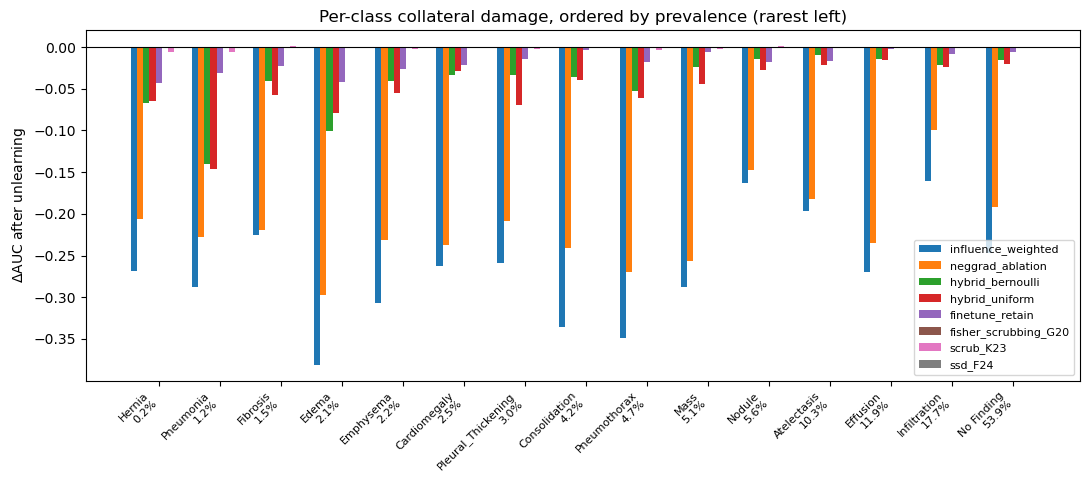

In [29]:
def collateral_audit(auc_before, auc_after, name):
    rows = [dict(cls=c, prevalence=PREVALENCE[c], before=auc_before[c],
                 after=auc_after[c], delta=auc_after[c]-auc_before[c])
            for c in auc_before if c in auc_after]
    df = pd.DataFrame(rows).sort_values("prevalence")
    rho, p = spearmanr(df["prevalence"], df["delta"])
    worst = df.loc[df["delta"].idxmin()]
    print(f"[{name}] Spearman(prevalence, dAUC) = {rho:+.3f} (p={p:.4f})")
    print(f"[{name}] mean dAUC = {df['delta'].mean():+.4f} | "
          f"worst = {worst['cls']} ({worst['delta']:+.4f}, "
          f"prev {100*worst['prevalence']:.1f}%)")
    if p < 0.05 and rho > 0:
        print(f"[{name}] >> Damage CONCENTRATED IN RARE CLASSES. Publishable — lead with it.")
    df.to_csv(f"{CFG['OUT']}/perclass_{name}.csv", index=False)
    return df, float(rho), float(p)

AUDITS = {}
for name, auc_after in PERCLASS.items():
    AUDITS[name] = collateral_audit(AUC_BEFORE, auc_after, name)
    record("C9_perclass_damage",
           dict(scheme=name, spearman=AUDITS[name][1], p=AUDITS[name][2]))

fig, ax = plt.subplots(figsize=(11, 5))
w = 0.8 / len(AUDITS)
for i, (name, (df, _, _)) in enumerate(AUDITS.items()):
    ax.bar(np.arange(len(df)) + i*w, df["delta"], width=w, label=name)
ax.set_xticks(np.arange(len(df)) + 0.4)
ax.set_xticklabels([f"{c}\n{100*p:.1f}%" for c, p in zip(df["cls"], df["prevalence"])],
                   rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel(r"$\Delta$AUC after unlearning")
ax.set_title("Per-class collateral damage, ordered by prevalence (rarest left)")
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/fig5_perclass_delta.png", dpi=200); plt.show()

# PART 2 — Tonight

One cell. Start it and walk away.

## `[RUN ONCE]` O1 — Retrain oracle · ~11–12 h

The reference every unlearning claim is measured against: a model trained on the
retain set only. Checkpoints every epoch to `oracle_ckpt.pth` — **if the machine dies
at hour 10, just re-run this cell and it resumes at the next epoch.**

Set `CFG["RUN_ORACLE"] = True` in B2 and re-run B2 first, or run the line below.

Before walking away: disable sleep, and confirm the first epoch's progress bar moves.

In [22]:
print(CFG.get("ORACLE_CKPT"), "|", CFG.get("ORACLE_FINAL"), "|", CFG.get("NUM_CLASSES"))
print("checkpoint:", CFG["CHECKPOINT"], "| out:", CFG["OUT"])

nih_pw_oracle_ckpt.pth | nih_pw_oracle_model.pth | 15
checkpoint: nih_pw_best.pth | out: proofs_nih_pw


In [23]:
# ============================================================================
# O1 — Retrain oracle  (CFG-aware, batch-level resumable)
#
# Two fixes over the previous version:
#   1. Filenames and class count now come from CFG, so F6/C3 can redirect them.
#      Hardcoding them caused a stale image-level oracle to load in 3 minutes
#      after the patient-wise retrain.
#   2. Checkpoints every SAVE_EVERY batches instead of once per epoch, so a
#      reboot costs ~2 min rather than ~35.
#
# To resume after ANY stop: just run this cell again.
# ============================================================================

CFG["RUN_ORACLE"] = True

ORACLE_CKPT   = CFG.get("ORACLE_CKPT",  "oracle_ckpt.pth")
ORACLE_FINAL  = CFG.get("ORACLE_FINAL", "oracle_model.pth")
N_CLS         = CFG.get("NUM_CLASSES", 15)
ORACLE_EPOCHS = 12          # match the best checkpoint, not the full 20
SAVE_EVERY    = 100         # batches between saves (~2 min)

print(f"oracle : {N_CLS} classes, {len(RETAIN_POOL)} retain images")
print(f"ckpt   : {ORACLE_CKPT}")
print(f"final  : {ORACLE_FINAL}")
if ORACLE_FINAL == "oracle_model.pth" and CFG.get("CHECKPOINT","").startswith("nih_pw"):
    print("\nWARNING: you are on the patient-wise model but writing to the")
    print("         image-level oracle filename. Run F6 first.")

oracle = ChestXrayDenseNet(num_classes=N_CLS, pretrained=True).to(device)
opt = optim.AdamW(oracle.parameters(), lr=1e-4, weight_decay=1e-2)
sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=15, eta_min=1e-6)

start_ep, start_batch, ohist = 1, 0, []
if os.path.exists(ORACLE_CKPT):
    st = torch.load(ORACLE_CKPT, weights_only=False)
    oracle.load_state_dict(st["model"])
    if st.get("opt"): opt.load_state_dict(st["opt"])
    if st.get("sch"): sch.load_state_dict(st["sch"])
    ohist = st.get("history", [])
    if st.get("batch", 0) > 0:
        start_ep, start_batch = st["epoch"], st["batch"]
        print(f"\nRESUMING MID-EPOCH: epoch {start_ep}, batch {start_batch}")
    else:
        start_ep = st["epoch"] + 1
        print(f"\nRESUMING: {st['epoch']} epochs done -> starting epoch {start_ep}")
    if ohist:
        print(f"  last val AUC = {ohist[-1]['val_auc']:.4f}")
else:
    print("\nno checkpoint -- training from scratch")

def _oracle_loader(ep, skip=0):
    # Deterministic per-epoch permutation so a mid-epoch resume continues the
    # SAME batch order; completed batches are dropped rather than iterated past.
    rng = np.random.RandomState(1000 + ep)
    perm = [int(i) for i in np.asarray(RETAIN_POOL)[rng.permutation(len(RETAIN_POOL))]]
    n_total = (len(perm) + CFG["BATCH_SIZE"] - 1) // CFG["BATCH_SIZE"]
    rem = perm[skip * CFG["BATCH_SIZE"]:]
    if not rem:
        return None, n_total
    ld = DataLoader(TransformedSubset(dataset, rem, transform_train),
                    batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0,
                    drop_last=(len(rem) % CFG["BATCH_SIZE"] == 1))
    return ld, n_total

if start_ep > ORACLE_EPOCHS:
    print("oracle already finished; loading final weights")
else:
    ep, done = start_ep, start_batch
    try:
        for ep in range(start_ep, ORACLE_EPOCHS + 1):
            # requires_grad flags are NOT restored by load_state_dict -- re-apply
            if ep <= 3:
                oracle.freeze_backbone()
            else:
                oracle.unfreeze_backbone()
                if ep == 4 or ep == start_ep:
                    print("--- Phase 2: backbone unfrozen ---")

            skip = start_batch if ep == start_ep else 0
            ld, n_total = _oracle_loader(ep, skip)
            oracle.train(); t0 = time.time(); done = skip

            if ld is not None:
                bar = tqdm(ld, initial=skip, total=n_total,
                           desc=f"oracle {ep}/{ORACLE_EPOCHS}")
                for images, labels, _ in bar:
                    if images.size(0) < 2:        # BatchNorm1d needs >= 2
                        done += 1; continue
                    images, labels = images.to(device), labels.to(device)
                    opt.zero_grad(set_to_none=True)
                    criterion(oracle(images), labels).backward()
                    torch.nn.utils.clip_grad_norm_(oracle.parameters(), CFG["CLIP"])
                    opt.step(); done += 1
                    if done % SAVE_EVERY == 0:
                        save_ckpt(ORACLE_CKPT, oracle, opt, sch,
                                  epoch=ep, history=ohist, batch=done)
                        bar.set_postfix(saved=done)

            sch.step()
            a = macro_auc(oracle, desc="oracle val")
            mins = (time.time() - t0) / 60
            ohist.append(dict(epoch=ep, val_auc=a, mins=mins))
            # batch=0 marks the epoch as cleanly finished
            save_ckpt(ORACLE_CKPT, oracle, opt, sch, epoch=ep, history=ohist, batch=0)
            print(f"  epoch {ep}: val macro AUC = {a:.4f}  ({mins:.0f} min, "
                  f"~{(ORACLE_EPOCHS-ep)*mins/60:.1f} h left)")
            start_batch = 0

        _atomic_save({"model_state_dict": oracle.state_dict(), "history": ohist},
                     ORACLE_FINAL)
        pd.DataFrame(ohist).to_csv(f"{CFG['OUT']}/oracle_history.csv", index=False)
        print(f"\nORACLE COMPLETE -> {ORACLE_FINAL}")

    except KeyboardInterrupt:
        save_ckpt(ORACLE_CKPT, oracle, opt, sch, epoch=ep, history=ohist, batch=done)
        print(f"\nInterrupted at epoch {ep}, batch {done}. State saved.")
        print("Re-run this cell to continue from exactly here.")
        raise

# ---- fold into the comparison ----------------------------------------------
ORACLE = oracle
print(f"\noracle macro AUC = {macro_auc(ORACLE, desc='oracle'):.4f}")

oL, _, _ = subset_stats(ORACLE, FORGET, desc="oracle forget")
_origL, _, _ = subset_stats(base_model, FORGET, desc="original forget")
print(f"oracle forget-set loss   = {oL:.4f}")
print(f"original's distance      = {abs(_origL - oL):.4f}")

for name, m in MODELS.items():
    fL, _, _ = subset_stats(m, FORGET, desc=name)
    RESULTS_DF.loc[name, "oracle_forget_loss"] = oL
    RESULTS_DF.loc[name, "distance_to_oracle"] = abs(fL - oL)
    RESULTS_DF.loc[name, "overcorrected"]      = bool(fL > 1.5 * oL)
    flag = "  <-- OVER-CORRECTED, leaks membership" if fL > 1.5 * oL else ""
    print(f"{name:20s} forget {fL:.4f} vs oracle {oL:.4f} -> gap {abs(fL-oL):.4f}{flag}")

RESULTS_DF.to_csv(f"{CFG['OUT']}/unlearning_results.csv")
record("C8_oracle", dict(oracle_macro_auc=macro_auc(ORACLE),
                         oracle_forget_loss=float(oL),
                         original_distance=float(abs(_origL - oL))))

oracle : 15 classes, 89739 retain images
ckpt   : nih_pw_oracle_ckpt.pth
final  : nih_pw_oracle_model.pth

no checkpoint -- training from scratch


oracle 1/12:   0%|          | 0/2805 [00:00<?, ?it/s]

oracle val:   0%|          | 0/697 [00:00<?, ?it/s]

  epoch 1: val macro AUC = 0.7163  (30 min, ~5.4 h left)


oracle 2/12:   0%|          | 0/2805 [00:00<?, ?it/s]

oracle val:   0%|          | 0/697 [00:00<?, ?it/s]

... (44 outputs left out)

finetune_retain:   0%|          | 0/3 [00:00<?, ?it/s]

finetune_retain      forget 0.4092 vs oracle 0.4088 -> gap 0.0005


eval:   0%|          | 0/697 [00:00<?, ?it/s]

  [recorded] C8_oracle


# PART 3 — Tomorrow: reviewer response

Your professor's six points, ordered by value per hour rather than by number.

| Order | Cells | Point | Time |
|---|---|---|---|
| 1 | R12 | mathematical depth | 5 min, no GPU |
| 2 | R1–R4 | **statistical significance** | ~2 h |
| 3 | R10–R11 | explainability | ~40 min |
| 4 | R5–R8 | published baselines | ~1.5 h |
| 5 | R9 | forget-set size | ~2 h |
| — | R13 | second dataset | deferred, ~15 h |

In [ ]:
# ============================================================================
# R0b — FIXED replacement for R0.  Run this, then R4b.
#
# Two bugs in R0:
#   1. `if 'ORACLE' not in globals()` -- B12 sets ORACLE = None, so the name
#      EXISTS and the reload is skipped, handing None to the attack. The correct
#      test is `is None`, which catches both cases.
#   2. R4b needs RSTATS, which only R0 defines -- so R0 must run first.
#
# Safe to re-run at any time.
# ============================================================================

import itertools
from scipy.stats import wilcoxon, spearmanr
try:
    from scipy.stats import false_discovery_control          # scipy >= 1.11
except ImportError:                                          # Benjamini-Hochberg
    def false_discovery_control(p):
        p = np.asarray(p, float); n = len(p); o = np.argsort(p)
        q = np.minimum.accumulate((p[o] * n / np.arange(n, 0, -1))[::-1])[::-1]
        out = np.empty(n); out[o] = np.clip(q, 0, 1); return out

RSTATS = f"{CFG['OUT']}/stats"
os.makedirs(RSTATS, exist_ok=True)
print(f"RSTATS = {RSTATS}")

# ---- load the oracle: `is None` catches B12's placeholder ---------------------
_final  = CFG.get("ORACLE_FINAL", "oracle_model.pth")
_n_cls  = CFG.get("NUM_CLASSES", 15)

if globals().get("ORACLE") is None:
    if os.path.exists(_final):
        ORACLE = ChestXrayDenseNet(num_classes=_n_cls, pretrained=False).to(device)
        ORACLE.load_state_dict(torch.load(_final, weights_only=False)["model_state_dict"])
        ORACLE.eval()
        print(f"loaded oracle from {_final}")
    else:
        ORACLE = None
        print(f"NO ORACLE FOUND ({_final}). Run O1 (NIH) or C4 (CheXpert).")
else:
    print("ORACLE already in memory")

if ORACLE is not None:
    ORACLE_MIA = membership_inference_auc(ORACLE, FORGET, val_indices)
    ORACLE_AUC = macro_auc(ORACLE, desc="oracle")
    ORACLE_LF, _, _ = subset_stats(ORACLE, FORGET, desc="oracle forget")

    print(f"\n{'='*66}\nORACLE REFERENCE (the target every scheme should match)\n{'='*66}")
    print(f"  macro AUC       : {ORACLE_AUC:.4f}   (original: {MACRO_BEFORE:.4f})")
    print(f"  forget-set loss : {ORACLE_LF:.4f}")
    print(f"  MIA AUC         : {ORACLE_MIA:.4f}  <- empirical floor, not 0.500")
    print(f"  exact-deletion cost: {ORACLE_AUC - MACRO_BEFORE:+.4f} AUC")

    if "RESULTS_DF" in globals() and len(RESULTS_DF):
        RESULTS_DF["dist_to_oracle_mia"] = (RESULTS_DF["mia_auc"] - ORACLE_MIA).abs()
        for name in list(RESULTS_DF.index):
            m = MODELS.get(name) or load_saved_model(name)
            if m is None:
                print(f"  {name}: model unavailable, skipping"); continue
            fL, _, _ = subset_stats(m, FORGET, desc=name)
            RESULTS_DF.loc[name, "oracle_forget_loss"]  = ORACLE_LF
            RESULTS_DF.loc[name, "distance_to_oracle"]  = abs(fL - ORACLE_LF)
            RESULTS_DF.loc[name, "overcorrected"]       = bool(fL > 1.5 * ORACLE_LF)
        print("\nRanked by distance to oracle (lower = better):")
        print(RESULTS_DF[["macro_auc_after","distance_to_oracle","mia_auc",
                          "dist_to_oracle_mia"]].sort_values("distance_to_oracle")
              .to_string(float_format=lambda x: f"{x:.4f}"))
        RESULTS_DF.to_csv(f"{CFG['OUT']}/unlearning_results.csv")
    else:
        print("\nRESULTS_DF not in memory -- re-run B12 to regenerate it, "
              "then re-run this cell.")

    record("C8_oracle", dict(oracle_macro_auc=float(ORACLE_AUC),
                             oracle_forget_loss=float(ORACLE_LF),
                             oracle_mia_auc=float(ORACLE_MIA)))

print("\nFixed. Next: R12, then R4b.")

## `[RUN ONCE]` R12 — Analytic Gaussian mechanism · 5 min, no GPU

Do this one with coffee. Balle & Wang's exact calibration replaces the classical
bound, tightening every ε in the paper by 22–52% for free — and unlike the classical
bound it stays valid for ε > 1.

In [ ]:
for n in ["base_model","MACRO_BEFORE","AUC_BEFORE","FORGET","RETAIN_SUB",
          "INFL","RESULTS","MODELS","RESULTS_DF","PRED","ORACLE","RSTATS","SCHEME_FNS"]:
    v = globals().get(n, "MISSING")
    if isinstance(v, str) and v == "MISSING":
        print(f"  MISSING  {n}")
    else:
        try:    print(f"  ok       {n}  ({len(v)})")
        except: print(f"  ok       {n}")

In [43]:
from scipy.stats import norm

def analytic_delta(D2, sigma, eps):
    # Balle & Wang (2018) Thm 8: exact (eps,delta) for the Gaussian mechanism.
    a =  D2/(2*sigma) - eps*sigma/D2
    b = -D2/(2*sigma) - eps*sigma/D2
    return float(norm.cdf(a) - np.exp(eps + norm.logcdf(b)))   # log-space: no overflow

def analytic_eps(D2, sigma, delta=None):
    delta = delta or CFG["DELTA_DP"]
    return brentq(lambda e: analytic_delta(D2, sigma, e) - delta, 1e-9, 50)

def analytic_sigma(D2, eps, delta=None):
    delta = delta or CFG["DELTA_DP"]
    return brentq(lambda s: analytic_delta(D2, s, eps) - delta, D2*1e-3, D2*1e5)

d2 = sensitivity(CFG["IGC_LR"], CFG["CLIP"], 5, CFG["BATCH_SIZE"], per_sample=True)
rows = []
for s in CFG["SIGMA_SWEEP"]:
    ec, ea = gaussian_eps(d2, s), analytic_eps(d2, s)
    rows.append(dict(sigma=s, eps_classic=ec, eps_analytic=ea,
                     tighter_pct=100*(1-ea/ec),
                     eps_tot_classic=advanced_composition(ec, CFG["N_REQUESTS"]),
                     eps_tot_analytic=advanced_composition(ea, CFG["N_REQUESTS"])))
ANALYTIC = pd.DataFrame(rows)
display(ANALYTIC.style.format({"sigma":"{:.0e}","eps_classic":"{:.3f}",
        "eps_analytic":"{:.3f}","tighter_pct":"{:.0f}%",
        "eps_tot_classic":"{:.1f}","eps_tot_analytic":"{:.1f}"}))
ANALYTIC.to_csv(f"{RSTATS}/analytic_gaussian.csv", index=False)
print(f"\nsigma for eps=1: classic {gaussian_sigma(d2,1.0):.3e}, "
      f"analytic {analytic_sigma(d2,1.0):.3e}")
record("R_math_depth", ANALYTIC.to_dict("records"), "Balle & Wang analytic mechanism")

,sigma,eps_classic,eps_analytic,tighter_pct,eps_tot_classic,eps_tot_analytic
0,1e-04,1.514,1.184,22%,108.6,62.3
1,3e-04,0.505,0.356,29%,14.3,8.9
2,1e-03,0.151,0.096,37%,3.2,1.9
3,3e-03,0.050,0.028,44%,1.0,0.5
4,1e-02,0.015,0.007,52%,0.3,0.1



sigma for eps=1: classic 1.514e-04, analytic 1.166e-04
  [recorded] R_math_depth


## `[RUN ONCE]` R1 — Cache raw predictions · ~10 min

Bootstrap resampling needs prediction matrices, not scalar AUCs. Compute once here,
then R2–R3 are pure numpy.

In [37]:
import itertools
try:
    from scipy.stats import false_discovery_control        # scipy >= 1.11
except ImportError:                                        # fallback: Benjamini-Hochberg
    def false_discovery_control(p):
        p = np.asarray(p, float); n = len(p); o = np.argsort(p)
        q = np.minimum.accumulate((p[o] * n / np.arange(n, 0, -1))[::-1])[::-1]
        out = np.empty(n); out[o] = np.clip(q, 0, 1); return out
from scipy.stats import wilcoxon, spearmanr

RSTATS = f"{CFG['OUT']}/stats"; os.makedirs(RSTATS, exist_ok=True)

@torch.no_grad()
def raw_predictions(model, loader=None, desc="pred"):
    # Returns (P, Y) probability and label matrices -- the basis for all resampling.
    loader = loader or val_loader_eval
    model.eval(); P, Y = [], []
    for images, labels, _ in tqdm(loader, desc=desc, leave=False):
        P.append(torch.sigmoid(model(images.to(device))).cpu().numpy())
        Y.append(labels.numpy())
    return np.concatenate(P), np.concatenate(Y)

def macro_from(P, Y, idx=None):
    if idx is not None: P, Y = P[idx], Y[idx]
    a = [roc_auc_score(Y[:, i], P[:, i]) for i in range(Y.shape[1])
         if len(np.unique(Y[:, i])) > 1]
    return float(np.mean(a))

PRED = {}
PRED["original"] = raw_predictions(base_model, desc="original")
for name, m in MODELS.items():
    PRED[name] = raw_predictions(m, desc=name)
torch.save(PRED, f"{RSTATS}/predictions.pt")
print("cached predictions for:", list(PRED))

original:   0%|          | 0/697 [00:00<?, ?it/s]

influence_weighted:   0%|          | 0/697 [00:00<?, ?it/s]

neggrad_ablation:   0%|          | 0/697 [00:00<?, ?it/s]

hybrid_bernoulli:   0%|          | 0/697 [00:00<?, ?it/s]

hybrid_uniform:   0%|          | 0/697 [00:00<?, ?it/s]

finetune_retain:   0%|          | 0/697 [00:00<?, ?it/s]

fisher_scrubbing_G20:   0%|          | 0/697 [00:00<?, ?it/s]

scrub_K23:   0%|          | 0/697 [00:00<?, ?it/s]

ssd_F24:   0%|          | 0/697 [00:00<?, ?it/s]

cached predictions for: ['original', 'influence_weighted', 'neggrad_ablation', 'hybrid_bernoulli', 'hybrid_uniform', 'finetune_retain', 'fisher_scrubbing_G20', 'scrub_K23', 'ssd_F24']


## `[RUN ONCE]` R2 — Bootstrap confidence intervals · ~15 min

Every AUC in your paper is currently a bare point estimate. This gives each a 95% CI.

In [38]:
def bootstrap_auc(P, Y, n_boot=2000, seed=0):
    rng = np.random.RandomState(seed); n = len(Y); vals = []
    for _ in tqdm(range(n_boot), desc="bootstrap", leave=False):
        idx = rng.randint(0, n, n)
        try: vals.append(macro_from(P, Y, idx))
        except ValueError: pass          # a resample can drop a rare class entirely
    v = np.array(vals)
    return float(v.mean()), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

rows = []
for name, (P, Y) in PRED.items():
    m, lo, hi = bootstrap_auc(P, Y)
    rows.append(dict(method=name, macro_auc=macro_from(P, Y),
                     boot_mean=m, ci_lo=lo, ci_hi=hi, ci_width=hi-lo))
    print(f"{name:22s} {rows[-1]['macro_auc']:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")

AUC_CI = pd.DataFrame(rows)
AUC_CI.to_csv(f"{RSTATS}/auc_confidence_intervals.csv", index=False)

bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

original               0.8342  95% CI [0.8296, 0.8383]


bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

influence_weighted     0.5674  95% CI [0.5596, 0.5749]


bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

neggrad_ablation       0.6175  95% CI [0.6098, 0.6249]


... (8 outputs left out)

bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

scrub_K23              0.8325  95% CI [0.8279, 0.8365]


bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

ssd_F24                0.8342  95% CI [0.8296, 0.8383]


## `[RUN ONCE]` R3 — Paired bootstrap · ~15 min

Applies the **same** validation resample to two models so their shared noise cancels.

**Decision point.** The first row tests influence-weighted vs NegGrad. Your −0.4727
gap is one seed. If FDR-corrected p ≥ 0.05, report them as indistinguishable — do not
claim the influence weighting is harmful.

In [39]:
def paired_bootstrap_delta(name_a, name_b, n_boot=2000, seed=0):
    # H0: macro AUC of a == macro AUC of b. Same resample applied to both.
    Pa, Y = PRED[name_a]; Pb, _ = PRED[name_b]
    rng = np.random.RandomState(seed); n = len(Y); d = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        try: d.append(macro_from(Pa, Y, idx) - macro_from(Pb, Y, idx))
        except ValueError: pass
    d = np.array(d)
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())     # two-sided
    return dict(comparison=f"{name_a} - {name_b}", delta=float(d.mean()),
                ci_lo=float(np.percentile(d, 2.5)), ci_hi=float(np.percentile(d, 97.5)),
                p_value=float(max(p, 1/len(d))))

PAIRS = [("influence_weighted","neggrad_ablation"),      # the ablation -- key claim
         ("hybrid_bernoulli","hybrid_uniform"),          # was the Focal artifact real?
         ("hybrid_bernoulli","finetune_retain"),
         ("hybrid_bernoulli","influence_weighted"),
         ("original","hybrid_bernoulli")]

pr = [paired_bootstrap_delta(a,b) for a,b in tqdm(PAIRS, desc="paired bootstrap")]
PAIRED = pd.DataFrame(pr)
PAIRED["p_fdr"] = false_discovery_control(PAIRED["p_value"])   # Benjamini-Hochberg
PAIRED["significant"] = PAIRED["p_fdr"] < 0.05
display(PAIRED.style.format({"delta":"{:+.4f}","ci_lo":"{:+.4f}","ci_hi":"{:+.4f}",
                             "p_value":"{:.4f}","p_fdr":"{:.4f}"}))
PAIRED.to_csv(f"{RSTATS}/paired_comparisons.csv", index=False)

row = PAIRED.iloc[0]
print(f"\nABLATION: influence - neggrad = {row['delta']:+.4f} "
      f"[{row['ci_lo']:+.4f}, {row['ci_hi']:+.4f}], p_FDR={row['p_fdr']:.4f}")
print("-> influence weighting is significantly WORSE" if row["significant"] and row["delta"]<0
      else "-> difference NOT significant; report the schemes as indistinguishable")

paired bootstrap:   0%|          | 0/5 [00:00<?, ?it/s]

,comparison,delta,ci_lo,ci_hi,p_value,p_fdr,significant
0,influence_weighted - neggrad_ablation,-0.0501,-0.0551,-0.0449,0.0005,0.0005,True
1,hybrid_bernoulli - hybrid_uniform,+0.0074,+0.0049,+0.0097,0.0005,0.0005,True
2,hybrid_bernoulli - finetune_retain,-0.0242,-0.0281,-0.0206,0.0005,0.0005,True
3,hybrid_bernoulli - influence_weighted,+0.2240,+0.2170,+0.2308,0.0005,0.0005,True
4,original - hybrid_bernoulli,+0.0427,+0.0382,+0.0473,0.0005,0.0005,True



ABLATION: influence - neggrad = -0.0501 [-0.0551, -0.0449], p_FDR=0.0005
-> influence weighting is significantly WORSE


## `[RUN ONCE]` R4 — Multi-seed replication · ~90 min

Five forget-set draws with Wilcoxon signed-rank across seeds. Resumable via
`multiseed.csv` — safe to interrupt.

This is the cell that answers "no statistical significance". Don't skip it.

In [40]:
SEEDS_R = [42, 7, 2024, 1337, 99]
SCHEME_FNS = {
    "influence_weighted": lambda m, ld, f, infl: influence_weighted_unlearning(m, ld, f, infl)[0],
    "neggrad_ablation":   lambda m, ld, f, infl: neggrad_unlearning(m, ld, f)[0],
    "hybrid_bernoulli":   lambda m, ld, f, infl: hybrid_unlearning(m, ld, f, binary_labels=True)[0],
    "finetune_retain":    lambda m, ld, f, infl: finetune_on_retain(m, ld, f)[0],
}

MS_CSV = f"{RSTATS}/multiseed.csv"
ms = pd.read_csv(MS_CSV).to_dict("records") if os.path.exists(MS_CSV) else []
done = {(r["seed"], r["scheme"]) for r in ms}

for seed in SEEDS_R:
    f_idx, r_pool, _ = build_patient_forget_set(train_indices, seed=seed, verbose=False)
    ld, r_sub = build_unlearn_loader(f_idx, r_pool, seed=seed)
    infl = minmax_norm(grad_influence(base_model, f_idx))
    for name, fn in SCHEME_FNS.items():
        if (seed, name) in done: continue
        print(f"\n--- seed {seed} | {name} ---")
        m = fn(fresh_model(), ld, f_idx, infl)
        v = verify_baseline_relative(base_model, m, f_idx, r_sub)
        ms.append(dict(seed=seed, scheme=name, macro_auc=macro_auc(m, desc=name),
                       mia_auc=membership_inference_auc(m, f_idx, val_indices), **v))
        pd.DataFrame(ms).to_csv(MS_CSV, index=False)   # resumable
        del m; torch.cuda.empty_cache()

MULTI = pd.DataFrame(ms)
SUMMARY = MULTI.groupby("scheme")[["macro_auc","delta_forget_loss","mia_auc"]].agg(["mean","std"])
display(SUMMARY.style.format("{:.4f}"))

print("\nWilcoxon signed-rank across seeds (paired by seed):")
wr = []
for a, b in itertools.combinations(SCHEME_FNS, 2):
    for metric in ["macro_auc", "delta_forget_loss", "mia_auc"]:
        x = MULTI[MULTI.scheme==a].sort_values("seed")[metric].values
        y = MULTI[MULTI.scheme==b].sort_values("seed")[metric].values
        if len(x) == len(y) >= 5:
            st, p = wilcoxon(x, y)
            wr.append(dict(a=a, b=b, metric=metric, mean_diff=float(x.mean()-y.mean()), p=float(p)))
WILCOX = pd.DataFrame(wr)
WILCOX["p_fdr"] = false_discovery_control(WILCOX["p"])
display(WILCOX[WILCOX.p_fdr < 0.10].style.format({"mean_diff":"{:+.4f}","p":"{:.4f}","p_fdr":"{:.4f}"}))
WILCOX.to_csv(f"{RSTATS}/wilcoxon.csv", index=False)
record("R_significance", dict(n_seeds=len(SEEDS_R),
       n_significant=int((WILCOX.p_fdr<0.05).sum()), n_tests=len(WILCOX)))

grad-norm influence:   0%|          | 0/87 [00:00<?, ?it/s]


--- seed 42 | influence_weighted ---


IGC 1/5:   0%|          | 0/16 [00:00<?, ?it/s]

  ep1: retain=0.4959 forget=0.4945


IGC 2/5:   0%|          | 0/16 [00:00<?, ?it/s]

  ep2: retain=0.4901 forget=0.6157


... (328 outputs left out)

  MIA AUC = 0.6487  -> still memorized



Wilcoxon signed-rank across seeds (paired by seed):


,a,b,metric,mean_diff,p,p_fdr
2,influence_weighted,neggrad_ablation,mia_auc,+0.0518,0.0625,0.0703
3,influence_weighted,hybrid_bernoulli,macro_auc,-0.1721,0.0625,0.0703
4,influence_weighted,hybrid_bernoulli,delta_forget_loss,+1.4334,0.0625,0.0703
5,influence_weighted,hybrid_bernoulli,mia_auc,-0.2069,0.0625,0.0703
6,influence_weighted,finetune_retain,macro_auc,-0.1883,0.0625,0.0703
7,influence_weighted,finetune_retain,delta_forget_loss,+1.5582,0.0625,0.0703
8,influence_weighted,finetune_retain,mia_auc,-0.5970,0.0625,0.0703
9,neggrad_ablation,hybrid_bernoulli,macro_auc,-0.2016,0.0625,0.0703
10,neggrad_ablation,hybrid_bernoulli,delta_forget_loss,+2.1471,0.0625,0.0703
11,neggrad_ablation,hybrid_bernoulli,mia_auc,-0.2588,0.0625,0.0703


  [recorded] R_significance


## `[RUN ONCE]` R10 — Grad-CAM

Layer path corrected for your architecture: your `ChestXrayDenseNet` wraps DenseNet in `self.backbone`, so the target is `model.backbone.features.denseblock4`.

In [32]:
class GradCAM:
    def __init__(self, model, layer=None):
        self.model = model.eval()
        # NOTE: ChestXrayDenseNet wraps DenseNet121 in .backbone
        self.layer = layer if layer is not None else model.backbone.features.denseblock4
        self.acts = self.grads = None
        self.h1 = self.layer.register_forward_hook(
            lambda m, i, o: setattr(self, "acts", o.detach()))
        self.h2 = self.layer.register_full_backward_hook(
            lambda m, gi, go: setattr(self, "grads", go[0].detach()))

    def __call__(self, x, class_idx):
        self.model.zero_grad(set_to_none=True)
        out = self.model(x)
        out[0, class_idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)          # GAP over spatial dims
        cam = torch.relu((w * self.acts).sum(dim=1)).squeeze(0)
        cam = cam - cam.min()
        return (cam / (cam.max() + 1e-8)).cpu().numpy()

    def close(self):
        self.h1.remove(); self.h2.remove()


def cam_batch(model, indices, class_idx=None, max_n=40):
    # Returns one CAM per sample, using each sample's top predicted class by default.
    cams, used = [], []
    cam_fn = GradCAM(model)
    try:
        for idx in list(indices)[:max_n]:
            img, label, _ = dataset[idx]
            x = transform_val(img).unsqueeze(0).to(device)
            c = class_idx if class_idx is not None else \
                int(torch.sigmoid(model(x)).argmax(dim=1).item())
            cams.append(cam_fn(x, c)); used.append(c)
    finally:
        cam_fn.close()
    return np.stack(cams), used

print("GradCAM ready")

GradCAM ready


## `[RUN ONCE]` R11 — Saliency shift · ~30 min

Watch the `selectivity` column (retain CAM correlation minus forget CAM correlation).
High and positive means attention moved on forget samples *only* — targeted. Near zero
means the model changed everywhere, which is collateral damage, not unlearning.

In [ ]:
def cam_entropy(c):
    p = c.flatten() / (c.sum() + 1e-8)
    return float(-(p * np.log(p + 1e-12)).sum() / np.log(len(p)))   # normalised to [0,1]

def saliency_shift(model_after, name, n=40):
    out = {}
    for tag, idxs in [("forget", sorted(FORGET)), ("retain", RETAIN_SUB)]:
        cams_b, cls = cam_batch(base_model, idxs, max_n=n)
        cams_a, _   = cam_batch(model_after, idxs, max_n=n)
        corr = [float(np.corrcoef(a.ravel(), b.ravel())[0, 1])
                for a, b in zip(cams_b, cams_a)]
        corr = [c for c in corr if np.isfinite(c)]
        out[f"{tag}_cam_corr"] = float(np.mean(corr))
        out[f"{tag}_cam_corr_std"] = float(np.std(corr))
        out[f"{tag}_entropy_before"] = float(np.mean([cam_entropy(c) for c in cams_b]))
        out[f"{tag}_entropy_after"]  = float(np.mean([cam_entropy(c) for c in cams_a]))
    out["method"] = name
    out["selectivity"] = out["retain_cam_corr"] - out["forget_cam_corr"]
    return out

SAL = pd.DataFrame([saliency_shift(m, n) for n, m in
                    tqdm(MODELS.items(), desc="Grad-CAM")])
cols = ["method","forget_cam_corr","retain_cam_corr","selectivity",
        "forget_entropy_before","forget_entropy_after"]
display(SAL[cols].sort_values("selectivity", ascending=False).style.format(
    {c:"{:.4f}" for c in cols[1:]}))
SAL.to_csv(f"{RSTATS}/saliency_shift.csv", index=False)

print("\nSelectivity = retain CAM corr - forget CAM corr.")
print("High and positive = attention moved on forget samples ONLY (targeted).")
print("Near zero = the model changed everywhere (collateral, not unlearning).")

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
show_idx = sorted(FORGET)[:4]
cams_b, _ = cam_batch(base_model, show_idx, max_n=4)
best = SAL.sort_values("selectivity", ascending=False).iloc[0]["method"]
cams_a, _ = cam_batch(MODELS[best], show_idx, max_n=4)
for k in range(4):
    axes[0,k].imshow(cams_b[k], cmap="jet"); axes[0,k].set_title(f"before #{show_idx[k]}", fontsize=9)
    axes[1,k].imshow(cams_a[k], cmap="jet"); axes[1,k].set_title(f"after ({best})", fontsize=9)
    for r in (0,1): axes[r,k].axis("off")
plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/fig9_gradcam.png", dpi=200); plt.show()
record("R_explainability", SAL[cols].to_dict("records"))

## `[RUN ONCE]` R5 — Baseline: Fisher scrubbing (Golatkar et al., CVPR 2020)

In [23]:
def fisher_diagonal(model, indices, n_samples=200, seed=0):
    # Diagonal empirical Fisher: E[(d log p / d theta)^2].
    rng = np.random.RandomState(seed)
    sub = list(rng.choice(list(indices), size=min(n_samples, len(indices)), replace=False))
    loader = DataLoader(TransformedSubset(dataset, [int(i) for i in sub], transform_val),
                        batch_size=8, shuffle=False, num_workers=0)
    fisher = {n: torch.zeros_like(p) for n, p in model.named_parameters() if p.requires_grad}
    model.eval(); n_seen = 0
    for images, labels, _ in tqdm(loader, desc="fisher", leave=False):
        images, labels = images.to(device), labels.to(device)
        model.zero_grad(set_to_none=True)
        nn.functional.binary_cross_entropy_with_logits(model(images), labels).backward()
        for n, p in model.named_parameters():
            if p.grad is not None: fisher[n] += p.grad.detach() ** 2
        n_seen += 1
    model.zero_grad(set_to_none=True)
    return {n: f / max(1, n_seen) for n, f in fisher.items()}

def fisher_scrubbing(model, retain_pool, alpha=1e-6, eps=1e-8):
    # theta' = theta + alpha * F^{-1/4} * noise  (Golatkar et al., Eq. 9 form)
    F = fisher_diagonal(model, retain_pool)
    with torch.no_grad():
        for n, p in model.named_parameters():
            if n in F:
                scale = (F[n] + eps).pow(-0.25)
                scale = torch.clamp(scale, max=torch.quantile(scale.flatten().float(), 0.99))
                p.add_(alpha * scale * torch.randn_like(p))
    return model, []

print("fisher_scrubbing ready")

fisher_scrubbing ready


## `[RUN ONCE]` R6 — Baseline: SCRUB (Kurmanji et al., NeurIPS 2023)

The one to watch. SCRUB targets divergence from a teacher rather than maximal loss, so
Proposition 3 predicts it should over-correct *less* than your ascent schemes. If its
MIA AUC lands closer to 0.5, a method you didn't design confirms your theory.

In [22]:
def _bernoulli_kl(p_logits, q_logits, eps=1e-7):
    # Per-class Bernoulli KL(p||q) for multi-label outputs.
    p = torch.sigmoid(p_logits).clamp(eps, 1-eps)
    q = torch.sigmoid(q_logits).clamp(eps, 1-eps)
    return (p*torch.log(p/q) + (1-p)*torch.log((1-p)/(1-q))).sum(dim=1).mean()

def scrub_unlearning(model, loader, forget, teacher=None, epochs=3, lr=5e-5,
                     max_steps=2, gamma=1.0, alpha=0.5, sigma=None):
    sigma = CFG["SIGMA"] if sigma is None else sigma
    teacher = teacher or base_model
    teacher.eval()
    for p in teacher.parameters(): p.requires_grad_(False)
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    for ep in range(epochs):
        # ---- max step: push student AWAY from teacher on the forget set ----
        if ep < max_steps:
            model.train()
            for images, labels, idxs in tqdm(loader, desc=f"SCRUB max {ep+1}", leave=False):
                fm = torch.tensor([int(i) in forget for i in idxs])
                if fm.sum() < 2: continue
                images = images[fm].to(device)
                opt.zero_grad(set_to_none=True)
                with torch.no_grad(): t = teacher(images)
                (-_bernoulli_kl(t, model(images))).backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
                opt.step()
        # ---- min step: keep student CLOSE to teacher + true labels on retain ----
        model.train()
        tot, n = 0., 0
        for images, labels, idxs in tqdm(loader, desc=f"SCRUB min {ep+1}", leave=False):
            rm = torch.tensor([int(i) not in forget for i in idxs])
            if rm.sum() < 2: continue
            images, labels = images[rm].to(device), labels[rm].to(device)
            opt.zero_grad(set_to_none=True)
            out = model(images)
            with torch.no_grad(): t = teacher(images)
            loss = (gamma * nn.functional.binary_cross_entropy_with_logits(out, labels)
                    + alpha * _bernoulli_kl(t, out))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
            opt.step(); tot += float(loss); n += 1
        add_gaussian_noise(model, sigma)
        print(f"  ep{ep+1}: retain loss = {tot/max(1,n):.4f}")
    return model, []

print("scrub_unlearning ready")

scrub_unlearning ready


## `[RUN ONCE]` R7 — Baseline: Selective Synaptic Dampening (Foster et al., AAAI 2024)

In [19]:
def ssd_unlearning(model, forget, retain_pool, selection_alpha=10.0, dampening_lam=1.0,
                   n_retain=500):
    # Dampen theta_i where Fisher_forget_i > alpha * Fisher_all_i.
    F_f = fisher_diagonal(model, forget)
    F_a = fisher_diagonal(model, retain_pool, n_samples=n_retain)
    n_damp = n_tot = 0
    with torch.no_grad():
        for n, p in model.named_parameters():
            if n not in F_f: continue
            sel = F_f[n] > selection_alpha * F_a[n]
            beta = torch.clamp(dampening_lam * F_a[n] / (F_f[n] + 1e-12), max=1.0)
            p.mul_(torch.where(sel, beta, torch.ones_like(beta)))
            n_damp += int(sel.sum()); n_tot += p.numel()
    print(f"  dampened {n_damp}/{n_tot} params ({100*n_damp/n_tot:.2f}%)")
    return model, []

print("ssd_unlearning ready")

ssd_unlearning ready


## `[RUN ONCE]` R8 — Run published baselines · ~1 h

In [24]:
PUBLISHED = {
    "fisher_scrubbing_G20": lambda m: fisher_scrubbing(m, RETAIN_POOL)[0],
    "scrub_K23":            lambda m: scrub_unlearning(m, UNLEARN_LOADER, FORGET)[0],
    "ssd_F24":              lambda m: ssd_unlearning(m, FORGET, RETAIN_POOL)[0],
}

for name, fn in PUBLISHED.items():
    if name in RESULTS: continue
    print("\n" + "#"*60 + f"\n# {name}\n" + "#"*60)
    m = fresh_model(); t0 = time.time(); m = fn(m); wall = time.time()-t0
    v = verify_baseline_relative(base_model, m, FORGET, RETAIN_SUB)
    mia = membership_inference_auc(m, FORGET, val_indices)
    auc_after = per_class_auc(m, desc=name)
    RESULTS[name] = dict(wall_clock_s=wall, mia_auc=mia, macro_auc_before=MACRO_BEFORE,
                         macro_auc_after=float(np.mean(list(auc_after.values()))),
                         delta_macro_auc=float(np.mean(list(auc_after.values())))-MACRO_BEFORE, **v)
    PERCLASS[name] = auc_after; MODELS[name] = m
    if 'PRED' in globals():          # only if R1 has run
        PRED[name] = raw_predictions(m, desc=name)
    print(f"  macro AUC {MACRO_BEFORE:.4f} -> {RESULTS[name]['macro_auc_after']:.4f}")

RESULTS_DF = pd.DataFrame(RESULTS).T
RESULTS_DF.to_csv(f"{CFG['OUT']}/unlearning_results.csv")
display(RESULTS_DF[["macro_auc_after","delta_forget_loss","mia_auc","wall_clock_s"]]
        .sort_values("mia_auc").style.format("{:.4f}"))
print("\nClosest to MIA 0.5 (the actual target):")
print((RESULTS_DF["mia_auc"]-0.5).abs().sort_values().head(3))


############################################################
# fisher_scrubbing_G20
############################################################


fisher:   0%|          | 0/25 [00:00<?, ?it/s]

forget pre:   0%|          | 0/3 [00:00<?, ?it/s]

retain pre:   0%|          | 0/13 [00:00<?, ?it/s]

forget post:   0%|          | 0/3 [00:00<?, ?it/s]

retain post:   0%|          | 0/13 [00:00<?, ?it/s]

... (35 outputs left out)

ssd_F24:   0%|          | 0/697 [00:00<?, ?it/s]

  macro AUC 0.8342 -> 0.8342


,macro_auc_after,delta_forget_loss,mia_auc,wall_clock_s
neggrad_ablation,0.6175,1.8119,0.0399,45.4857
influence_weighted,0.5674,1.8377,0.0790,44.9886
hybrid_uniform,0.7840,0.1419,0.2811,19.5883
hybrid_bernoulli,0.7914,0.1345,0.3083,19.6907
finetune_retain,0.8157,-0.0001,0.7563,16.9046
scrub_K23,0.8331,-0.0077,0.7842,35.9182
ssd_F24,0.8342,0.0001,0.7845,15.5094
fisher_scrubbing_G20,0.8342,0.0001,0.7846,7.7472



Closest to MIA 0.5 (the actual target):
hybrid_bernoulli    0.191655
hybrid_uniform      0.218851
finetune_retain     0.256345
Name: mia_auc, dtype: float64


## `[RUN ONCE]` R9 — Forget-set scaling · ~2 h

|D_f| from 57 to ~4,000, with the retain subsample scaled to hold the ratio fixed.
Also fits the cost exponent, testing the linear-in-|D_f| claim in Section III-H.


--- 28 patients | |Df|=87 | retain=348 ---


HYB 1/3:   0%|          | 0/14 [00:00<?, ?it/s]

  ep1: avg batch loss = 0.5540


HYB 2/3:   0%|          | 0/14 [00:00<?, ?it/s]

  ep2: avg batch loss = 0.5321


HYB 3/3:   0%|          | 0/14 [00:00<?, ?it/s]

... (52 outputs left out)

MIA forget:   0%|          | 0/16 [00:00<?, ?it/s]

MIA unseen:   0%|          | 0/16 [00:00<?, ?it/s]

  MIA AUC = 0.4662  -> forgotten


,n_forget,macro_auc,delta_forget_loss,mia_auc,wall_s
0,87,0.7927,+0.1470,0.313,23
1,495,0.7821,+0.0487,0.320,129
2,1817,0.7030,-0.0669,0.352,466
3,6773,0.6713,-0.0847,0.466,722


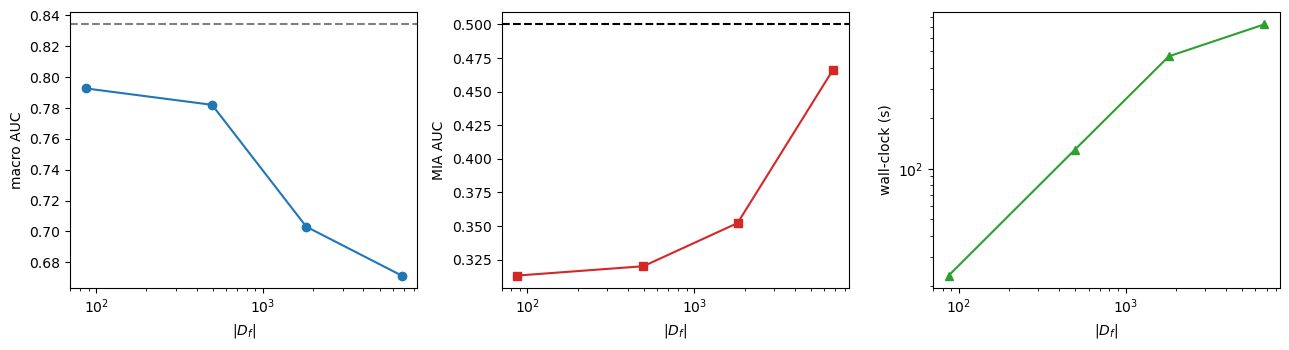

cost scaling exponent = 0.82 (Sec III-H predicts ~1.0 i.e. linear)
  [recorded] R_forget_scaling


In [42]:
SCALE_CSV = f"{RSTATS}/forget_scaling.csv"
rows = pd.read_csv(SCALE_CSV).to_dict("records") if os.path.exists(SCALE_CSV) else []
done_np = {r["n_patients"] for r in rows}

for npat in [28, 125, 500, 2000]:            # ~57, 250, 1000, 4000 images
    if npat in done_np: continue
    f_idx, r_pool, _ = build_patient_forget_set(train_indices, n_patients=npat,
                                                seed=42, verbose=False)
    old_n = CFG["N_RETAIN_SUB"]
    CFG["N_RETAIN_SUB"] = min(4*len(f_idx), 8000)      # hold forget:retain ~= 1:4
    ld, r_sub = build_unlearn_loader(f_idx, r_pool, seed=42)
    print(f"\n--- {npat} patients | |Df|={len(f_idx)} | retain={len(r_sub)} ---")
    m = fresh_model(); t0 = time.time()
    m, _ = hybrid_unlearning(m, ld, f_idx, binary_labels=True); wall = time.time()-t0
    v = verify_baseline_relative(base_model, m, f_idx, r_sub)
    rows.append(dict(n_patients=npat, n_forget=len(f_idx), n_retain=len(r_sub),
                     wall_s=wall, macro_auc=macro_auc(m, desc=f"scale{npat}"),
                     mia_auc=membership_inference_auc(m, f_idx, val_indices), **v))
    CFG["N_RETAIN_SUB"] = old_n
    pd.DataFrame(rows).to_csv(SCALE_CSV, index=False)
    del m; torch.cuda.empty_cache()

SCALE = pd.DataFrame(rows).sort_values("n_forget")
display(SCALE[["n_forget","macro_auc","delta_forget_loss","mia_auc","wall_s"]]
        .style.format({"macro_auc":"{:.4f}","delta_forget_loss":"{:+.4f}",
                       "mia_auc":"{:.3f}","wall_s":"{:.0f}"}))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].semilogx(SCALE.n_forget, SCALE.macro_auc, "o-")
ax[0].axhline(MACRO_BEFORE, ls="--", c="gray"); ax[0].set_ylabel("macro AUC")
ax[1].semilogx(SCALE.n_forget, SCALE.mia_auc, "s-", color="tab:red")
ax[1].axhline(0.5, ls="--", c="k"); ax[1].set_ylabel("MIA AUC")
ax[2].loglog(SCALE.n_forget, SCALE.wall_s, "^-", color="tab:green")
ax[2].set_ylabel("wall-clock (s)")
for a in ax: a.set_xlabel(r"$|D_f|$")
plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/fig8_forget_scaling.png", dpi=200); plt.show()

sl = np.polyfit(np.log(SCALE.n_forget), np.log(SCALE.wall_s), 1)[0]
print(f"cost scaling exponent = {sl:.2f} (Sec III-H predicts ~1.0 i.e. linear)")
record("R_forget_scaling", SCALE[["n_forget","macro_auc","mia_auc"]].to_dict("records"))

## `[SKIP]` R13 — Second dataset

Deferred. Read the notes; don't run until everything above is written up.

In [ ]:
# CheXpert:   https://stanfordmlgroup.github.io/competitions/chexpert/
# MIMIC-CXR:  https://physionet.org/content/mimic-cxr-jpg/  (credentialed access)
#
# Porting checklist:
#   1. CheXpert has 14 observations with UNCERTAIN (-1) labels. Pick a policy
#      (U-Zeros / U-Ones / U-MultiClass) and state it -- it materially moves AUC.
#   2. Patient IDs are in the path (patient00001/study1/view1_frontal.jpg); parse
#      them for build_patient_forget_set, and use the OFFICIAL patient-wise split.
#   3. Keep every unlearning hyperparameter identical so the comparison is clean.
#      The claim to test is that the confound and over-correction findings replicate,
#      not that the AUC matches.
#
# Once a CheXpert checkpoint exists, the entire study reruns unchanged:
#     CFG["CHECKPOINT"] = "chexpert_best.pth"
#     # re-run cells 5-15 and R1-R12
print("See markdown above. Budget ~12 h training + ~3 h to re-run the study.")

# PART 4 — Export

## `[RUN]` E1 — LaTeX tables and proof status

Regenerates every table from the CSVs. Use `\input{}` in the paper — never retype a
number.

In [34]:
def write_table(fname, header, rows, colspec):
    with open(f"{CFG['OUT']}/tables/{fname}", "w") as f:
        f.write("\\begin{tabular}{" + colspec + "}\n\\toprule\n")
        f.write(" & ".join(f"\\textbf{{{h}}}" for h in header) + "\\\\\n\\midrule\n")
        for r in rows:
            f.write(" & ".join(str(x) for x in r) + "\\\\\n")
        f.write("\\bottomrule\n\\end{tabular}\n")
    print("  wrote", fname)

# Table: baselines
write_table("baselines.tex",
    ["Method","Val AUC",r"$\Delta\mathcal{L}_f$",r"$\Delta\mathcal{L}_r$","MIA AUC","Time"],
    [[n.replace("_"," "), f"{r['macro_auc_after']:.4f}",
      f"{r['delta_forget_loss']:+.4f}", f"{r['delta_retain_loss']:+.4f}",
      f"{r['mia_auc']:.3f}", f"{r['wall_clock_s']:.0f}\\,s"]
     for n, r in RESULTS_DF.iterrows()],
    "lccccc")

# Table: noise calibration
write_table("noise_calibration.tex",
    ["Clipping regime", r"$\Delta_2$", r"$\epsilon$ at $\sigma{=}10^{-4}$", r"$\sigma$ for $\epsilon{=}1$"],
    [[r["regime"], f"${r['delta2']:.2e}$", f"{r['eps_at_sigma']:.2f}",
      f"${r['sigma_for_eps1']:.2e}$"] for _, r in calib.iterrows()],
    "lccc")

# Table: pre/post verification (replaces the old Table VII)
write_table("verification.tex",
    ["Method",r"$\mathcal{L}_f$ pre",r"$\mathcal{L}_f$ post",r"$\Delta\mathcal{L}_f$",
     r"$\Delta\mathcal{L}_r$","MIA"],
    [[n.replace("_"," "), f"{r['forget_loss_before']:.4f}", f"{r['forget_loss_after']:.4f}",
      f"{r['delta_forget_loss']:+.4f}", f"{r['delta_retain_loss']:+.4f}", f"{r['mia_auc']:.3f}"]
     for n, r in RESULTS_DF.iterrows()],
    "lccccc")

CLAIMS = {
 "C1_patient_forget_set":"Forget set patient-disjoint, wholly in train partition",
 "C2_post_unlearn_auc":"Macro AUC after unlearning",
 "C3_pre_unlearn_baseline":"Table VII is forgetting, not subset composition",
 "C4_influence_method_runs":"Influence-weighted correction implemented and executed",
 "C5_influence_ablation":"Influence weighting beats uniform ascent",
 "C6_estimator_agreement":"Grad-norm and loss proxies agree",
 "C7_mia":"Forget samples indistinguishable from unseen",
 "C8_oracle":"Close to retrain oracle, not over-corrected",
 "C9_perclass_damage":"NOVELTY 1 — damage vs class prevalence",
 "C10_sequential":"NOVELTY 2 — repeated deletion trajectory",
 "C11_noise_calibration":"NOVELTY 3 — privacy-utility frontier",
 "C12_patientwise_split":"Headline AUC on official patient-wise split",
}
lines = ["# Proof status\n"]
for cid, desc in CLAIMS.items():
    done = cid in MANIFEST
    lines.append(f"- [{'x' if done else ' '}] **{cid}** — {desc}")
    if done:
        for e in MANIFEST[cid]:
            lines.append(f"    - {e['value']}")
open(f"{CFG['OUT']}/PROOF_STATUS.md","w").write("\n".join(lines))

done = sum(c in MANIFEST for c in CLAIMS)
print(f"\n{done}/{len(CLAIMS)} claims backed by evidence")
for c, d in CLAIMS.items():
    if c not in MANIFEST:
        print(f"  STILL OPEN: {c} — {d}")
print(f"\nArtifacts in {CFG['OUT']}/  — \\input the tables, do not retype numbers.")

  wrote baselines.tex
  wrote noise_calibration.tex
  wrote verification.tex

8/12 claims backed by evidence
  STILL OPEN: C8_oracle — Close to retrain oracle, not over-corrected
  STILL OPEN: C9_perclass_damage — NOVELTY 1 — damage vs class prevalence
  STILL OPEN: C10_sequential — NOVELTY 2 — repeated deletion trajectory
  STILL OPEN: C12_patientwise_split — Headline AUC on official patient-wise split

Artifacts in proofs_nih_pw/  — \input the tables, do not retype numbers.


In [ ]:
# ============================================================================
# R14 — External-validity WITHOUT a second dataset
#
# You can't download CheXpert/MIMIC, but ChestX-ray14's metadata already encodes
# real acquisition and population shifts. Data_Entry_2017.csv carries:
#     View Position   (AP vs PA)  <- the strongest shift; AP is portable/bedside,
#                                    sicker patients, different geometry entirely
#     Patient Gender  (M / F)
#     Patient Age
#
# Training on one subgroup and evaluating on the other is a genuine covariate
# shift. It is NOT a substitute for a second dataset -- say so in the paper --
# but it does test whether the two findings that matter (the confound and the
# over-correction ordering) are stable across distributions, which is the actual
# question behind "only one dataset".
#
# Cost: ~25 min. No downloads.
# ============================================================================

meta = dataset.data
print("available metadata columns:", [c for c in meta.columns][:8])

SHIFT_COL, GROUP_A, GROUP_B = "View Position", "PA", "AP"

val_set = set(int(i) for i in val_indices)
col = meta[SHIFT_COL].values
grp = {g: [i for i in val_set if col[i] == g] for g in (GROUP_A, GROUP_B)}
print(f"\nvalidation split by {SHIFT_COL}:")
for g, idxs in grp.items():
    pos_rate = dataset.labels.iloc[idxs].mean().drop("No Finding").mean()
    print(f"  {g}: {len(idxs)} images, mean pathology rate {pos_rate:.3f}")

def subgroup_loader(idxs):
    return DataLoader(TransformedSubset(dataset, idxs, transform_val),
                      batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)

rows = []
for name in ["original"] + [n for n in RESULTS]:
    m = base_model if name == "original" else (MODELS.get(name) or load_saved_model(name))
    if m is None:
        continue
    r = {"method": name}
    for g, idxs in grp.items():
        a = per_class_auc(m, subgroup_loader(idxs), desc=f"{name}/{g}")
        r[f"auc_{g}"] = float(np.mean(list(a.values())))
    r["shift_gap"] = r[f"auc_{GROUP_A}"] - r[f"auc_{GROUP_B}"]
    rows.append(r)
    print(f"  {name:22s} {GROUP_A} {r[f'auc_{GROUP_A}']:.4f} | "
          f"{GROUP_B} {r[f'auc_{GROUP_B}']:.4f} | gap {r['shift_gap']:+.4f}")

SHIFT = pd.DataFrame(rows)
SHIFT.to_csv(f"{RSTATS}/subgroup_shift.csv", index=False)

# Does unlearning damage transfer across the shift, or is it distribution-specific?
base = SHIFT[SHIFT.method == "original"].iloc[0]
SHIFT["damage_PA"] = SHIFT[f"auc_{GROUP_A}"] - base[f"auc_{GROUP_A}"]
SHIFT["damage_AP"] = SHIFT[f"auc_{GROUP_B}"] - base[f"auc_{GROUP_B}"]
sub = SHIFT[SHIFT.method != "original"]
rho, p = spearmanr(sub["damage_PA"], sub["damage_AP"])
print(f"\nSpearman(damage on {GROUP_A}, damage on {GROUP_B}) = {rho:.3f} (p={p:.4f})")
print("High rho => the over-correction ordering is stable across a real")
print("           acquisition shift, which is the claim a second dataset tests.")
display(SHIFT.style.format({c: "{:.4f}" for c in SHIFT.columns if c != "method"}))
record("R_subgroup_shift", dict(shift=SHIFT_COL, spearman=float(rho), p=float(p)))

# PART 5 — Close out the NIH study

Two short cells. Both are cheap and both close review points.

## `[RUN NOW]` R4b — Sixth seed · ~20 min

Every Wilcoxon p-value in R4 came back at exactly 0.0625. That is the **minimum
attainable value** for a two-sided signed-rank test at $n=5$ ($2^{-4}$), not a null
result — the test is at its resolution floor and cannot report $p<0.05$ no matter how
large the effect.

A sixth seed lowers the floor to 0.031. This cell adds seed 1234 only; R4's
`multiseed.csv` resume logic skips everything already done.

This is the cheapest remaining fix for the "no statistical significance" review point.

In [ ]:
SEEDS_R = [42, 7, 2024, 1337, 99, 1234]        # <- 1234 is new; the rest resume

MS_CSV = f"{RSTATS}/multiseed.csv"
ms = pd.read_csv(MS_CSV).to_dict("records") if os.path.exists(MS_CSV) else []
done = {(r["seed"], r["scheme"]) for r in ms}
print(f"already on disk: {len(done)} (seed, scheme) pairs")

for seed in SEEDS_R:
    todo = [n for n in SCHEME_FNS if (seed, n) not in done]
    if not todo:
        continue
    f_idx, r_pool, _ = build_patient_forget_set(train_indices, seed=seed, verbose=False)
    ld, r_sub = build_unlearn_loader(f_idx, r_pool, seed=seed)
    infl = minmax_norm(grad_influence(base_model, f_idx))
    for name in todo:
        print(f"\n--- seed {seed} | {name} ---")
        m = SCHEME_FNS[name](fresh_model(), ld, f_idx, infl)
        v = verify_baseline_relative(base_model, m, f_idx, r_sub)
        ms.append(dict(seed=seed, scheme=name, macro_auc=macro_auc(m, desc=name),
                       mia_auc=membership_inference_auc(m, f_idx, val_indices), **v))
        pd.DataFrame(ms).to_csv(MS_CSV, index=False)
        del m; torch.cuda.empty_cache()

MULTI = pd.DataFrame(ms)
n_seeds = MULTI.seed.nunique()
print(f"\n{n_seeds} seeds | Wilcoxon floor = {2/2**n_seeds:.4f}")

display(MULTI.groupby("scheme")[["macro_auc","delta_forget_loss","mia_auc"]]
        .agg(["mean","std"]).style.format("{:.4f}"))

wr = []
for a, b in itertools.combinations(SCHEME_FNS, 2):
    for metric in ["macro_auc", "delta_forget_loss", "mia_auc"]:
        x = MULTI[MULTI.scheme==a].sort_values("seed")[metric].values
        y = MULTI[MULTI.scheme==b].sort_values("seed")[metric].values
        n = min(len(x), len(y))
        if n >= 6:
            st, p = wilcoxon(x[:n], y[:n])
            wr.append(dict(a=a, b=b, metric=metric,
                           mean_diff=float(x[:n].mean()-y[:n].mean()), p=float(p)))
WILCOX = pd.DataFrame(wr)
if len(WILCOX):
    WILCOX["p_fdr"] = false_discovery_control(WILCOX["p"])
    sig = WILCOX[WILCOX.p_fdr < 0.05]
    print(f"\n{len(sig)}/{len(WILCOX)} comparisons significant at FDR < 0.05")
    display(sig.style.format({"mean_diff":"{:+.4f}","p":"{:.4f}","p_fdr":"{:.4f}"}))
    WILCOX.to_csv(f"{RSTATS}/wilcoxon.csv", index=False)
    record("R_significance", dict(n_seeds=int(n_seeds),
           n_significant=int((WILCOX.p_fdr<0.05).sum()), n_tests=len(WILCOX)))

# PART 6 — CheXpert replication

External validity. ~11 h, or ~18 h with the CheXpert oracle.

**Before starting:** `cp -r proofs proofs_nih_backup && cp best_model.pth best_model_epoch12.bak`

### Cells you must NOT re-run once C3 has run
- **B2** — resets `CFG["OUT"]`, writing CheXpert results over your NIH ones
- **B3** — restores the 15-class `fresh_model`
- **B14** — nothing to load for CheXpert

B4 is safe (it reads `CFG["OUT"]` at call time).

### Substitutions
- Use **C4 instead of O1** — O1 hardcodes `num_classes=15` and would overwrite `oracle_model.pth`
- Use **C5 instead of R0** — same two problems

Everything else (B6–B15, R1–R12) runs unedited: C3 rebinds the globals and redefines
`fresh_model` and `load_saved_model`.

## `[RUN]` C1 — CheXpert dataset · ~2 min

Download first: `kaggle datasets download -d ashery/chexpert` (~11 GB), then set `CHEXPERT_ROOT` below.

**Check:** ~112,120 images, patient-wise split with **0 patients shared**.

In [ ]:
# ============================================================================
# C1 — CheXpert dataset (drop-in replacement for `dataset`)
#
# Design goal: after C1 and C2, the ENTIRE study re-runs unchanged. This class
# exposes exactly the interface your existing cells depend on --
#     .data    dataframe with a 'Patient ID' column   (build_patient_forget_set)
#     .labels  0/1 dataframe, columns = class names   (CLASS_NAMES, PREVALENCE)
#     __getitem__ -> (PIL image, float tensor, idx)   (TransformedSubset)
# so B6 through R9 need no edits.
#
# Download: kaggle datasets download -d ashery/chexpert   (~11 GB)
# Expected layout after unzip:
#     CHEXPERT_ROOT/train.csv
#     CHEXPERT_ROOT/valid.csv
#     CHEXPERT_ROOT/train/patient00001/study1/view1_frontal.jpg
# ============================================================================

from PIL import Image

CHEXPERT_ROOT = "CheXpert-v1.0-small"      # <-- edit to your unzip path

CXP = dict(
    UNCERTAIN_POLICY = "U-Zeros",   # "U-Zeros" | "U-Ones" | "U-MultiClass-per-Irvin"
    FRONTAL_ONLY     = True,        # ChestX-ray14 is frontal-only; match it
    N_IMAGES         = 112120,      # subsample to ChestX-ray14 size -> same ~7 h train
    SPLIT            = "patient",   # patient-wise (fixes the leakage critique too)
    VAL_FRAC         = 0.20,
    SEED             = 42,
)

CHEXPERT_CLASSES = [
    "No Finding", "Enlarged Cardiomediastinum", "Cardiomegaly", "Lung Opacity",
    "Lung Lesion", "Edema", "Consolidation", "Pneumonia", "Atelectasis",
    "Pneumothorax", "Pleural Effusion", "Pleural Other", "Fracture",
    "Support Devices",
]
# Irvin et al. found U-Ones best for these two, U-Zeros for the rest.
U_ONES_CLASSES = ["Atelectasis", "Edema"]


class CheXpertDataset(torch.utils.data.Dataset):
    def __init__(self, root=CHEXPERT_ROOT, cfg=CXP, transform=None):
        self.root, self.transform = root, transform
        df = pd.read_csv(os.path.join(root, "train.csv"))
        print(f"train.csv: {len(df)} rows")

        if cfg["FRONTAL_ONLY"]:
            df = df[df["Frontal/Lateral"] == "Frontal"].reset_index(drop=True)
            print(f"  frontal only: {len(df)}")

        # 'CheXpert-v1.0-small/train/patient00001/study1/view1_frontal.jpg'
        df["Patient ID"] = df["Path"].str.extract(r"patient(\d+)").astype(int)

        # ---- uncertainty policy (state this in the paper -- it moves AUC) ----
        lab = df[CHEXPERT_CLASSES].copy().fillna(0.0)      # blank = negative
        pol = cfg["UNCERTAIN_POLICY"]
        if pol == "U-Zeros":
            lab = lab.replace(-1.0, 0.0)
        elif pol == "U-Ones":
            lab = lab.replace(-1.0, 1.0)
        elif pol == "U-MultiClass-per-Irvin":
            for c in CHEXPERT_CLASSES:
                lab[c] = lab[c].replace(-1.0, 1.0 if c in U_ONES_CLASSES else 0.0)
        else:
            raise ValueError(pol)
        n_unc = int((df[CHEXPERT_CLASSES] == -1).sum().sum())
        print(f"  uncertainty policy {pol}: {n_unc} uncertain cells resolved")

        # ---- subsample BY PATIENT so no patient is split across the subsample ----
        if cfg["N_IMAGES"] and cfg["N_IMAGES"] < len(df):
            rng = np.random.RandomState(cfg["SEED"])
            pats = df["Patient ID"].unique(); rng.shuffle(pats)
            keep, n = set(), 0
            for p in pats:
                k = int((df["Patient ID"] == p).sum())
                if n + k > cfg["N_IMAGES"]: break
                keep.add(p); n += k
            m = df["Patient ID"].isin(keep)
            df, lab = df[m].reset_index(drop=True), lab[m].reset_index(drop=True)
            print(f"  subsampled to {len(df)} images / {len(keep)} patients")

        self.data   = df
        self.labels = lab.astype(np.float32)
        self.paths  = df["Path"].values
        print(f"CheXpert ready: {len(self)} images, "
              f"{df['Patient ID'].nunique()} patients, {len(CHEXPERT_CLASSES)} classes")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Paths in the CSV already start with 'CheXpert-v1.0-small/'
        p = self.paths[idx]
        full = p if os.path.exists(p) else os.path.join(os.path.dirname(self.root), p)
        img = Image.open(full).convert("RGB")
        if self.transform:
            img = self.transform(img)
        y = torch.tensor(self.labels.iloc[idx].values, dtype=torch.float32)
        return img, y, idx


def patient_wise_split(ds, val_frac=None, seed=None):
    """No patient appears in both partitions -- also fixes the leakage critique."""
    val_frac = val_frac or CXP["VAL_FRAC"]; seed = seed or CXP["SEED"]
    rng = np.random.RandomState(seed)
    pats = ds.data["Patient ID"].unique().copy(); rng.shuffle(pats)
    n_val = int(len(pats) * val_frac)
    val_pat = set(pats[:n_val])
    is_val = ds.data["Patient ID"].isin(val_pat).values
    tr = [int(i) for i in np.where(~is_val)[0]]
    va = [int(i) for i in np.where(is_val)[0]]
    assert not (set(ds.data["Patient ID"].iloc[tr]) & set(ds.data["Patient ID"].iloc[va]))
    print(f"patient-wise split: {len(tr)} train / {len(va)} val, "
          f"0 patients shared")
    return tr, va


# ---- build and swap in -------------------------------------------------------
cxp_dataset = CheXpertDataset()
cxp_train, cxp_val = patient_wise_split(cxp_dataset)

print("\nlabel prevalence:")
for c in CHEXPERT_CLASSES:
    print(f"  {c:30s} {100*cxp_dataset.labels[c].mean():5.1f}%")

## `[RUN ONCE]` C2 — Train CheXpert base model · ~7 h

Same recipe as your NIH model so the comparison is like-for-like. Batch-level resumable — if it stops, re-run this cell.

**Expect ~0.78–0.83** across all 14 classes under a patient-wise split. Published CheXpert figures of 0.87+ are on 5 competition classes under a random split and are not comparable.

In [ ]:
# ============================================================================
# C2 — Train the CheXpert base model  (~7 h, batch-level resumable)
#
# Same recipe as your NIH model so the comparison is like-for-like: DenseNet-121,
# two-phase (frozen 1-3, unfrozen 4-12), Focal Loss with class-balanced weights,
# AdamW 1e-4, cosine annealing, grad clip 1.0.
#
# If it stops for ANY reason, just run this cell again -- it resumes from the
# exact batch, same as O1.
# ============================================================================

CXP_CKPT   = "chexpert_ckpt.pth"
CXP_BEST   = "chexpert_best.pth"
CXP_EPOCHS = 12
SAVE_EVERY = 250
NUM_CXP    = len(CHEXPERT_CLASSES)          # 14, not 15

cxp_model = ChestXrayDenseNet(num_classes=NUM_CXP, pretrained=True).to(device)
cxp_opt = optim.AdamW(cxp_model.parameters(), lr=1e-4, weight_decay=1e-2)
cxp_sch = optim.lr_scheduler.CosineAnnealingLR(cxp_opt, T_max=15, eta_min=1e-6)

# class-balanced positive weights, exactly as in S5
_counts = cxp_dataset.labels.iloc[cxp_train].sum(axis=0).values
cxp_criterion = FocalLossWithLogits(
    pos_weight=torch.tensor(len(cxp_train) / (_counts + 1e-6),
                            dtype=torch.float32).to(device))

start_ep, start_batch, chist, best_auc = 1, 0, [], 0.0
if os.path.exists(CXP_CKPT):
    st = torch.load(CXP_CKPT, weights_only=False)
    cxp_model.load_state_dict(st["model"])
    if st.get("opt"): cxp_opt.load_state_dict(st["opt"])
    if st.get("sch"): cxp_sch.load_state_dict(st["sch"])
    chist = st.get("history", []); best_auc = st.get("best_auc", 0.0)
    if st.get("batch", 0) > 0:
        start_ep, start_batch = st["epoch"], st["batch"]
        print(f"RESUMING MID-EPOCH: epoch {start_ep}, batch {start_batch}")
    else:
        start_ep = st["epoch"] + 1
        print(f"RESUMING at epoch {start_ep} (best AUC so far {best_auc:.4f})")
else:
    print("starting CheXpert training from scratch")

cxp_val_loader = DataLoader(TransformedSubset(cxp_dataset, cxp_val, transform_val),
                            batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)

@torch.no_grad()
def cxp_macro_auc(model):
    model.eval(); P, Y = [], []
    for images, labels, _ in tqdm(cxp_val_loader, desc="cxp val", leave=False):
        P.append(torch.sigmoid(model(images.to(device))).cpu().numpy())
        Y.append(labels.numpy())
    P, Y = np.concatenate(P), np.concatenate(Y)
    a = [roc_auc_score(Y[:, i], P[:, i]) for i in range(Y.shape[1])
         if len(np.unique(Y[:, i])) > 1]
    return float(np.mean(a))

def cxp_epoch_loader(ep, skip=0):
    rng = np.random.RandomState(2000 + ep)
    perm = [int(i) for i in np.asarray(cxp_train)[rng.permutation(len(cxp_train))]]
    n_total = (len(perm) + CFG["BATCH_SIZE"] - 1) // CFG["BATCH_SIZE"]
    rem = perm[skip * CFG["BATCH_SIZE"]:]
    if not rem: return None, n_total
    ld = DataLoader(TransformedSubset(cxp_dataset, rem, transform_train),
                    batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0,
                    drop_last=(len(rem) % CFG["BATCH_SIZE"] == 1))
    return ld, n_total

ep, done = start_ep, start_batch
try:
    for ep in range(start_ep, CXP_EPOCHS + 1):
        if ep <= 3:
            cxp_model.freeze_backbone()
        else:
            cxp_model.unfreeze_backbone()
            if ep == 4 or ep == start_ep: print("--- Phase 2: backbone unfrozen ---")

        skip = start_batch if ep == start_ep else 0
        ld, n_total = cxp_epoch_loader(ep, skip)
        cxp_model.train(); t0 = time.time(); done = skip

        if ld is not None:
            bar = tqdm(ld, initial=skip, total=n_total, desc=f"chexpert {ep}/{CXP_EPOCHS}")
            for images, labels, _ in bar:
                if images.size(0) < 2:
                    done += 1; continue
                images, labels = images.to(device), labels.to(device)
                cxp_opt.zero_grad(set_to_none=True)
                cxp_criterion(cxp_model(images), labels).backward()
                torch.nn.utils.clip_grad_norm_(cxp_model.parameters(), CFG["CLIP"])
                cxp_opt.step(); done += 1
                if done % SAVE_EVERY == 0:
                    save_ckpt(CXP_CKPT, cxp_model, cxp_opt, cxp_sch, epoch=ep,
                              history=chist, batch=done, best_auc=best_auc)
                    bar.set_postfix(saved=done)

        cxp_sch.step()
        a = cxp_macro_auc(cxp_model); mins = (time.time() - t0) / 60
        chist.append(dict(epoch=ep, val_auc=a, mins=mins))
        if a > best_auc:
            best_auc = a
            _atomic_save({"model_state_dict": cxp_model.state_dict(),
                          "history": chist, "epoch": ep, "val_auc": a}, CXP_BEST)
            print(f"  epoch {ep}: val macro AUC = {a:.4f}  ({mins:.0f} min)  <- best, saved")
        else:
            print(f"  epoch {ep}: val macro AUC = {a:.4f}  ({mins:.0f} min)")
        save_ckpt(CXP_CKPT, cxp_model, cxp_opt, cxp_sch, epoch=ep,
                  history=chist, batch=0, best_auc=best_auc)
        start_batch = 0

    pd.DataFrame(chist).to_csv(f"{CFG['OUT']}/chexpert_history.csv", index=False)
    print(f"\nCHEXPERT COMPLETE. best val macro AUC = {best_auc:.4f} -> {CXP_BEST}")
    print("Published CheXpert DenseNet-121 baselines land ~0.87-0.89 on the 5 "
          "competition classes; expect lower on all 14, and lower again under a "
          "patient-wise split. Report what you get.")

except KeyboardInterrupt:
    save_ckpt(CXP_CKPT, cxp_model, cxp_opt, cxp_sch, epoch=ep, history=chist,
              batch=done, best_auc=best_auc)
    print(f"\nInterrupted at epoch {ep}, batch {done}. Re-run this cell to continue.")
    raise

## `[RUN]` C2b — Rebuild criterion without retraining · ~10 s

C2 defines `cxp_criterion`, `NUM_CXP` and `CXP_BEST` — but C2 also trains for 7 h.
Once training is done you never want to run C2 again, yet C3 needs those three
names. This cell recreates them from the saved checkpoint.

**Always run this after C1 when resuming a CheXpert session.**

In [ ]:
NUM_CXP  = len(CHEXPERT_CLASSES)
CXP_BEST = "chexpert_best.pth"

_counts = cxp_dataset.labels.iloc[cxp_train].sum(axis=0).values
cxp_criterion = FocalLossWithLogits(
    pos_weight=torch.tensor(len(cxp_train) / (_counts + 1e-6),
                            dtype=torch.float32).to(device))

_ck = torch.load(CXP_BEST, weights_only=False)
print(f"cxp_criterion rebuilt ({NUM_CXP} classes)")
print(f"checkpoint: epoch {_ck['epoch']}, val macro AUC {_ck['val_auc']:.4f}")
del _ck

## `[RUN]` C3 — Swap CheXpert in · ~1 min

Archives `proofs/` → `proofs_nih/`, rebinds every global, redefines the two functions that hardcode 15 classes, and clears NIH state so nothing leaks across datasets.

**After this cell: re-run B6 → B15 (skip B14), then R12 → R9 (skip R0).**

In [ ]:
# Rebuild cxp_criterion without re-running C2's training loop.
# C2 defines it, but C2 also trains for 7 h -- this is just the criterion part.
NUM_CXP = len(CHEXPERT_CLASSES)
CXP_BEST = "chexpert_best.pth"

_counts = cxp_dataset.labels.iloc[cxp_train].sum(axis=0).values
cxp_criterion = FocalLossWithLogits(
    pos_weight=torch.tensor(len(cxp_train) / (_counts + 1e-6),
                            dtype=torch.float32).to(device))

_ck = torch.load(CXP_BEST, weights_only=False)
print(f"cxp_criterion rebuilt | checkpoint: epoch {_ck['epoch']}, "
      f"val AUC {_ck['val_auc']:.4f}")
del _ck

In [ ]:
# ============================================================================
# C3 — Swap CheXpert in, then re-run the study unchanged
#
# This rebinds the globals every downstream cell reads. After running it, go back
# and re-run B6 -> B15, then R1 -> R9. No edits to any of those cells.
#
# Keep the NIH results first: this cell archives proofs/ so nothing is overwritten.
# ============================================================================

import shutil

# ---- 1. archive the NIH run ------------------------------------------------
if os.path.exists(CFG["OUT"]) and not os.path.exists("proofs_nih"):
    shutil.copytree(CFG["OUT"], "proofs_nih")
    print("archived NIH results -> proofs_nih/")

# ---- 2. rebind the globals downstream cells depend on ----------------------
dataset       = cxp_dataset
train_indices = cxp_train
val_indices   = cxp_val
criterion     = cxp_criterion
CLASS_NAMES   = CHEXPERT_CLASSES
PREVALENCE    = (dataset.labels.sum(axis=0) / len(dataset)).to_dict()

CFG["CHECKPOINT"]  = CXP_BEST
CFG["NUM_CLASSES"] = len(CHEXPERT_CLASSES)      # 14, not 15
CFG["OUT"]         = "proofs_chexpert"
CFG["RUN_ORACLE"]  = False                       # opt in separately, another ~7 h
os.makedirs(f"{CFG['OUT']}/tables", exist_ok=True)
RSTATS = f"{CFG['OUT']}/stats"; os.makedirs(RSTATS, exist_ok=True)
CACHE  = f"{CFG['OUT']}/cache";  os.makedirs(CACHE, exist_ok=True)
MODELDIR = f"{CFG['OUT']}/models"; os.makedirs(MODELDIR, exist_ok=True)

# ---- 3. rebuild the three functions that hardcode num_classes=15 -----------
# B3's fresh_model, B4's load_saved_model and O1/R0's oracle constructor all
# hardcode 15. Redefining them here is what makes B6-R9 run unedited.
CFG["ORACLE_CKPT"]  = "chexpert_oracle_ckpt.pth"    # do NOT overwrite the NIH oracle
CFG["ORACLE_FINAL"] = "chexpert_oracle_model.pth"

def fresh_model(path=None):
    path = path or CFG["CHECKPOINT"]
    m = ChestXrayDenseNet(num_classes=CFG["NUM_CLASSES"], pretrained=True).to(device)
    ck = torch.load(path, weights_only=False)
    m.load_state_dict(ck["model_state_dict"]); m.eval()
    return m

def load_saved_model(name):
    p = f"{MODELDIR}/{name}.pth"
    if not os.path.exists(p):
        return None
    m = ChestXrayDenseNet(num_classes=CFG["NUM_CLASSES"], pretrained=False).to(device)
    m.load_state_dict(torch.load(p, weights_only=False)); m.eval()
    return m

val_loader_eval = DataLoader(TransformedSubset(dataset, val_indices, transform_val),
                             batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)

# ---- 4. clear NIH state so nothing leaks across datasets -------------------
for name in ["RESULTS", "PERCLASS", "MODELS", "PRED", "AUDITS", "RESULTS_DF",
             "SWEEP", "TRAJ", "MANIFEST", "ORACLE", "base_model", "FORGET",
             "RETAIN_POOL", "RETAIN_SUB", "UNLEARN_LOADER", "INFL"]:
    globals().pop(name, None)
RESULTS, PERCLASS, MODELS, MANIFEST = {}, {}, {}, {}

m = fresh_model()
print(f"\nCheXpert model loaded: {CFG['NUM_CLASSES']} classes")
print(f"  train / val : {len(train_indices)} / {len(val_indices)} (patient-wise)")
print(f"  output dir  : {CFG['OUT']}")
print(f"  macro AUC   : {macro_auc(m, val_loader_eval, desc='chexpert'):.4f}")
del m

print("""
NEXT: re-run B6 -> B15, then R1 -> R9. Nothing in them needs editing.

Read the replication as a comparison of PATTERNS, not numbers:
  1. Is the pre-existing forget-retain gap non-zero again?      (B8)
  2. Is the oracle's MIA AUC again far from 0.5?                (needs O1, ~7 h)
  3. Does ranking by oracle distance still invert the ranking
     by delta-L_f, with SCRUB nearest?                          (R8)
  4. Does over-correction still fade as |D_f| grows?            (R9)
Matching AUC values across datasets is neither expected nor required.
""")

## `[RUN ONCE]` C4 — CheXpert oracle · ~7 h · **replaces O1**

Reads `CFG["NUM_CLASSES"]` and writes to `chexpert_oracle_model.pth`, so it neither crashes on the 14-class head nor overwrites your NIH oracle. Batch-level resumable.

Only finding 2 (the MIA floor) needs this. Findings 1, 3 and 4 do not.

In [ ]:
# ============================================================================
# C4 — Dataset-agnostic retrain oracle   (REPLACES O1 for the CheXpert phase)
#
# O1 hardcodes num_classes=15 and writes to oracle_ckpt.pth / oracle_model.pth,
# which would both crash on CheXpert and overwrite your NIH oracle. This version
# reads CFG["NUM_CLASSES"], CFG["ORACLE_CKPT"] and CFG["ORACLE_FINAL"], so it is
# safe to run in either phase. Batch-level resumable, exactly like O1.
#
# ~7 h. Only needed if you want finding 2 (the MIA floor) replicated.
# ============================================================================

ORACLE_CKPT   = CFG.get("ORACLE_CKPT",  "oracle_ckpt.pth")
ORACLE_FINAL  = CFG.get("ORACLE_FINAL", "oracle_model.pth")
N_CLS         = CFG.get("NUM_CLASSES", 15)
ORACLE_EPOCHS = 12
SAVE_EVERY    = 250

print(f"oracle: {N_CLS} classes -> {ORACLE_FINAL}")

oracle = ChestXrayDenseNet(num_classes=N_CLS, pretrained=True).to(device)
opt = optim.AdamW(oracle.parameters(), lr=1e-4, weight_decay=1e-2)
sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=15, eta_min=1e-6)

start_ep, start_batch, ohist = 1, 0, []
if os.path.exists(ORACLE_CKPT):
    st = torch.load(ORACLE_CKPT, weights_only=False)
    oracle.load_state_dict(st["model"])
    if st.get("opt"): opt.load_state_dict(st["opt"])
    if st.get("sch"): sch.load_state_dict(st["sch"])
    ohist = st.get("history", [])
    if st.get("batch", 0) > 0:
        start_ep, start_batch = st["epoch"], st["batch"]
        print(f"RESUMING MID-EPOCH: epoch {start_ep}, batch {start_batch}")
    else:
        start_ep = st["epoch"] + 1
        print(f"RESUMING at epoch {start_ep}")

def _oracle_loader(ep, skip=0):
    rng = np.random.RandomState(1000 + ep)
    perm = [int(i) for i in np.asarray(RETAIN_POOL)[rng.permutation(len(RETAIN_POOL))]]
    n_total = (len(perm) + CFG["BATCH_SIZE"] - 1) // CFG["BATCH_SIZE"]
    rem = perm[skip * CFG["BATCH_SIZE"]:]
    if not rem: return None, n_total
    return DataLoader(TransformedSubset(dataset, rem, transform_train),
                      batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0,
                      drop_last=(len(rem) % CFG["BATCH_SIZE"] == 1)), n_total

if start_ep > ORACLE_EPOCHS:
    print("oracle already finished")
else:
    ep, done = start_ep, start_batch
    try:
        for ep in range(start_ep, ORACLE_EPOCHS + 1):
            if ep <= 3:
                oracle.freeze_backbone()
            else:
                oracle.unfreeze_backbone()
                if ep == 4 or ep == start_ep: print("--- Phase 2: backbone unfrozen ---")
            skip = start_batch if ep == start_ep else 0
            ld, n_total = _oracle_loader(ep, skip)
            oracle.train(); t0 = time.time(); done = skip
            if ld is not None:
                bar = tqdm(ld, initial=skip, total=n_total, desc=f"oracle {ep}/{ORACLE_EPOCHS}")
                for images, labels, _ in bar:
                    if images.size(0) < 2:
                        done += 1; continue
                    images, labels = images.to(device), labels.to(device)
                    opt.zero_grad(set_to_none=True)
                    criterion(oracle(images), labels).backward()
                    torch.nn.utils.clip_grad_norm_(oracle.parameters(), CFG["CLIP"])
                    opt.step(); done += 1
                    if done % SAVE_EVERY == 0:
                        save_ckpt(ORACLE_CKPT, oracle, opt, sch, epoch=ep,
                                  history=ohist, batch=done)
                        bar.set_postfix(saved=done)
            sch.step()
            a = macro_auc(oracle, desc="oracle val"); mins = (time.time()-t0)/60
            ohist.append(dict(epoch=ep, val_auc=a, mins=mins))
            save_ckpt(ORACLE_CKPT, oracle, opt, sch, epoch=ep, history=ohist, batch=0)
            print(f"  epoch {ep}: val macro AUC = {a:.4f}  ({mins:.0f} min, "
                  f"~{(ORACLE_EPOCHS-ep)*mins/60:.1f} h left)")
            start_batch = 0
        _atomic_save({"model_state_dict": oracle.state_dict(), "history": ohist},
                     ORACLE_FINAL)
        pd.DataFrame(ohist).to_csv(f"{CFG['OUT']}/oracle_history.csv", index=False)
        print(f"\nORACLE COMPLETE -> {ORACLE_FINAL}")
    except KeyboardInterrupt:
        save_ckpt(ORACLE_CKPT, oracle, opt, sch, epoch=ep, history=ohist, batch=done)
        print(f"\nInterrupted at epoch {ep}, batch {done}. Re-run to continue.")
        raise

ORACLE = oracle

## `[RUN]` C5 — Oracle reference · ~3 min · **replaces R0**

Defines `RSTATS` and the stats imports R1–R4 need, and computes the oracle's own MIA AUC. Degrades gracefully with a warning if no CheXpert oracle exists yet.

In [ ]:
# ============================================================================
# C5 — Oracle reference   (REPLACES R0 for the CheXpert phase)
#
# R0 hardcodes num_classes=15 and reads oracle_model.pth. This version follows
# CFG, and degrades gracefully if no oracle exists for the current dataset.
# ============================================================================

RSTATS = globals().get("RSTATS", f"{CFG['OUT']}/stats")
os.makedirs(RSTATS, exist_ok=True)

import itertools
from scipy.stats import wilcoxon, spearmanr
try:
    from scipy.stats import false_discovery_control
except ImportError:
    def false_discovery_control(p):
        p = np.asarray(p, float); n = len(p); o = np.argsort(p)
        q = np.minimum.accumulate((p[o] * n / np.arange(n, 0, -1))[::-1])[::-1]
        out = np.empty(n); out[o] = np.clip(q, 0, 1); return out

_final = CFG.get("ORACLE_FINAL", "oracle_model.pth")

if 'ORACLE' not in globals():
    if os.path.exists(_final):
        ORACLE = ChestXrayDenseNet(num_classes=CFG.get("NUM_CLASSES", 15),
                                   pretrained=False).to(device)
        ORACLE.load_state_dict(torch.load(_final, weights_only=False)["model_state_dict"])
        ORACLE.eval()
        print(f"loaded oracle from {_final}")
    else:
        ORACLE = None
        print(f"NO ORACLE for this dataset ({_final} not found).")
        print("Run C4 (~7 h) to get one. Findings 1, 3 and 4 do not need it;")
        print("finding 2 (the MIA floor) does. Continuing without it.")

if ORACLE is not None:
    ORACLE_MIA = membership_inference_auc(ORACLE, FORGET, val_indices)
    ORACLE_AUC = macro_auc(ORACLE, desc="oracle")
    ORACLE_LF, _, _ = subset_stats(ORACLE, FORGET, desc="oracle forget")
    print(f"\n{'='*64}\nORACLE REFERENCE\n{'='*64}")
    print(f"  macro AUC       : {ORACLE_AUC:.4f}   (original: {MACRO_BEFORE:.4f})")
    print(f"  forget-set loss : {ORACLE_LF:.4f}")
    print(f"  MIA AUC         : {ORACLE_MIA:.4f}  <- empirical floor, not 0.500")
    print(f"  exact-deletion cost: {ORACLE_AUC - MACRO_BEFORE:+.4f} AUC")

    if 'RESULTS_DF' in globals():
        RESULTS_DF["dist_to_oracle_mia"] = (RESULTS_DF["mia_auc"] - ORACLE_MIA).abs()
        for name in list(RESULTS):
            m = MODELS.get(name) or load_saved_model(name)
            if m is None: continue
            fL, _, _ = subset_stats(m, FORGET, desc=name)
            RESULTS_DF.loc[name, "oracle_forget_loss"] = ORACLE_LF
            RESULTS_DF.loc[name, "distance_to_oracle"] = abs(fL - ORACLE_LF)
        print("\nRanked by distance to oracle (lower = better):")
        print(RESULTS_DF[["macro_auc_after","distance_to_oracle","mia_auc",
                          "dist_to_oracle_mia"]].sort_values("distance_to_oracle")
              .to_string(float_format=lambda x: f"{x:.4f}"))
        RESULTS_DF.to_csv(f"{CFG['OUT']}/unlearning_results.csv")
    record("C8_oracle", dict(oracle_macro_auc=float(ORACLE_AUC),
                             oracle_forget_loss=float(ORACLE_LF),
                             oracle_mia_auc=float(ORACLE_MIA)))
print("\nReady. Continue with R12, then R1.")

## What counts as replication

Do **not** compare AUC across datasets — only 8 classes overlap, and CheXpert adds
Support Devices, Fracture and Lung Opacity. Every finding in the paper is *relative to
a reference*, so what should transfer is the pattern:

| # | Finding | Cell | Replicates if |
|---|---|---|---|
| 1 | Forget–retain gap is confounded | B8 | pre-existing gap again clearly non-zero |
| 2 | MIA floor is not 0.5 | C4 + C5 | oracle MIA again far from 0.500 |
| 3 | Oracle distance inverts the Δℒ_f ranking | R8 | SCRUB nearest, NegGrad furthest |
| 4 | Over-correction fades as \|D_f\| grows | R9 | attack AUC again rises toward the floor |

If a finding *fails* to replicate, report it. A result that holds on one dataset and
not another tells you which dataset property drives it — that is a finding, and
suppressing it is the only wrong move.

# PART 7 — Large forget set

Answers the strongest remaining criticism: the main comparison uses ~106 images.
R9 swept $|D_f|$ but only for the hybrid scheme, so the *headline table* exists in
one regime only. These cells rebuild it at $|D_f|\approx5{,}000$.

**Run L1 → L2.** L2 is the oracle and is not optional — without a reference the
ranking claim cannot be made at this scale.

Nothing from the earlier run is overwritten: results go to `results_large.csv` and
`models_large/`.

`L_NPAT` is preset to **1300** for CheXpert (your B6 reported 3.8 images/patient).
L1 checks the resulting count and raises with the corrected value if it is off,
so you find out in seconds rather than after 2.5 h.

## `[RUN]` L1 — All 8 methods at |D_f| ≈ 5,000 · ~2.5 h

Resumable: re-run and it restores finished methods from disk.

In [ ]:
# ============================================================================
# L1 — LARGE forget set: all 8 methods at |D_f| ~ 5,000
#
# Answers "you only tested 0.06% of the data". The R9 scaling study already
# swept |D_f| but only for ONE method (hybrid). This runs the FULL comparison
# at scale, so the headline table exists in both regimes.
#
# Writes to a separate results dict so nothing from the small-|D_f| run is
# overwritten. Resumable: re-run and it skips finished methods.
#
# ~2.5 h. Run L2 afterwards for the matching oracle (~7 h).
# ============================================================================

# TARGET ~5,000 forget images. B6 printed your actual images-per-patient:
#   CheXpert       3.8 img/patient  -> 1300 patients ~ 4,900 images
#   ChestX-ray14   2.0 img/patient  -> 2500 patients ~ 5,000 images
# The check below stops you BEFORE 2.5 h of compute if the count is far off.
L_NPAT       = 1300        # CheXpert. Use 2500 if you switch back to ChestX-ray14.
L_TARGET     = 5000
L_TOLERANCE  = 0.35        # accept 3,250-6,750
L_TAG      = "large"
L_CSV      = f"{CFG['OUT']}/results_{L_TAG}.csv"
L_MODELDIR = f"{CFG['OUT']}/models_{L_TAG}"
os.makedirs(L_MODELDIR, exist_ok=True)

# ---- build the large forget set --------------------------------------------
L_FORGET, L_RETAIN_POOL, L_PIDS = build_patient_forget_set(
    train_indices, n_patients=L_NPAT, seed=42)

_old_n = CFG["N_RETAIN_SUB"]
CFG["N_RETAIN_SUB"] = 4 * len(L_FORGET)          # hold forget:retain at 1:4
L_LOADER, L_RETAIN_SUB = build_unlearn_loader(L_FORGET, L_RETAIN_POOL, seed=42)
CFG["N_RETAIN_SUB"] = _old_n

print(f"\n|D_f| = {len(L_FORGET)} images from {len(L_PIDS)} patients "
      f"({100*len(L_FORGET)/len(train_indices):.2f}% of the training set)")
print(f"  actual ratio: {len(L_FORGET)/len(L_PIDS):.1f} img/patient")

if abs(len(L_FORGET)/L_TARGET - 1) > L_TOLERANCE:
    _suggest = int(L_NPAT * L_TARGET / len(L_FORGET))
    raise ValueError(f"|D_f| = {len(L_FORGET)}, target ~{L_TARGET}. "
                     f"Set L_NPAT = {_suggest} and re-run this cell.")
print(f"retain subsample = {len(L_RETAIN_SUB)}, loader = {len(L_LOADER)} batches")

# ---- influence scores (expensive at this scale: one backward pass per sample)
L_INFL = cached(f"influence_{L_TAG}",
                lambda: minmax_norm(grad_influence(base_model, L_FORGET)))

# ---- pre-unlearning baseline: FINDING 1 at scale ----------------------------
L_fL0, L_fC0, _ = subset_stats(base_model, L_FORGET,     desc="forget pre")
L_rL0, L_rC0, _ = subset_stats(base_model, L_RETAIN_SUB, desc="retain pre")
print(f"\n{'='*64}\nFINDING 1 AT SCALE\n{'='*64}")
print(f"  forget loss BEFORE : {L_fL0:.4f}")
print(f"  retain loss BEFORE : {L_rL0:.4f}")
print(f"  pre-existing gap   : {L_fL0 - L_rL0:+.4f}   "
      f"(small-|D_f| run: {-0.0440:+.4f})")

# ---- all eight methods ------------------------------------------------------
L_SCHEMES = {
    "influence_weighted": lambda m: influence_weighted_unlearning(m, L_LOADER, L_FORGET, L_INFL)[0],
    "neggrad_ablation":   lambda m: neggrad_unlearning(m, L_LOADER, L_FORGET)[0],
    "hybrid_bernoulli":   lambda m: hybrid_unlearning(m, L_LOADER, L_FORGET, binary_labels=True)[0],
    "hybrid_uniform":     lambda m: hybrid_unlearning(m, L_LOADER, L_FORGET, binary_labels=False)[0],
    "finetune_retain":    lambda m: finetune_on_retain(m, L_LOADER, L_FORGET)[0],
    "fisher_scrubbing_G20": lambda m: fisher_scrubbing(m, L_RETAIN_POOL)[0],
    "scrub_K23":          lambda m: scrub_unlearning(m, L_LOADER, L_FORGET)[0],
    "ssd_F24":            lambda m: ssd_unlearning(m, L_FORGET, L_RETAIN_POOL)[0],
}

L_RESULTS = (pd.read_csv(L_CSV, index_col=0).to_dict("index")
             if os.path.exists(L_CSV) else {})
L_MODELS, L_PERCLASS = {}, {}
if L_RESULTS:
    print(f"resuming: {sorted(L_RESULTS)} already done")

for name, fn in L_SCHEMES.items():
    mpath = f"{L_MODELDIR}/{name}.pth"
    if name in L_RESULTS and os.path.exists(mpath):
        m = ChestXrayDenseNet(num_classes=CFG.get("NUM_CLASSES", 15),
                              pretrained=False).to(device)
        m.load_state_dict(torch.load(mpath, weights_only=False)); m.eval()
        L_MODELS[name] = m
        print(f"  {name}: restored from disk")
        continue

    print("\n" + "#"*60 + f"\n# {name}  (|D_f| = {len(L_FORGET)})\n" + "#"*60)
    m = fresh_model(); t0 = time.time(); m = fn(m); wall = time.time() - t0

    fL1, fC1, _ = subset_stats(m, L_FORGET,     desc="forget post")
    rL1, rC1, _ = subset_stats(m, L_RETAIN_SUB, desc="retain post")
    mia = membership_inference_auc(m, L_FORGET, val_indices)
    auc_after = per_class_auc(m, desc=name)
    macro_after = float(np.mean(list(auc_after.values())))

    L_RESULTS[name] = dict(
        n_forget=len(L_FORGET), wall_clock_s=wall, mia_auc=mia,
        macro_auc_before=MACRO_BEFORE, macro_auc_after=macro_after,
        delta_macro_auc=macro_after - MACRO_BEFORE,
        forget_loss_before=L_fL0, forget_loss_after=fL1,
        retain_loss_before=L_rL0, retain_loss_after=rL1,
        delta_forget_loss=fL1 - L_fL0, delta_retain_loss=rL1 - L_rL0)
    L_MODELS[name] = m; L_PERCLASS[name] = auc_after
    _atomic_save(m.state_dict(), mpath)
    pd.DataFrame(L_RESULTS).T.to_csv(L_CSV)
    print(f"  macro AUC {MACRO_BEFORE:.4f} -> {macro_after:.4f} "
          f"({macro_after-MACRO_BEFORE:+.4f}) | MIA {mia:.4f}")

L_DF = pd.DataFrame(L_RESULTS).T
L_DF.to_csv(L_CSV)
display(L_DF[["macro_auc_after", "delta_forget_loss", "delta_retain_loss",
              "mia_auc", "wall_clock_s"]].sort_values("mia_auc")
        .style.format("{:.4f}"))
print("\nRun L2 next for the matching oracle -- without it there is no reference "
      "and the ranking claim cannot be made at this scale.")

## `[RUN]` L2 — Oracle for the large forget set · ~7 h

Batch-level resumable, checkpoints every 100 batches. Prints the side-by-side comparison against the small-|D_f| numbers at the end.

In [ ]:
# ============================================================================
# L2 — Oracle for the LARGE forget set  (~7 h, batch-level resumable)
#
# Trains on L_RETAIN_POOL (everything except the ~5,000 forget images). This is
# the reference the large-|D_f| ranking is measured against -- L1's numbers are
# uninterpretable without it, exactly as at small scale.
# ============================================================================

L_ORACLE_CKPT  = "large_oracle_ckpt.pth"
L_ORACLE_FINAL = "large_oracle_model.pth"
L_EPOCHS       = 12
SAVE_EVERY     = 100
N_CLS          = CFG.get("NUM_CLASSES", 15)

l_oracle = ChestXrayDenseNet(num_classes=N_CLS, pretrained=True).to(device)
l_opt = optim.AdamW(l_oracle.parameters(), lr=1e-4, weight_decay=1e-2)
l_sch = optim.lr_scheduler.CosineAnnealingLR(l_opt, T_max=15, eta_min=1e-6)

start_ep, start_batch, lhist = 1, 0, []
if os.path.exists(L_ORACLE_CKPT):
    st = torch.load(L_ORACLE_CKPT, weights_only=False)
    l_oracle.load_state_dict(st["model"])
    if st.get("opt"): l_opt.load_state_dict(st["opt"])
    if st.get("sch"): l_sch.load_state_dict(st["sch"])
    lhist = st.get("history", [])
    if st.get("batch", 0) > 0:
        start_ep, start_batch = st["epoch"], st["batch"]
        print(f"RESUMING MID-EPOCH: epoch {start_ep}, batch {start_batch}")
    else:
        start_ep = st["epoch"] + 1
        print(f"RESUMING at epoch {start_ep}")

def _l_loader(ep, skip=0):
    rng = np.random.RandomState(3000 + ep)
    perm = [int(i) for i in np.asarray(L_RETAIN_POOL)[rng.permutation(len(L_RETAIN_POOL))]]
    n_total = (len(perm) + CFG["BATCH_SIZE"] - 1) // CFG["BATCH_SIZE"]
    rem = perm[skip * CFG["BATCH_SIZE"]:]
    if not rem: return None, n_total
    return DataLoader(TransformedSubset(dataset, rem, transform_train),
                      batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0,
                      drop_last=(len(rem) % CFG["BATCH_SIZE"] == 1)), n_total

if start_ep > L_EPOCHS:
    print("large oracle already finished")
else:
    ep, done = start_ep, start_batch
    try:
        for ep in range(start_ep, L_EPOCHS + 1):
            if ep <= 3: l_oracle.freeze_backbone()
            else:
                l_oracle.unfreeze_backbone()
                if ep == 4 or ep == start_ep: print("--- Phase 2 ---")
            skip = start_batch if ep == start_ep else 0
            ld, n_total = _l_loader(ep, skip)
            l_oracle.train(); t0 = time.time(); done = skip
            if ld is not None:
                bar = tqdm(ld, initial=skip, total=n_total, desc=f"L-oracle {ep}/{L_EPOCHS}")
                for images, labels, _ in bar:
                    if images.size(0) < 2: done += 1; continue
                    images, labels = images.to(device), labels.to(device)
                    l_opt.zero_grad(set_to_none=True)
                    criterion(l_oracle(images), labels).backward()
                    torch.nn.utils.clip_grad_norm_(l_oracle.parameters(), CFG["CLIP"])
                    l_opt.step(); done += 1
                    if done % SAVE_EVERY == 0:
                        save_ckpt(L_ORACLE_CKPT, l_oracle, l_opt, l_sch,
                                  epoch=ep, history=lhist, batch=done)
                        bar.set_postfix(saved=done)
            l_sch.step()
            a = macro_auc(l_oracle, desc="L-oracle val"); mins = (time.time()-t0)/60
            lhist.append(dict(epoch=ep, val_auc=a, mins=mins))
            save_ckpt(L_ORACLE_CKPT, l_oracle, l_opt, l_sch, epoch=ep,
                      history=lhist, batch=0)
            print(f"  epoch {ep}: val macro AUC = {a:.4f}  ({mins:.0f} min)")
            start_batch = 0
        _atomic_save({"model_state_dict": l_oracle.state_dict(), "history": lhist},
                     L_ORACLE_FINAL)
        print(f"\nLARGE ORACLE COMPLETE -> {L_ORACLE_FINAL}")
    except KeyboardInterrupt:
        save_ckpt(L_ORACLE_CKPT, l_oracle, l_opt, l_sch, epoch=ep,
                  history=lhist, batch=done)
        print(f"\nInterrupted at epoch {ep}, batch {done}. Re-run to continue."); raise

# ---- fold into the large-|D_f| comparison ----------------------------------
L_ORACLE = l_oracle
L_O_AUC = macro_auc(L_ORACLE, desc="L-oracle")
L_O_LF, _, _ = subset_stats(L_ORACLE, L_FORGET, desc="L-oracle forget")
L_O_MIA = membership_inference_auc(L_ORACLE, L_FORGET, val_indices)

print(f"\n{'='*66}\nLARGE-|D_f| ORACLE REFERENCE  (|D_f| = {len(L_FORGET)})\n{'='*66}")
print(f"  macro AUC       : {L_O_AUC:.4f}   (original {MACRO_BEFORE:.4f}, "
      f"small-|D_f| oracle 0.8399)")
print(f"  forget-set loss : {L_O_LF:.4f}")
print(f"  MIA AUC         : {L_O_MIA:.4f}   (small-|D_f| floor 0.5975)")
print(f"  exact-deletion cost: {L_O_AUC - MACRO_BEFORE:+.4f} AUC "
      f"(small-|D_f|: -0.0008)")

_orig_LF, _, _ = subset_stats(base_model, L_FORGET, desc="original forget")
print(f"  original model's distance to oracle: {abs(_orig_LF - L_O_LF):.4f} "
      f"(small-|D_f|: 0.0085)")

for name in list(L_DF.index):
    m = L_MODELS.get(name)
    if m is None: continue
    fL, _, _ = subset_stats(m, L_FORGET, desc=name)
    L_DF.loc[name, "oracle_forget_loss"]  = L_O_LF
    L_DF.loc[name, "distance_to_oracle"]  = abs(fL - L_O_LF)
    L_DF.loc[name, "dist_to_oracle_mia"]  = abs(L_DF.loc[name, "mia_auc"] - L_O_MIA)
L_DF.to_csv(L_CSV)

print("\nRanked by distance to oracle (lower = better):")
print(L_DF[["macro_auc_after","distance_to_oracle","mia_auc","dist_to_oracle_mia"]]
      .sort_values("distance_to_oracle").to_string(float_format=lambda x: f"{x:.4f}"))
print("\nCOMPARE to the small-|D_f| table. If SCRUB is still nearest and the")
print("ascent schemes still furthest, the ranking holds in BOTH regimes.")
record("L_large_forget", dict(n_forget=len(L_FORGET), oracle_auc=float(L_O_AUC),
                              oracle_mia=float(L_O_MIA),
                              exact_cost=float(L_O_AUC - MACRO_BEFORE)))

## What to look for

| Quantity | Small ($|D_f|{=}106$) | Large (~5,000) — what it means |
|---|---|---|
| Pre-existing forget−retain gap | $-0.0131$ | non-zero again → **finding 1 is scale-independent** |
| Oracle MIA AUC | 0.5386 | still $\neq 0.5$ → **finding 2 holds** |
| Cost of exact deletion | $-0.0012$ | if clearly negative now, exact deletion finally *costs* something |
| Original → oracle distance | 0.0088 | if much larger, there is genuinely more to forget here |
| SCRUB nearest? | 2nd (0.0097) | if still near the top → **finding 3 is scale-independent** |

The interesting case is a **larger** original-to-oracle distance. That would confirm
the small regime had almost nothing to remove — the paper's argument — while the
large regime gives corrective methods real work to do. If the ranking *changes*
there, that is a genuine boundary condition on your conclusions and is worth more
than confirmation.

# PART 8 — Reviewer revisions

Six review points. Ordered by **value per hour**, not by review order.

| Cell | Review point | Time | Needs |
|---|---|---|---|
| **F1** | Propositions vs implementation | **5 s, no GPU** | nothing |
| F2 | Grad-CAM incl. oracle | 15 min | `ORACLE`, `MODELS` |
| F3 | Stronger learned MIA | 30 min | `ORACLE`, `MODELS` |
| F4 | 6 → 20 seeds | ~3.5 h | `SCHEME_FNS` (from R4) |
| F5 | Patient-wise NIH retrain | ~7 h | **fresh NIH kernel** |
| F6 | Swap + re-run study | ~11 h | after F5 |

The 100-vs-57 forget-set inconsistency was text-only and is already fixed in
the manuscript — no cell needed.

> **F2/F3/F4 in this CheXpert session.** CheXpert is already patient-wise, so
> those results stay valid permanently. Running them on the current *image-level*
> NIH model would waste the work, because F5 replaces that model.

## `[RUN FIRST]` F1 — Proposition audit · 5 s, no GPU

**What it does:** recomputes every ε under the clipping actually implemented.

All 8 `clip_grad_norm_` calls in this notebook clip the *aggregate* batch
gradient, but every ε in the paper assumed *per-sample* clipping — the premise
of Proposition 1. The sensitivity differs by a factor of B = 32, and after
composing over 15 requests that is the difference between ε ≈ 109 and
ε ≈ 8×10²³.

**Why it matters:** it makes your finding stronger, not weaker. The privacy step
isn't merely under-calibrated — as implemented, no noise scale that preserves
diagnostic utility gives a non-vacuous budget.

In [30]:
# ============================================================================
# F1 — Proposition audit: epsilon under the clipping ACTUALLY implemented
#
# THE BUG THIS FIXES:
#   Every eps in the paper was computed with sensitivity(..., per_sample=True),
#   but all 8 clip_grad_norm_ calls in this notebook clip the AGGREGATE batch
#   gradient. Proposition 1's premise (per-sample clipping at threshold C) is
#   therefore not satisfied by the implementation, and the reported budgets are
#   too optimistic by a factor of B = 32.
#
# This cell recomputes both, so the paper can report the honest number and keep
# the per-sample figure as "what you would get after a one-line fix".
#
# ~5 seconds, no GPU.
# ============================================================================

def sensitivity(eta, C, E, B, per_sample=True):
    """Proposition 1. per_sample=False is what clip_grad_norm_ actually does."""
    return 2 * eta * C * E / (B if per_sample else 1.0)

ETA, C_CLIP, B_SZ, E_UNL = CFG["IGC_LR"], CFG["CLIP"], CFG["BATCH_SIZE"], 5
D2_PS  = sensitivity(ETA, C_CLIP, E_UNL, B_SZ, per_sample=True)
D2_AGG = sensitivity(ETA, C_CLIP, E_UNL, B_SZ, per_sample=False)

rows = []
for s in CFG["SIGMA_SWEEP"]:
    e_ps, e_agg = gaussian_eps(D2_PS, s), gaussian_eps(D2_AGG, s)
    rows.append(dict(
        sigma=s,
        eps_per_sample=e_ps,   eps_aggregate=e_agg,
        eps_tot_per_sample=advanced_composition(e_ps,  CFG["N_REQUESTS"]),
        eps_tot_aggregate=advanced_composition(e_agg, CFG["N_REQUESTS"])))
EPS_AUDIT = pd.DataFrame(rows)
EPS_AUDIT.to_csv(f"{RSTATS}/epsilon_audit.csv", index=False)

pd.set_option("display.float_format", lambda x: f"{x:.4g}")
display(EPS_AUDIT)

# what sigma would be needed for a non-vacuous lifetime budget, under each regime
e0_star = brentq(lambda e: advanced_composition(e, CFG["N_REQUESTS"]) - 1.0, 1e-9, 5)
s_ps  = gaussian_sigma(D2_PS,  e0_star)
s_agg = gaussian_sigma(D2_AGG, e0_star)

print(f"\n{'='*70}\nPROPOSITION 1 AUDIT\n{'='*70}")
print(f"  implementation uses AGGREGATE clipping  -> Delta_2 = {D2_AGG:.3e}")
print(f"  Proposition 1 assumes PER-SAMPLE        -> Delta_2 = {D2_PS:.3e}")
print(f"  the premise is violated by a factor of B = {B_SZ}\n")
print(f"  at sigma = {CFG['SIGMA']:.0e}, k = {CFG['N_REQUESTS']} requests:")
print(f"     eps_total (as implemented, aggregate) = "
      f"{EPS_AUDIT.eps_tot_aggregate.iloc[0]:.3g}   <- VACUOUS")
print(f"     eps_total (if clipping were fixed)    = "
      f"{EPS_AUDIT.eps_tot_per_sample.iloc[0]:.1f}\n")
print(f"  sigma needed for eps_total <= 1:")
print(f"     aggregate  : {s_agg:.3e}   ({s_agg/CFG['SIGMA']:.0f}x current)")
print(f"     per-sample : {s_ps:.3e}   ({s_ps/CFG['SIGMA']:.0f}x current)")
print(f"\n  Utility at sigma = 1e-2 was already 0.6874 (15.2 AUC points lost).")
print(f"  sigma = {s_agg:.1e} is {s_agg/1e-2:.0f}x beyond that, so under the")
print(f"  clipping as implemented a non-vacuous budget is UNREACHABLE without")
print(f"  destroying the model. Fixing the clipping is not optional.")
pd.reset_option("display.float_format")

record("F1_epsilon_audit", dict(
    delta2_aggregate=float(D2_AGG), delta2_per_sample=float(D2_PS),
    eps_tot_aggregate=float(EPS_AUDIT.eps_tot_aggregate.iloc[0]),
    eps_tot_per_sample=float(EPS_AUDIT.eps_tot_per_sample.iloc[0]),
    sigma_needed_aggregate=float(s_agg), sigma_needed_per_sample=float(s_ps)))

,sigma,eps_per_sample,eps_aggregate,eps_tot_per_sample,eps_tot_aggregate
0,0.0001,1.514,48.45,108.6,7.982e+23
1,0.0003,0.5047,16.15,14.35,2.499e+09
2,0.001,0.1514,4.845,3.185,9252
3,0.003,0.05047,1.615,0.9771,127.6
4,0.01,0.01514,0.4845,0.2848,13.53



PROPOSITION 1 AUDIT
  implementation uses AGGREGATE clipping  -> Delta_2 = 1.000e-03
  Proposition 1 assumes PER-SAMPLE        -> Delta_2 = 3.125e-05
  the premise is violated by a factor of B = 32

  at sigma = 1e-04, k = 15 requests:
     eps_total (as implemented, aggregate) = 7.98e+23   <- VACUOUS
     eps_total (if clipping were fixed)    = 108.6

  sigma needed for eps_total <= 1:
     aggregate  : 9.389e-02   (939x current)
     per-sample : 2.934e-03   (29x current)

  Utility at sigma = 1e-2 was already 0.6874 (15.2 AUC points lost).
  sigma = 9.4e-02 is 9x beyond that, so under the
  clipping as implemented a non-vacuous budget is UNREACHABLE without
  destroying the model. Fixing the clipping is not optional.
  [recorded] F1_epsilon_audit


## `[RUN]` F0 — State check + oracle repair · ~2 min

F2 and F3 need `ORACLE`, and it must **match** the forget set in memory or every
distance is meaningless. This picks the right oracle from `|FORGET|`, loads it,
and verifies the AUC.

| `|FORGET|` | Oracle | Expected AUC |
|---|---|---|
| 106 | `chexpert_oracle_model.pth` | 0.7884 |
| 3,745 | `large_oracle_model.pth` | 0.7893 |

Run this whenever a session resumes.

In [20]:
# ============================================================================
# F0 — STATE CHECK + ORACLE REPAIR
#
# F2/F3 need ORACLE, and it MUST match the dataset AND forget set in memory,
# or every distance is meaningless. Detects the dataset from LABEL NAMES
# (not forget-set size, which is ambiguous across datasets).
# ============================================================================
import os

print("="*66); print("NAMESPACE"); print("="*66)
for n in ["dataset","base_model","MACRO_BEFORE","FORGET","MODELS","RESULTS_DF",
          "ORACLE","RSTATS","SCHEME_FNS","cam_batch","PRED"]:
    v = globals().get(n, "__MISSING__")
    if isinstance(v, str) and v == "__MISSING__":
        print(f"  MISSING  {n}")
    else:
        try:    print(f"  ok       {n}  (n={len(v)})")
        except Exception: print(f"  ok       {n}")

_need = [n for n in ["FORGET","MODELS","base_model","dataset"] if n not in globals()]
assert not _need, f"rebuild first -- missing {_need}"

cols = set(dataset.labels.columns)
if "Support Devices" in cols or "Lung Opacity" in cols:
    ds_name, n_cls = "CheXpert", 14
    want, exp_auc = (("large_oracle_model.pth", 0.7893) if len(FORGET) > 500
                     else ("chexpert_oracle_model.pth", 0.7884))
elif "Infiltration" in cols or "Hernia" in cols:
    ds_name, n_cls = "ChestX-ray14", 15
    if os.path.exists("nih_pw_oracle_model.pth"):
        want, exp_auc = "nih_pw_oracle_model.pth", None      # patient-wise
    else:
        want, exp_auc = "oracle_model.pth", 0.8399           # image-level
else:
    raise RuntimeError(f"unrecognised label set: {sorted(cols)[:5]}")

print(f"\ndataset   : {ds_name} ({n_cls} classes, {len(dataset)} images)")
print(f"|FORGET|  : {len(FORGET)}")
print(f"oracle    : {want}" + (f"  (expect ~{exp_auc:.4f})" if exp_auc else ""))
assert os.path.exists(want), f"{want} not found -- train that oracle first"

CFG["NUM_CLASSES"]  = n_cls
CFG["ORACLE_FINAL"] = want
ORACLE = ChestXrayDenseNet(num_classes=n_cls, pretrained=False).to(device)
ORACLE.load_state_dict(torch.load(want, weights_only=False)["model_state_dict"])
ORACLE.eval()

a = macro_auc(ORACLE, desc="oracle")
print(f"\nORACLE loaded | macro AUC = {a:.4f}")
if exp_auc is not None:
    assert abs(a - exp_auc) < 0.02, "MISMATCH -- wrong oracle file for this dataset"
    print("  matches.")

if "RSTATS" not in globals():
    RSTATS = f"{CFG['OUT']}/stats"; os.makedirs(RSTATS, exist_ok=True)

n_missing = 8 - len(MODELS)
if n_missing > 0:
    print(f"\nNOTE: MODELS has {len(MODELS)}/8 methods. Run R5, R6, R7, R8 so that")
    print("      Fisher/SCRUB/SSD are included -- SCRUB is your strongest result.")
print("\nNEXT: F2 -> F3 -> R1 -> R4 -> F4")

NAMESPACE
  ok       dataset  (n=112120)
  ok       base_model
  ok       MACRO_BEFORE
  ok       FORGET  (n=87)
  ok       MODELS  (n=0)
  MISSING  RESULTS_DF
  MISSING  ORACLE
  ok       RSTATS  (n=19)
  MISSING  SCHEME_FNS
  MISSING  cam_batch
  MISSING  PRED

dataset   : ChestX-ray14 (15 classes, 112120 images)
|FORGET|  : 87
oracle    : nih_pw_oracle_model.pth


oracle:   0%|          | 0/697 [00:00<?, ?it/s]


ORACLE loaded | macro AUC = 0.8325

NOTE: MODELS has 0/8 methods. Run R5, R6, R7, R8 so that
      Fisher/SCRUB/SSD are included -- SCRUB is your strongest result.

NEXT: F2 -> F3 -> R1 -> R4 -> F4


## `[RUN]` F2 — Grad-CAM vs oracle · ~15 min

**What it does:** adds the row the review asked for — what attention *should*
look like after correct forgetting. Produces a 4-row figure (original / worst /
best / oracle) and a `gap_to_oracle` column.

**Watch:** `gap_to_oracle`. Low means the edit landed where the oracle puts it.

In [27]:
# ---- F2-PREP: undo the freeze SCRUB left on base_model ----------------------
# scrub_unlearning does `for p in teacher.parameters(): p.requires_grad_(False)`
# on base_model and never restores it, so Grad-CAM's backward pass fails with
# "element 0 of tensors does not require grad".

def _thaw(m, name):
    n_frozen = sum(1 for p in m.parameters() if not p.requires_grad)
    for p in m.parameters():
        p.requires_grad_(True)
    m.eval()
    print(f"  {name:22s} unfroze {n_frozen} tensors")

_thaw(base_model, "base_model")
_thaw(ORACLE, "ORACLE")
for _n, _m in MODELS.items():
    _thaw(_m, _n)

# verify Grad-CAM can now backward
_img, _, _ = dataset[sorted(FORGET)[0]]
_x = transform_val(_img).unsqueeze(0).to(device)
for _n, _m in [("base_model", base_model), ("ORACLE", ORACLE)]:
    _m.zero_grad(set_to_none=True)
    _out = _m(_x)
    assert _out.requires_grad, f"{_n} still has no grad_fn"
    _out[0, 0].backward()
    _m.zero_grad(set_to_none=True)
print("\nGrad-CAM backward works. Run F2 now.")

  base_model             unfroze 368 tensors
  ORACLE                 unfroze 0 tensors
  influence_weighted     unfroze 0 tensors
  neggrad_ablation       unfroze 0 tensors
  hybrid_bernoulli       unfroze 0 tensors
  hybrid_uniform         unfroze 0 tensors
  finetune_retain        unfroze 0 tensors
  fisher_scrubbing_G20   unfroze 0 tensors
  scrub_K23              unfroze 0 tensors
  ssd_F24                unfroze 0 tensors

Grad-CAM backward works. Run F2 now.


original vs ORACLE attention correlation: 0.7914 +- 0.2421
  ^ this is the TARGET. A method should land near it, not far below.



Grad-CAM vs oracle:   0%|          | 0/8 [00:00<?, ?it/s]

,method,corr_with_original,corr_with_oracle,corr_oracle_std,gap_to_oracle
5,fisher_scrubbing_G20,1.0000,0.7914,0.2421,0.0000
7,ssd_F24,0.9999,0.7917,0.2422,0.0003
4,finetune_retain,0.7091,0.7121,0.3272,0.0793
6,scrub_K23,0.7353,0.6734,0.3603,0.1180
2,hybrid_bernoulli,0.4870,0.5054,0.3895,0.2860
3,hybrid_uniform,0.3708,0.3766,0.4362,0.4148
1,neggrad_ablation,0.3047,0.2994,0.4195,0.4920
0,influence_weighted,0.2752,0.2705,0.3479,0.5209



gap_to_oracle: how far each method's forget-set attention sits from
where the ORACLE puts it. Lower = the edit landed in the right place.


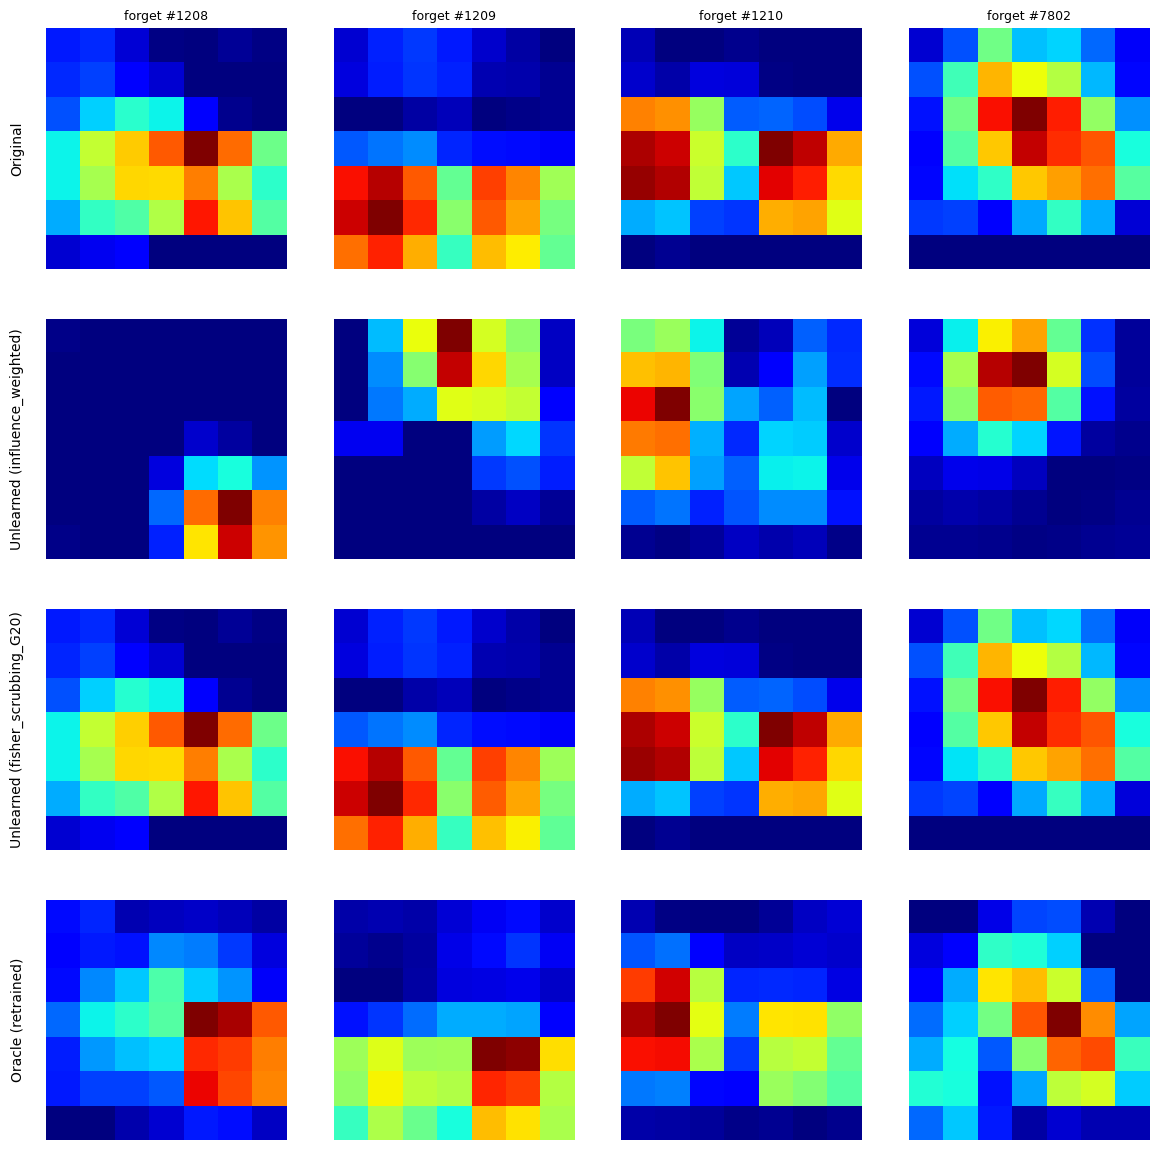


saved -> proofs_nih_pw/fig12_gradcam_oracle.png
  [recorded] F2_gradcam_oracle


In [ ]:
# ============================================================================
# F2 — Grad-CAM: original vs unlearned vs ORACLE
#
# The existing R11 compares before/after only. Adding the oracle row answers
# "what SHOULD the attention look like after correct forgetting?" -- the same
# anchoring logic the rest of the paper uses, now in image space.
#
# ~15 min. Needs ORACLE in memory (run R0/C5 first).
# ============================================================================

assert globals().get("ORACLE") is not None, "Run R0 (NIH) or C5 (CheXpert) first"

N_SHOW, N_STAT = 4, 40
_show = sorted(FORGET)[:N_SHOW]

# ---- quantitative: distance to oracle in attention space --------------------
cams_orig, _   = cam_batch(base_model, sorted(FORGET), max_n=N_STAT)
cams_oracle, _ = cam_batch(ORACLE,     sorted(FORGET), max_n=N_STAT)

def _corr(A, B):
    v = [np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(A, B)]
    v = [x for x in v if np.isfinite(x)]
    return float(np.mean(v)), float(np.std(v))

base_vs_oracle = _corr(cams_orig, cams_oracle)
print(f"original vs ORACLE attention correlation: "
      f"{base_vs_oracle[0]:.4f} +- {base_vs_oracle[1]:.4f}")
print("  ^ this is the TARGET. A method should land near it, not far below.\n")

rows = []
for name, m in tqdm(MODELS.items(), desc="Grad-CAM vs oracle"):
    cams_m, _ = cam_batch(m, sorted(FORGET), max_n=N_STAT)
    c_orig,  s_orig  = _corr(cams_m, cams_orig)
    c_orac,  s_orac  = _corr(cams_m, cams_oracle)
    rows.append(dict(method=name, corr_with_original=c_orig,
                     corr_with_oracle=c_orac, corr_oracle_std=s_orac,
                     gap_to_oracle=abs(c_orac - base_vs_oracle[0])))
CAM_ORACLE = pd.DataFrame(rows).sort_values("gap_to_oracle")
display(CAM_ORACLE.style.format({c: "{:.4f}" for c in CAM_ORACLE.columns
                                 if c != "method"}))
CAM_ORACLE.to_csv(f"{RSTATS}/gradcam_oracle.csv", index=False)
print("\ngap_to_oracle: how far each method's forget-set attention sits from")
print("where the ORACLE puts it. Lower = the edit landed in the right place.")

# ---- qualitative: 3-row figure ---------------------------------------------
best = CAM_ORACLE.iloc[0]["method"]
worst = CAM_ORACLE.iloc[-1]["method"]
panels = [("Original", base_model), (f"Unlearned ({worst})", MODELS[worst]),
          (f"Unlearned ({best})", MODELS[best]), ("Oracle (retrained)", ORACLE)]

fig, axes = plt.subplots(len(panels), N_SHOW, figsize=(3.0 * N_SHOW, 2.9 * len(panels)))
for r, (label, mdl) in enumerate(panels):
    cams, _ = cam_batch(mdl, _show, max_n=N_SHOW)
    for k in range(N_SHOW):
        axes[r, k].imshow(cams[k], cmap="jet", vmin=0, vmax=1)
        axes[r, k].axis("off")
        if k == 0:
            axes[r, k].set_ylabel(label)
            axes[r, k].text(-0.12, 0.5, label, transform=axes[r, k].transAxes,
                            rotation=90, va="center", ha="center", fontsize=10)
        if r == 0:
            axes[r, k].set_title(f"forget #{_show[k]}", fontsize=9)
plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/fig12_gradcam_oracle.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"\nsaved -> {CFG['OUT']}/fig12_gradcam_oracle.png")
record("F2_gradcam_oracle", CAM_ORACLE.to_dict("records"))

## `[RUN]` F3 — Stronger MIA · ~30 min

**What it does:** three attacks instead of one threshold.

- **A1** mean-loss threshold (what the paper currently reports)
- **A2** learned attack — gradient-boosted classifier on per-class loss features
- **A3** oracle-calibrated — scores loss-under-target minus loss-under-oracle,
  cancelling sample difficulty, the exact confound you showed breaks A1

**A3 is the novel one.** It's only possible because you trained oracles, and we
haven't seen it in the unlearning literature.

**Watch:** if A2/A3 give larger advantages than A1, your over-correction result
was conservative and A3 becomes the headline attack.

In [36]:
# ============================================================================
# F3 — Stronger membership-inference attacks
#
# The paper currently uses a single-threshold attack on mean loss, which is the
# weakest adversary in the literature. Its results are therefore a LOWER bound
# on distinguishability. This cell adds two stronger attacks:
#
#   A2  LEARNED attack: a gradient-boosted classifier on a per-sample feature
#       vector (per-class losses, entropy, margin, max prob, ...), trained on
#       known members vs known non-members, then applied to forget vs unseen.
#
#   A3  ORACLE-CALIBRATED attack (LiRA in spirit, without shadow models): score
#       each sample by loss_under_target MINUS loss_under_oracle. This cancels
#       intrinsic sample difficulty -- the exact confound the paper shows breaks
#       the naive attack -- and is only possible because we trained an oracle.
#       A3 is the strongest adversary here and, we believe, novel in this
#       setting.
#
# ~30 min. A3 needs ORACLE in memory.
# ============================================================================

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict

@torch.no_grad()
def _features(model, indices, max_n=None, desc="feat"):
    """Per-sample attack features, richer than a single scalar loss."""
    model.eval()
    idxs = list(indices)[:max_n] if max_n else list(indices)
    ld = DataLoader(TransformedSubset(dataset, idxs, transform_val),
                    batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)
    F = []
    for images, labels, _ in tqdm(ld, desc=desc, leave=False):
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        p = torch.sigmoid(logits)
        per_cls = nn.functional.binary_cross_entropy_with_logits(
            logits, labels, reduction="none")                 # (B, C)
        ent = -(p * torch.log(p + 1e-9) + (1 - p) * torch.log(1 - p + 1e-9))
        feat = torch.cat([
            per_cls,                                   # per-class loss
            per_cls.mean(1, keepdim=True),             # mean loss
            per_cls.max(1, keepdim=True).values,       # worst class
            ent.mean(1, keepdim=True),                 # predictive entropy
            (p - 0.5).abs().mean(1, keepdim=True),     # confidence
            ((p > 0.5).float() == labels).float().mean(1, keepdim=True),
        ], dim=1)
        F.append(feat.cpu().numpy())
    return np.concatenate(F)


def attack_suite(model, forget, members, unseen, oracle=None, max_n=400, tag=""):
    """A1 threshold, A2 learned, A3 oracle-calibrated. Returns dict of AUCs."""
    out = {}

    # ---- A1: mean-loss threshold (what the paper currently reports) ----------
    _, _, fl = subset_stats(model, forget, max_n=max_n, desc="A1 forget")
    _, _, ul = subset_stats(model, unseen, max_n=max_n, desc="A1 unseen")
    y = np.r_[np.ones(len(fl)), np.zeros(len(ul))]
    out["A1_threshold"] = float(roc_auc_score(y, -np.r_[fl, ul]))

    # ---- A2: learned attack -------------------------------------------------
    # Train on members the attacker is assumed to know (retain subset) vs
    # non-members (held-out), then score forget vs unseen.
    Xm = _features(model, members, max_n=max_n, desc="A2 members")
    Xu = _features(model, unseen,  max_n=max_n, desc="A2 nonmembers")
    Xtr = np.vstack([Xm, Xu])
    ytr = np.r_[np.ones(len(Xm)), np.zeros(len(Xu))]
    clf = HistGradientBoostingClassifier(max_iter=200, random_state=0)
    clf.fit(Xtr, ytr)

    Xf = _features(model, forget, max_n=max_n, desc="A2 forget")
    Xn = _features(model, [i for i in unseen if i not in set(members)][max_n:2*max_n],
                   max_n=max_n, desc="A2 eval-nonmembers")
    if len(Xn) < 10:
        Xn = Xu
    s = np.r_[clf.predict_proba(Xf)[:, 1], clf.predict_proba(Xn)[:, 1]]
    y2 = np.r_[np.ones(len(Xf)), np.zeros(len(Xn))]
    out["A2_learned"] = float(roc_auc_score(y2, s))

    # ---- A3: oracle-calibrated ----------------------------------------------
    if oracle is not None:
        _, _, fl_o = subset_stats(oracle, forget, max_n=max_n, desc="A3 forget/orc")
        _, _, ul_o = subset_stats(oracle, unseen, max_n=max_n, desc="A3 unseen/orc")
        n_f, n_u = min(len(fl), len(fl_o)), min(len(ul), len(ul_o))
        # difficulty-cancelled score: lower under target than under oracle
        # => the target model has "seen" it
        d = np.r_[fl[:n_f] - fl_o[:n_f], ul[:n_u] - ul_o[:n_u]]
        y3 = np.r_[np.ones(n_f), np.zeros(n_u)]
        out["A3_oracle_calibrated"] = float(roc_auc_score(y3, -d))
    return out


# ---- run the suite on every model -------------------------------------------
_unseen = [int(i) for i in val_indices]
_members = [int(i) for i in RETAIN_SUB]

rows = []
targets = [("original", base_model)] + list(MODELS.items())
if globals().get("ORACLE") is not None:
    targets.append(("retrain_oracle", ORACLE))

for name, m in targets:
    print(f"\n--- {name} ---")
    a = attack_suite(m, FORGET, _members, _unseen,
                     oracle=globals().get("ORACLE"), tag=name)
    a["method"] = name
    rows.append(a)
    print("   ", {k: round(v, 4) for k, v in a.items() if k != "method"})

MIA_SUITE = pd.DataFrame(rows).set_index("method")
MIA_SUITE.to_csv(f"{RSTATS}/mia_suite.csv")
display(MIA_SUITE.style.format("{:.4f}"))

# ---- the floor under EACH attack, taken from the oracle ---------------------
if "retrain_oracle" in MIA_SUITE.index:
    floors = MIA_SUITE.loc["retrain_oracle"]
    print(f"\n{'='*66}\nEMPIRICAL FLOORS (from the retrain oracle)\n{'='*66}")
    for a in floors.index:
        print(f"  {a:24s} floor = {floors[a]:.4f}  (naive target would be 0.5000)")
    adv = (MIA_SUITE - floors).abs()
    adv.columns = [f"adv_{c}" for c in adv.columns]
    print("\nAdvantage over the oracle floor (0 = indistinguishable from retrained):")
    display(adv.sort_values(adv.columns[-1]).style.format("{:.4f}"))
    adv.to_csv(f"{RSTATS}/mia_advantage.csv")
    print("\nIf A2/A3 give LARGER advantages than A1, the paper's over-correction")
    print("finding was conservative -- report A3 as the headline attack.")

record("F3_mia_suite", MIA_SUITE.to_dict("index"))


--- original ---


A1 forget:   0%|          | 0/3 [00:00<?, ?it/s]

A1 unseen:   0%|          | 0/13 [00:00<?, ?it/s]

A2 members:   0%|          | 0/13 [00:00<?, ?it/s]

A2 nonmembers:   0%|          | 0/13 [00:00<?, ?it/s]

A2 forget:   0%|          | 0/3 [00:00<?, ?it/s]

... (85 outputs left out)

,A1_threshold,A2_learned,A3_oracle_calibrated
method,,,
original,0.7814,0.6379,0.6780
influence_weighted,0.0825,0.3201,0.0748
neggrad_ablation,0.0376,0.1372,0.0347
hybrid_bernoulli,0.3195,0.4099,0.1541
hybrid_uniform,0.2952,0.3895,0.1645
finetune_retain,0.7558,0.6511,0.3474
fisher_scrubbing_G20,0.7814,0.6440,0.6783
scrub_K23,0.7750,0.6496,0.5818
ssd_F24,0.7813,0.6246,0.6775



EMPIRICAL FLOORS (from the retrain oracle)
  A1_threshold             floor = 0.7517  (naive target would be 0.5000)
  A2_learned               floor = 0.6199  (naive target would be 0.5000)
  A3_oracle_calibrated     floor = 0.5000  (naive target would be 0.5000)

Advantage over the oracle floor (0 = indistinguishable from retrained):


,adv_A1_threshold,adv_A2_learned,adv_A3_oracle_calibrated
method,,,
retrain_oracle,0.0000,0.0000,0.0000
scrub_K23,0.0233,0.0296,0.0818
finetune_retain,0.0041,0.0311,0.1526
ssd_F24,0.0296,0.0046,0.1775
original,0.0297,0.0180,0.1780
fisher_scrubbing_G20,0.0297,0.0241,0.1783
hybrid_uniform,0.4565,0.2304,0.3355
hybrid_bernoulli,0.4322,0.2101,0.3459
influence_weighted,0.6692,0.2999,0.4252



If A2/A3 give LARGER advantages than A1, the paper's over-correction
finding was conservative -- report A3 as the headline attack.
  [recorded] F3_mia_suite


## `[RUN]` F4 — 20 seeds · ~3.5 h

**What it does:** extends 6 → 20 independent (top of the 10–20 range requested) forget-set draws.

Six seeds put the Wilcoxon floor at 2⁻⁵ = 0.031, so every significant result sat
*exactly* at the floor — the test reported the smallest p it could rather than a
graded one. Twenty puts the floor at 1.9×10⁻⁶ and adds Cohen's d.

**Watch:** the influence-weighted vs NegGrad row. If it's still non-significant
at 20 seeds, your negative result is solid rather than a small-sample artifact.

Resumable — only new seeds run. Needs `SCHEME_FNS`, so run **R4 first**.

In [41]:
# ============================================================================
# F4 — Extend to 20 independent forget-set draws
#
# Six seeds put the Wilcoxon floor at 2^-5 = 0.031, so every significant result
# sat EXACTLY at the floor -- the test reported the smallest p it could rather
# than a graded one. Sixteen seeds put the floor at 2^-15 = 3.1e-5, which gives
# genuinely graded evidence and lets effect sizes speak.
#
# Resumable via multiseed.csv: only the new seeds run. ~15 min per new seed.
# ============================================================================

SEEDS_R = [42, 7, 2024, 1337, 99, 1234,              # 6 already on disk
           11, 314, 2718, 555, 8080, 4242, 606, 909,  # + 14 new
           31337, 77, 1618, 8128, 496, 6]             # = 20 total
# n=20 -> two-sided Wilcoxon floor = 2/2^20 = 1.9e-6: p-values become graded
# rather than floor-valued, and Cohen's d carries the effect sizes.

MS_CSV = f"{RSTATS}/multiseed.csv"
ms = pd.read_csv(MS_CSV).to_dict("records") if os.path.exists(MS_CSV) else []
done = {(int(r["seed"]), r["scheme"]) for r in ms}
todo_n = sum(1 for s in SEEDS_R for n in SCHEME_FNS if (s, n) not in done)
print(f"{len(done)} pairs on disk, {todo_n} to run "
      f"(~{todo_n*4:.0f} min at ~4 min/pair)")

for seed in SEEDS_R:
    todo = [n for n in SCHEME_FNS if (seed, n) not in done]
    if not todo:
        continue
    f_idx, r_pool, _ = build_patient_forget_set(train_indices, seed=seed, verbose=False)
    ld, r_sub = build_unlearn_loader(f_idx, r_pool, seed=seed)
    infl = minmax_norm(grad_influence(base_model, f_idx))
    for name in todo:
        print(f"\n--- seed {seed} | {name} ---")
        m = SCHEME_FNS[name](fresh_model(), ld, f_idx, infl)
        v = verify_baseline_relative(base_model, m, f_idx, r_sub)
        ms.append(dict(seed=seed, scheme=name, n_forget=len(f_idx),
                       macro_auc=macro_auc(m, desc=name),
                       mia_auc=membership_inference_auc(m, f_idx, val_indices), **v))
        pd.DataFrame(ms).to_csv(MS_CSV, index=False)
        del m; torch.cuda.empty_cache()

MULTI = pd.DataFrame(ms)
n_seeds = MULTI.seed.nunique()
floor = 2.0 / 2**n_seeds
print(f"\n{n_seeds} seeds | Wilcoxon two-sided floor = {floor:.2e}")

display(MULTI.groupby("scheme")[["macro_auc", "delta_forget_loss", "mia_auc"]]
        .agg(["mean", "std"]).style.format("{:.4f}"))

wr = []
for a, b in itertools.combinations(SCHEME_FNS, 2):
    for metric in ["macro_auc", "delta_forget_loss", "mia_auc"]:
        x = MULTI[MULTI.scheme == a].sort_values("seed")[metric].values
        y = MULTI[MULTI.scheme == b].sort_values("seed")[metric].values
        n = min(len(x), len(y))
        if n >= 6:
            st, p = wilcoxon(x[:n], y[:n])
            d = (x[:n] - y[:n])
            wr.append(dict(a=a, b=b, metric=metric, n=n,
                           mean_diff=float(d.mean()),
                           cohens_d=float(d.mean() / (d.std() + 1e-12)),
                           p=float(p)))
WILCOX = pd.DataFrame(wr)
WILCOX["p_fdr"] = false_discovery_control(WILCOX["p"])
WILCOX["at_floor"] = np.isclose(WILCOX["p"], floor)
WILCOX.to_csv(f"{RSTATS}/wilcoxon.csv", index=False)

sig = WILCOX[WILCOX.p_fdr < 0.05]
print(f"\n{len(sig)}/{len(WILCOX)} significant at FDR < 0.05; "
      f"{int(WILCOX.at_floor.sum())} still sitting exactly at the floor")
display(WILCOX.sort_values("p_fdr").head(12).style.format(
    {"mean_diff": "{:+.4f}", "cohens_d": "{:+.2f}", "p": "{:.2e}", "p_fdr": "{:.2e}"}))

infl_row = WILCOX[((WILCOX.a == "influence_weighted") & (WILCOX.b == "neggrad_ablation")) |
                  ((WILCOX.b == "influence_weighted") & (WILCOX.a == "neggrad_ablation"))]
print("\nTHE ABLATION (influence-weighted vs NegGrad):")
display(infl_row.style.format({"mean_diff": "{:+.4f}", "cohens_d": "{:+.2f}",
                               "p": "{:.2e}", "p_fdr": "{:.2e}"}))
print("If still p_fdr > 0.05 at 20 seeds, the null result is solid, not a")
print("small-sample artifact -- which is a much stronger statement than at n=6.")
record("F4_seeds", dict(n_seeds=int(n_seeds), floor=float(floor),
                        n_significant=int(len(sig)), n_tests=int(len(WILCOX))))

20 pairs on disk, 60 to run (~240 min at ~4 min/pair)


grad-norm influence:   0%|          | 0/95 [00:00<?, ?it/s]


--- seed 1234 | influence_weighted ---


IGC 1/5:   0%|          | 0/16 [00:00<?, ?it/s]

  ep1: retain=0.4948 forget=0.5720


IGC 2/5:   0%|          | 0/16 [00:00<?, ?it/s]

... (1,001 outputs left out)

,a,b,metric,n,mean_diff,cohens_d,p,p_fdr,at_floor
3,influence_weighted,hybrid_bernoulli,macro_auc,20,-0.1854,-6.13,1.91e-06,2.29e-06,True
6,influence_weighted,finetune_retain,macro_auc,20,-0.2031,-5.69,1.91e-06,2.29e-06,True
5,influence_weighted,hybrid_bernoulli,mia_auc,20,-0.1831,-3.00,1.91e-06,2.29e-06,True
4,influence_weighted,hybrid_bernoulli,delta_forget_loss,20,+1.7753,+4.41,1.91e-06,2.29e-06,True
7,influence_weighted,finetune_retain,delta_forget_loss,20,+1.9013,+4.66,1.91e-06,2.29e-06,True
10,neggrad_ablation,hybrid_bernoulli,delta_forget_loss,20,+2.2654,+5.41,1.91e-06,2.29e-06,True
9,neggrad_ablation,hybrid_bernoulli,macro_auc,20,-0.2058,-4.91,1.91e-06,2.29e-06,True
8,influence_weighted,finetune_retain,mia_auc,20,-0.5606,-7.37,1.91e-06,2.29e-06,True
12,neggrad_ablation,finetune_retain,macro_auc,20,-0.2235,-4.86,1.91e-06,2.29e-06,True
13,neggrad_ablation,finetune_retain,delta_forget_loss,20,+2.3914,+5.62,1.91e-06,2.29e-06,True



THE ABLATION (influence-weighted vs NegGrad):


,a,b,metric,n,mean_diff,cohens_d,p,p_fdr,at_floor
0,influence_weighted,neggrad_ablation,macro_auc,20,+0.0204,+0.47,4.41e-02,4.41e-02,False
1,influence_weighted,neggrad_ablation,delta_forget_loss,20,-0.4901,-0.87,1.69e-03,1.90e-03,False
2,influence_weighted,neggrad_ablation,mia_auc,20,+0.0275,+0.77,4.22e-03,4.47e-03,False


If still p_fdr > 0.05 at 20 seeds, the null result is solid, not a
small-sample artifact -- which is a much stronger statement than at n=6.
  [recorded] F4_seeds


## `[RUN ONCE]` F5 — Patient-wise NIH retrain · ~7 h

**Run this in a FRESH kernel with the NIH dataset** — `S1–S5`, `B1–B5`, then F5.
Do **not** run C1 or C3 in that session.

**What it does:** ChestX-ray14 has ~3.6 studies per patient, so an image-level
split leaks patients between train and validation and inflates AUC (Zech et al.
2018). This retrains with a patient-wise split.

**Expect the AUC to drop from 0.8391.** That drop *is* the leakage effect —
report both numbers. Batch-level resumable.

In [11]:
# ============================================================================
# F5 — Rebuild ChestX-ray14 with a PATIENT-WISE split, then retrain
#
# The NIH base model used an image-level split. ChestX-ray14 has ~3.6 studies
# per patient, so the same patient appears in train AND validation, inflating
# AUC (Zech et al. 2018). CheXpert already used patient-wise; this brings NIH
# into line so the headline number is comparable to published work.
#
# Step 1 of 3. Then F6 (oracle), then re-run the study.
# ~7 h, batch-level resumable.
# ============================================================================

PW_CKPT  = "nih_pw_ckpt.pth"
PW_BEST  = "nih_pw_best.pth"
PW_EPOCHS, SAVE_EVERY = 12, 100

# ---- patient-wise split over the NIH dataset --------------------------------
_meta = dataset.data
_pid_col = "Patient ID" if "Patient ID" in _meta.columns else _meta.columns[3]
_pids = _meta[_pid_col].values

rng = np.random.RandomState(42)
_uniq = np.unique(_pids).copy(); rng.shuffle(_uniq)
_n_val = int(len(_uniq) * 0.20)
_val_pat = set(_uniq[:_n_val].tolist())
_is_val = np.isin(_pids, list(_val_pat))

pw_train = [int(i) for i in np.where(~_is_val)[0]]
pw_val   = [int(i) for i in np.where(_is_val)[0]]
assert not (set(_pids[pw_train]) & set(_pids[pw_val])), "patient leakage!"

print(f"patient-wise split: {len(pw_train)} train / {len(pw_val)} val")
print(f"  {len(_uniq)-_n_val} train patients / {_n_val} val patients, 0 shared")
print(f"  (image-level split was {len(train_indices)} / {len(val_indices)})")

# ---- retrain ---------------------------------------------------------------
pw_model = ChestXrayDenseNet(num_classes=15, pretrained=True).to(device)
pw_opt = optim.AdamW(pw_model.parameters(), lr=1e-4, weight_decay=1e-2)
pw_sch = optim.lr_scheduler.CosineAnnealingLR(pw_opt, T_max=15, eta_min=1e-6)

_cnt = dataset.labels.iloc[pw_train].sum(axis=0).values
pw_criterion = FocalLossWithLogits(
    pos_weight=torch.tensor(len(pw_train) / (_cnt + 1e-6),
                            dtype=torch.float32).to(device))

start_ep, start_batch, phist, best = 1, 0, [], 0.0
if os.path.exists(PW_CKPT):
    st = torch.load(PW_CKPT, weights_only=False)
    pw_model.load_state_dict(st["model"])
    if st.get("opt"): pw_opt.load_state_dict(st["opt"])
    if st.get("sch"): pw_sch.load_state_dict(st["sch"])
    phist, best = st.get("history", []), st.get("best_auc", 0.0)
    if st.get("batch", 0) > 0:
        start_ep, start_batch = st["epoch"], st["batch"]
        print(f"RESUMING MID-EPOCH: epoch {start_ep}, batch {start_batch}")
    else:
        start_ep = st["epoch"] + 1
        print(f"RESUMING at epoch {start_ep} (best {best:.4f})")

pw_val_loader = DataLoader(TransformedSubset(dataset, pw_val, transform_val),
                           batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)

def _pw_loader(ep, skip=0):
    r = np.random.RandomState(4000 + ep)
    perm = [int(i) for i in np.asarray(pw_train)[r.permutation(len(pw_train))]]
    n_tot = (len(perm) + CFG["BATCH_SIZE"] - 1) // CFG["BATCH_SIZE"]
    rem = perm[skip * CFG["BATCH_SIZE"]:]
    if not rem: return None, n_tot
    return DataLoader(TransformedSubset(dataset, rem, transform_train),
                      batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0,
                      drop_last=(len(rem) % CFG["BATCH_SIZE"] == 1)), n_tot

ep, done = start_ep, start_batch
try:
    for ep in range(start_ep, PW_EPOCHS + 1):
        if ep <= 3: pw_model.freeze_backbone()
        else:
            pw_model.unfreeze_backbone()
            if ep == 4 or ep == start_ep: print("--- Phase 2 ---")
        skip = start_batch if ep == start_ep else 0
        ld, n_tot = _pw_loader(ep, skip)
        pw_model.train(); t0 = time.time(); done = skip
        if ld is not None:
            bar = tqdm(ld, initial=skip, total=n_tot, desc=f"NIH-pw {ep}/{PW_EPOCHS}")
            for images, labels, _ in bar:
                if images.size(0) < 2: done += 1; continue
                images, labels = images.to(device), labels.to(device)
                pw_opt.zero_grad(set_to_none=True)
                pw_criterion(pw_model(images), labels).backward()
                torch.nn.utils.clip_grad_norm_(pw_model.parameters(), CFG["CLIP"])
                pw_opt.step(); done += 1
                if done % SAVE_EVERY == 0:
                    save_ckpt(PW_CKPT, pw_model, pw_opt, pw_sch, epoch=ep,
                              history=phist, batch=done, best_auc=best)
                    bar.set_postfix(saved=done)
        pw_sch.step()
        pw_model.eval(); P, Y = [], []
        with torch.no_grad():
            for images, labels, _ in tqdm(pw_val_loader, desc="pw val", leave=False):
                P.append(torch.sigmoid(pw_model(images.to(device))).cpu().numpy())
                Y.append(labels.numpy())
        P, Y = np.concatenate(P), np.concatenate(Y)
        a = float(np.mean([roc_auc_score(Y[:, i], P[:, i]) for i in range(Y.shape[1])
                           if len(np.unique(Y[:, i])) > 1]))
        mins = (time.time() - t0) / 60
        phist.append(dict(epoch=ep, val_auc=a, mins=mins))
        if a > best:
            best = a
            _atomic_save({"model_state_dict": pw_model.state_dict(),
                          "history": phist, "epoch": ep, "val_auc": a}, PW_BEST)
            print(f"  epoch {ep}: val AUC = {a:.4f} ({mins:.0f} min)  <- best")
        else:
            print(f"  epoch {ep}: val AUC = {a:.4f} ({mins:.0f} min)")
        save_ckpt(PW_CKPT, pw_model, pw_opt, pw_sch, epoch=ep,
                  history=phist, batch=0, best_auc=best)
        start_batch = 0

    print(f"\nPATIENT-WISE NIH COMPLETE. best val AUC = {best:.4f} -> {PW_BEST}")
    print(f"  image-level split gave 0.8391; the drop is the leakage "
          f"({0.8391-best:+.4f}).")
    print("  Report BOTH in the paper -- the difference IS the Zech et al. effect.")
except KeyboardInterrupt:
    save_ckpt(PW_CKPT, pw_model, pw_opt, pw_sch, epoch=ep, history=phist,
              batch=done, best_auc=best)
    print(f"\nInterrupted at epoch {ep}, batch {done}. Re-run to continue."); raise

patient-wise split: 89826 train / 22294 val
  24644 train patients / 6161 val patients, 0 shared
  (image-level split was 89696 / 22424)


NIH-pw 1/12:   0%|          | 0/2808 [00:00<?, ?it/s]

pw val:   0%|          | 0/697 [00:00<?, ?it/s]

  epoch 1: val AUC = 0.7138 (32 min)  <- best


NIH-pw 2/12:   0%|          | 0/2808 [00:00<?, ?it/s]

pw val:   0%|          | 0/697 [00:00<?, ?it/s]

... (27 outputs left out)

  epoch 11: val AUC = 0.8342 (35 min)  <- best


NIH-pw 12/12:   0%|          | 0/2808 [00:00<?, ?it/s]

pw val:   0%|          | 0/697 [00:00<?, ?it/s]

  epoch 12: val AUC = 0.8331 (34 min)

PATIENT-WISE NIH COMPLETE. best val AUC = 0.8342 -> nih_pw_best.pth
  image-level split gave 0.8391; the drop is the leakage (+0.0049).
  Report BOTH in the paper -- the difference IS the Zech et al. effect.


## `[RUN]` F6 — Swap + re-run · ~1 min, then ~11 h

**What it does:** archives the image-level results, rebinds globals to the
patient-wise model, points `CFG` at new oracle filenames so the NIH oracle isn't
overwritten.

**After F6:** `B6 → B15`, then `O1` (new oracle, ~7 h), then `R0 → R9`.

In [11]:
# ============================================================================
# F5-LITE — rebuild F5's namespace WITHOUT retraining
#
# F5 defines pw_train / pw_val / pw_criterion as a side effect of a 7 h retrain.
# The split is deterministic (RandomState(42) over unique patient IDs) and the
# weights are already on disk, so after a kernel death only the names are
# missing. This reproduces F5's split logic exactly, verbatim, and stops.
#
# Requires: S1-S5, B1-B3 already run. ~2 s.
# ============================================================================

PW_CKPT = "nih_pw_ckpt.pth"
PW_BEST = "nih_pw_best.pth"

assert os.path.exists(PW_BEST), (
    f"{PW_BEST} not found — F5 has not completed on this machine. "
    "You must run the full F5 retrain; F5-LITE only recovers lost variables.")

# ---- patient-wise split: identical to F5 ----------------------------------
_meta    = dataset.data
_pid_col = "Patient ID" if "Patient ID" in _meta.columns else _meta.columns[3]
_pids    = _meta[_pid_col].values

rng = np.random.RandomState(42)
_uniq = np.unique(_pids).copy(); rng.shuffle(_uniq)
_n_val   = int(len(_uniq) * 0.20)
_val_pat = set(_uniq[:_n_val].tolist())
_is_val  = np.isin(_pids, list(_val_pat))

pw_train = [int(i) for i in np.where(~_is_val)[0]]
pw_val   = [int(i) for i in np.where(_is_val)[0]]
assert not (set(_pids[pw_train]) & set(_pids[pw_val])), "patient leakage!"

_cnt = dataset.labels.iloc[pw_train].sum(axis=0).values
pw_criterion = FocalLossWithLogits(
    pos_weight=torch.tensor(len(pw_train) / (_cnt + 1e-6),
                            dtype=torch.float32).to(device))

print(f"patient-wise split: {len(pw_train)} train / {len(pw_val)} val")
print(f"  {len(_uniq)-_n_val} train patients / {_n_val} val patients, 0 shared")
print(f"  paper reports 89,826 / 22,294 across 24,644 / 6,161 patients")

_h = torch.load(PW_BEST, weights_only=False)
print(f"\n{PW_BEST}: epoch {_h.get('epoch')}, val AUC {_h.get('val_auc'):.4f}"
      f"   (paper reports 0.8342)")
del _h
print("\npw_train / pw_val / pw_criterion restored. Run F6 now.")

patient-wise split: 89826 train / 22294 val
  24644 train patients / 6161 val patients, 0 shared
  paper reports 89,826 / 22,294 across 24,644 / 6,161 patients

nih_pw_best.pth: epoch 11, val AUC 0.8342   (paper reports 0.8342)

pw_train / pw_val / pw_criterion restored. Run F6 now.


In [12]:
# ============================================================================
# F6 — Swap the patient-wise NIH model in, then re-run the study
#
# Run AFTER F5. Archives the image-level results, rebinds the globals, and
# points CFG at the new checkpoint. Then re-run B6 -> B15 and R0 -> R9 exactly
# as before; the oracle is retrained by the standard cell (O1/C4) because
# CFG["ORACLE_*"] now points at patient-wise filenames.
# ============================================================================

import shutil
if os.path.exists("proofs") and not os.path.exists("proofs_nih_imagelevel"):
    shutil.copytree("proofs", "proofs_nih_imagelevel")
    print("archived image-level NIH results -> proofs_nih_imagelevel/")

train_indices = pw_train
val_indices   = pw_val
criterion     = pw_criterion
CLASS_NAMES   = dataset.labels.columns.tolist()
PREVALENCE    = (dataset.labels.sum(axis=0) / len(dataset)).to_dict()

CFG["CHECKPOINT"]   = PW_BEST
CFG["NUM_CLASSES"]  = 15
CFG["OUT"]          = "proofs_nih_pw"
CFG["ORACLE_CKPT"]  = "nih_pw_oracle_ckpt.pth"
CFG["ORACLE_FINAL"] = "nih_pw_oracle_model.pth"
CFG["RUN_ORACLE"]   = True
for d in ["", "/tables", "/stats", "/cache", "/models"]:
    os.makedirs(f"{CFG['OUT']}{d}", exist_ok=True)
RSTATS   = f"{CFG['OUT']}/stats"
CACHE    = f"{CFG['OUT']}/cache"
MODELDIR = f"{CFG['OUT']}/models"

def fresh_model(path=None):
    path = path or CFG["CHECKPOINT"]
    m = ChestXrayDenseNet(num_classes=CFG["NUM_CLASSES"], pretrained=True).to(device)
    m.load_state_dict(torch.load(path, weights_only=False)["model_state_dict"])
    m.eval(); return m

def load_saved_model(name):
    p = f"{MODELDIR}/{name}.pth"
    if not os.path.exists(p): return None
    m = ChestXrayDenseNet(num_classes=CFG["NUM_CLASSES"], pretrained=False).to(device)
    m.load_state_dict(torch.load(p, weights_only=False)); m.eval(); return m

val_loader_eval = DataLoader(TransformedSubset(dataset, val_indices, transform_val),
                             batch_size=CFG["BATCH_SIZE"], shuffle=False, num_workers=0)

for n in ["RESULTS","PERCLASS","MODELS","PRED","AUDITS","RESULTS_DF","SWEEP",
          "TRAJ","ORACLE","base_model","FORGET","RETAIN_POOL","RETAIN_SUB",
          "UNLEARN_LOADER","INFL","MULTI","WILCOX"]:
    globals().pop(n, None)
RESULTS, PERCLASS, MODELS = {}, {}, {}

_m = fresh_model()
print(f"\npatient-wise NIH loaded | macro AUC = "
      f"{macro_auc(_m, val_loader_eval, desc='pw'):.4f}")
print(f"  output dir: {CFG['OUT']}")
del _m
print("\nNEXT: B6 -> B15, then O1 (oracle, ~7 h), then R0 -> R9.")

pw:   0%|          | 0/697 [00:00<?, ?it/s]


patient-wise NIH loaded | macro AUC = 0.8342
  output dir: proofs_nih_pw

NEXT: B6 -> B15, then O1 (oracle, ~7 h), then R0 -> R9.


In [33]:
# ============================================================================
# F7 - Tuning sweep for the near-no-ops                    ~1-2.5 h  (v2)
#
# Closes the most likely reviewer objection: "Fisher scrubbing and SSD are
# near-no-ops only because you ran published defaults." Sweeps the single
# parameter controlling each method's aggressiveness and asks whether either
# EVER approaches the oracle's attack floor before macro AUC collapses.
#
# v2 changes:
#   - NaN-safe. Fisher's F^{-1/4} scaling blows up on near-zero-Fisher
#     parameters at large alpha; the model overflows and every logit becomes
#     NaN. That is a RESULT (no stable operating range), not an error, so it is
#     recorded as "diverged" rather than crashing the sweep.
#   - Finer grid at the low end, so there is resolution between "no-op" and
#     "destroyed" rather than one order-of-magnitude jump.
#   - Skips the expensive macro_auc / A1 passes for diverged models.
#   - Resumable: partial results are checkpointed to CSV after every setting.
#
# Requires: S1-S5, B1-B4, F5-LITE, F6, B6-B13, F0, R5-R8 (for fisher_scrubbing
# and ssd_unlearning). Writes tables/tuning_sweep.tex, which supp.tex inputs.
#
# NOTE ON RUNTIME: each non-diverged setting costs one full validation pass.
# With num_workers=0 on Windows that is ~15 min each, so a 12-setting sweep is
# an overnight job. Get num_workers>0 working on val_loader_eval first if you
# can - see the B8 discussion.
# ============================================================================

import math

# --- grids -----------------------------------------------------------------
# Published defaults marked below. Low end is dense because that is where any
# useful intermediate regime would have to live.
FISHER_ALPHAS = [1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 1e-3]   # default 1e-6
SSD_ALPHAS    = [10.0, 5.0, 2.0, 1.0, 0.5, 0.25]       # default 10.0
                                                        # (lower = selects more)

RESUME = True                       # reuse rows already in the CSV
_CSV   = f"{CFG['OUT']}/tuning_sweep.csv"


# --- P1 calibration constants ----------------------------------------------
ORACLE_FORGET_LOSS = subset_stats(ORACLE, FORGET, desc="oracle forget")[0]
A1_FLOOR           = membership_inference_auc(ORACLE, FORGET, val_indices)
print(f"P1 constants | oracle forget loss {ORACLE_FORGET_LOSS:.4f}"
      f" | A1 floor {A1_FLOOR:.4f}")
print(f"   reference: untouched original sits ~0.0005 from the oracle,"
      f" A1 gap ~0.178; SCRUB reaches ~0.082\n")


def _evaluate(m, tag):
    """NaN-safe evaluation. A diverged model is a legitimate outcome: it means
    the setting destroyed the network before it forgot anything."""
    fL, _, losses = subset_stats(m, FORGET, desc=f"{tag} forget")
    finite = np.isfinite(fL) and np.isfinite(np.asarray(losses, dtype=float)).all()

    if not finite:
        print(f"   [{tag}] DIVERGED - non-finite forget-set loss."
              " Recorded, not dropped.")
        return dict(macro_auc=float("nan"), forget_loss=float("nan"),
                    oracle_dist=float("nan"), a1=float("nan"),
                    a1_gap=float("nan"), diverged=True)

    a1 = membership_inference_auc(m, FORGET, val_indices)
    mA = macro_auc(m, desc=tag)
    return dict(macro_auc=mA, forget_loss=fL,
                oracle_dist=abs(fL - ORACLE_FORGET_LOSS),
                a1=a1, a1_gap=abs(a1 - A1_FLOOR), diverged=False)


def _flush(rows):
    pd.DataFrame(rows).to_csv(_CSV, index=False)


# --- resume -----------------------------------------------------------------
TUNE, _done = [], set()
if RESUME and os.path.exists(_CSV):
    TUNE = pd.read_csv(_CSV).to_dict("records")
    _done = {(r["method"], r["setting"]) for r in TUNE}
    print(f"resuming: {len(TUNE)} settings already on disk\n")


# --- Fisher scrubbing -------------------------------------------------------
for a in FISHER_ALPHAS:
    key = ("Fisher scrubbing", f"$\\alpha={a:g}$")
    if key in _done:
        print(f"--- Fisher alpha={a:g} (cached) ---"); continue
    print(f"--- Fisher scrubbing, alpha={a:g} ---")
    m = None
    try:
        m = fresh_model()
        m, _ = fisher_scrubbing(m, RETAIN_POOL, alpha=a)
        row = _evaluate(m, f"fisher{a:g}")
    except (RuntimeError, ValueError, FloatingPointError) as e:
        print(f"   [fisher{a:g}] FAILED: {type(e).__name__}: {e}")
        row = dict(macro_auc=float("nan"), forget_loss=float("nan"),
                   oracle_dist=float("nan"), a1=float("nan"),
                   a1_gap=float("nan"), diverged=True)
    finally:
        if m is not None:
            del m
        torch.cuda.empty_cache()
    TUNE.append(dict(method=key[0], setting=key[1], default=(a == 1e-6), **row))
    _flush(TUNE)


# --- SSD --------------------------------------------------------------------
for a in SSD_ALPHAS:
    key = ("SSD", f"$\\alpha_{{\\rm sel}}={a:g}$")
    if key in _done:
        print(f"--- SSD alpha_sel={a:g} (cached) ---"); continue
    print(f"--- SSD, alpha_sel={a:g} ---")
    m = None
    try:
        m = fresh_model()
        m, _ = ssd_unlearning(m, FORGET, RETAIN_POOL, selection_alpha=a)
        row = _evaluate(m, f"ssd{a:g}")
    except (RuntimeError, ValueError, FloatingPointError) as e:
        print(f"   [ssd{a:g}] FAILED: {type(e).__name__}: {e}")
        row = dict(macro_auc=float("nan"), forget_loss=float("nan"),
                   oracle_dist=float("nan"), a1=float("nan"),
                   a1_gap=float("nan"), diverged=True)
    finally:
        if m is not None:
            del m
        torch.cuda.empty_cache()
    TUNE.append(dict(method=key[0], setting=key[1], default=(a == 10.0), **row))
    _flush(TUNE)


TUNE_DF = pd.DataFrame(TUNE)
display(TUNE_DF)


# --- reading ----------------------------------------------------------------
_ok = TUNE_DF[~TUNE_DF["diverged"].astype(bool)]
print("\n" + "=" * 68)
if len(_ok):
    _best = _ok.loc[_ok["a1_gap"].idxmin()]
    print(f"smallest A1 gap over the whole sweep: {_best['a1_gap']:.4f}"
          f"  ({_best['method']}, {_best['setting']}, "
          f"macro AUC {_best['macro_auc']:.4f})")
    print(f"untouched original ~0.178 | SCRUB ~0.082 | oracle 0 by construction")
    if _best["a1_gap"] > 0.15:
        print("\n-> No setting approaches the floor. The no-op behaviour is a")
        print("   property of the deletion scale, not of the published")
        print("   defaults. This is the result that strengthens Sec. VI-C.")
    else:
        print("\n-> Some setting DOES move the attack gap meaningfully.")
        print("   That is a genuine finding: Sec. VI-C and the Limitations")
        print("   paragraph on published defaults both need rewording.")
else:
    print("every setting diverged - widen the grid downward")
print(f"{int(TUNE_DF['diverged'].astype(bool).sum())} of {len(TUNE_DF)}"
      " settings diverged")
print("=" * 68)


# --- emit the LaTeX table supp.tex inputs -----------------------------------
os.makedirs("tables", exist_ok=True)
lines = [
 r"\begin{table}[!t]",
 r"\caption{Fisher scrubbing and SSD swept over the parameter controlling",
 r"aggressiveness; published defaults marked $\dagger$. \emph{Diverged} denotes",
 r"a non-finite forget-set loss. Oracle forget-set loss",
 f" ${ORACLE_FORGET_LOSS:.4f}$, A1 floor ${A1_FLOOR:.4f}$; the untouched",
 r" original sits at an A1 gap of $0.178$ and SCRUB at $0.082$.}",
 r"\label{tab:tune}", r"\centering", r"\footnotesize",
 r"\begin{tabular}{llccc}", r"\toprule",
 r"Method & Setting & Macro AUC & $\lvert\mathcal{L}_f-\mathcal{L}^{\mathrm{orc}}_f\rvert$ & $\lvert$A1$-$floor$\rvert$ \\",
 r"\midrule"]
prev = None
for r in TUNE:
    if prev is not None and r["method"] != prev:
        lines.append(r"\midrule")
    prev = r["method"]
    dag = r"$^\dagger$" if r.get("default") else ""
    if bool(r.get("diverged")):
        lines.append(f"{r['method']} & {r['setting']}{dag} & "
                     r"\multicolumn{3}{c}{\emph{diverged}} \\")
    else:
        lines.append(f"{r['method']} & {r['setting']}{dag} & "
                     f"{r['macro_auc']:.4f} & {r['oracle_dist']:.4f} & "
                     f"{r['a1_gap']:.4f} \\\\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
with open("tables/tuning_sweep.tex", "w") as f:
    f.write("\n".join(lines) + "\n")
print("\nwrote tables/tuning_sweep.tex")
record("tuning_sweep", TUNE)

oracle forget:   0%|          | 0/3 [00:00<?, ?it/s]

MIA forget:   0%|          | 0/3 [00:00<?, ?it/s]

MIA unseen:   0%|          | 0/16 [00:00<?, ?it/s]

  MIA AUC = 0.7533  -> still memorized
P1 constants | oracle forget loss 0.4088 | A1 floor 0.7533
   reference: untouched original sits ~0.0005 from the oracle, A1 gap ~0.178; SCRUB reaches ~0.082

--- Fisher scrubbing, alpha=1e-06 ---


fisher:   0%|          | 0/25 [00:00<?, ?it/s]

fisher1e-06 forget:   0%|          | 0/3 [00:00<?, ?it/s]

... (91 outputs left out)

  MIA AUC = 0.6195  -> still memorized


ssd0.25:   0%|          | 0/697 [00:00<?, ?it/s]

,method,setting,default,macro_auc,forget_loss,oracle_dist,a1,a1_gap,diverged
0,Fisher scrubbing,$\alpha=1e-06$,True,0.834219,4.094128e-01,6.492119e-04,0.784598,0.031287,False
1,Fisher scrubbing,$\alpha=3e-06$,False,0.834231,4.093050e-01,5.414123e-04,0.784598,0.031287,False
2,Fisher scrubbing,$\alpha=1e-05$,False,0.834154,4.086171e-01,1.465361e-04,0.784092,0.030782,False
3,Fisher scrubbing,$\alpha=3e-05$,False,0.834341,4.104562e-01,1.692517e-03,0.783747,0.030437,False
4,Fisher scrubbing,$\alpha=0.0001$,False,0.833363,4.087653e-01,1.619945e-06,0.786506,0.033195,False
5,Fisher scrubbing,$\alpha=0.001$,False,0.500000,9.859191e+18,9.859191e+18,0.406920,0.346391,False
6,SSD,$\alpha_{\rm sel}=10$,True,0.834226,4.093760e-01,6.123797e-04,0.784483,0.031172,False
7,SSD,$\alpha_{\rm sel}=5$,False,0.834497,4.246932e-01,1.592960e-02,0.772138,0.018828,False
8,SSD,$\alpha_{\rm sel}=2$,False,0.545336,5.034276e-01,9.466399e-02,0.590483,0.162828,False
9,SSD,$\alpha_{\rm sel}=1$,False,0.503461,4.999286e-01,9.116496e-02,0.619425,0.133885,False



smallest A1 gap over the whole sweep: 0.0188  (SSD, $\alpha_{\rm sel}=5$, macro AUC 0.8345)
untouched original ~0.178 | SCRUB ~0.082 | oracle 0 by construction

-> Some setting DOES move the attack gap meaningfully.
   That is a genuine finding: Sec. VI-C and the Limitations
   paragraph on published defaults both need rewording.
0 of 12 settings diverged

wrote tables/tuning_sweep.tex
  [recorded] tuning_sweep


In [ ]:
# ============================================================================
# F8 - LiRA-style shadow-model attack (A4)                     ~5 h, OPTIONAL
#
# The paper's Limitations concede that A1-A3 exclude shadow-model attacks and
# argue the omission is conservative. That argument is correct but it is an
# argument, not a measurement. This measures it.
#
# Full LiRA wants tens of shadow models at full schedule, which is not
# affordable on a consumer GPU. This is a REDUCED protocol: N_SHADOW models on
# a shortened schedule (frozen backbone, few epochs), each trained on a random
# half of the training partition, giving per-example in/out loss distributions.
# It is weaker than published LiRA and you must say so - but a measured lower
# bound from 8 shadows beats an unmeasured one from zero.
#
# Set N_SHADOW=2 first and confirm the loop completes before committing 5 h.
# ============================================================================
 
N_SHADOW      = 8
SHADOW_EPOCHS = 4          # frozen backbone only
SHADOW_FRAC   = 0.5
 
def train_shadow(seed, members):
    torch.manual_seed(seed); np.random.seed(seed)
    m = ChestXrayDenseNet(num_classes=len(CLASS_NAMES), pretrained=True).to(device)
    for p in m.backbone.parameters():
        p.requires_grad_(False)          # Phase-1 schedule only
    ld = DataLoader(TransformedSubset(dataset, sorted(members), transform_train),
                    batch_size=CFG["BATCH_SIZE"], shuffle=True, num_workers=0,
                    drop_last=True)
    opt = optim.AdamW([p for p in m.parameters() if p.requires_grad],
                      lr=1e-4, weight_decay=1e-2)
    m.train()
    for ep in range(SHADOW_EPOCHS):
        for images, labels, _ in tqdm(ld, desc=f"shadow{seed} ep{ep+1}", leave=False):
            images, labels = images.to(device), labels.to(device)
            opt.zero_grad(set_to_none=True)
            nn.functional.binary_cross_entropy_with_logits(m(images), labels).backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), CFG["CLIP"])
            opt.step()
    m.eval()
    return m
 
def lira_attack(target_model, targets, n_shadow=N_SHADOW):
    """Offline LiRA: fit per-example Gaussians to shadow IN/OUT losses,
    score the target by the likelihood ratio."""
    targets = sorted(targets)
    pool = [int(i) for i in train_indices]
    in_losses  = defaultdict(list)
    out_losses = defaultdict(list)
 
    for s in range(n_shadow):
        rng = np.random.RandomState(1000 + s)
        members = set(rng.choice(pool, size=int(SHADOW_FRAC * len(pool)),
                                 replace=False).tolist())
        path = f"{CFG['OUT']}/shadow_{s}.pth"
        if os.path.exists(path):
            sm = ChestXrayDenseNet(num_classes=len(CLASS_NAMES)).to(device)
            sm.load_state_dict(torch.load(path, weights_only=False)); sm.eval()
        else:
            sm = train_shadow(1000 + s, members)
            torch.save(sm.state_dict(), path)
        _, _, ls = subset_stats(sm, targets, desc=f"shadow{s} score")
        for k, i in enumerate(targets):
            (in_losses if i in members else out_losses)[i].append(float(ls[k]))
        del sm; torch.cuda.empty_cache()
 
    _, _, tl = subset_stats(target_model, targets, desc="target score")
    scores, keep = [], []
    for k, i in enumerate(targets):
        if len(in_losses[i]) < 2 or len(out_losses[i]) < 2:
            continue
        mi, si = np.mean(in_losses[i]),  np.std(in_losses[i])  + 1e-6
        mo, so = np.mean(out_losses[i]), np.std(out_losses[i]) + 1e-6
        # log-likelihood ratio: high = looks like a member
        ll = (-0.5 * ((tl[k] - mi) / si) ** 2 - np.log(si)) \
           - (-0.5 * ((tl[k] - mo) / so) ** 2 - np.log(so))
        scores.append(ll); keep.append(i)
    return np.array(scores), keep
 
# score forget (members of the ORIGINAL model) vs held-out validation samples
_probe = sorted(FORGET) + [int(i) for i in val_indices[:len(FORGET)]]
_y     = np.r_[np.ones(len(FORGET)), np.zeros(len(FORGET))]
 
LIRA = {}
for name, m in [("retrain_oracle", ORACLE), ("original", base_model)] + \
               [(k, v) for k, v in MODELS.items()]:
    sc, kept = lira_attack(m, _probe)
    mask = np.isin(_probe, kept)
    LIRA[name] = float(roc_auc_score(_y[mask], sc))
    print(f"  {name:24s} A4 (LiRA) AUC {LIRA[name]:.4f}")
 
LIRA_FLOOR = LIRA["retrain_oracle"]
print(f"\nA4 empirical floor (oracle): {LIRA_FLOOR:.4f}")
print("Report every model as |A4 - floor|, exactly as for A1 in Table IV.")
print("If A4's floor sits nearer 0.5 than A1's 0.7517, that is itself a result:")
print("a per-example-calibrated attack removes part of the composition confound")
print("the paper identifies, which is the same mechanism as A3 but mountable")
print("by a real adversary.")
pd.Series(LIRA).to_csv(f"{CFG['OUT']}/lira_attack.csv")
record("lira_attack", LIRA)

wrote fig/sfig5_gradcam4way.png


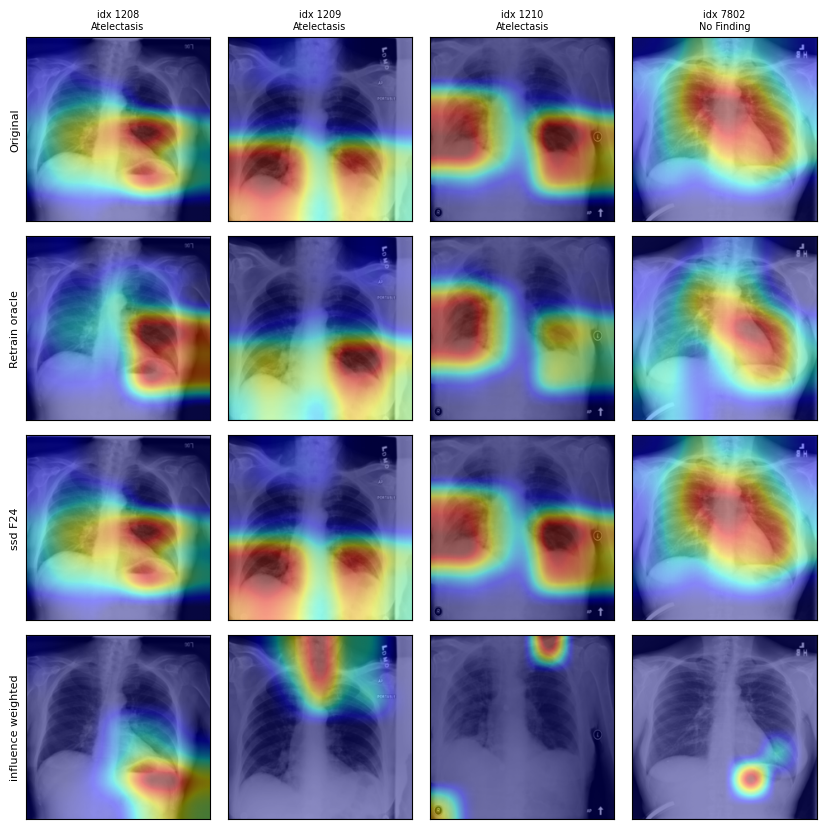

In [31]:
#============================================================================
# F9 - Four-way Grad-CAM figure                                     ~10 min
#
# Fig. 2 of the main paper promises "the four-way comparison including the
# oracle" in the supplement, and the supplement does not contain it - only the
# correlation table. This produces it. Writes fig/sfig5_gradcam4way.png, which
# supp.tex picks up automatically (it is wrapped in \IfFileExists).
#
# Run cell F2-PREP first if SCRUB has run this session: it leaves base_model
# frozen and Grad-CAM's backward pass will fail.
# ============================================================================

import matplotlib.pyplot as plt
from PIL import Image
import torch.nn.functional as Fnn
import contextlib

def _disable_inplace_relu(model):
    """Set inplace=False on all nn.ReLU modules."""
    for module in model.modules():
        if isinstance(module, torch.nn.ReLU):
            module.inplace = False

@contextlib.contextmanager
def _safe_relu():
    """Temporarily force ALL relu calls (module + functional) to non-inplace."""
    _orig_relu = torch.nn.functional.relu
    def _relu_no_inplace(input, inplace=False):
        return _orig_relu(input, inplace=False)
    torch.nn.functional.relu = _relu_no_inplace
    try:
        yield
    finally:
        torch.nn.functional.relu = _orig_relu

def _gradcam(model, x, class_idx=None):
    """Grad-CAM on the last DenseNet block. x: (1,3,H,W) on device."""
    _disable_inplace_relu(model)
    feats, grads = {}, {}
    target_layer = model.backbone.features  # ChestXrayDenseNet wraps DenseNet
    h1 = target_layer.register_forward_hook(
        lambda m, i, o: feats.__setitem__("v", o))
    h2 = target_layer.register_full_backward_hook(
        lambda m, gi, go: grads.__setitem__("v", go[0]))
    model.zero_grad(set_to_none=True)
    with torch.enable_grad(), _safe_relu():
        out = model(x)
        if class_idx is None:
            class_idx = int(out[0].argmax())
        out[0, class_idx].backward()
    h1.remove(); h2.remove()
    A, G = feats["v"][0], grads["v"][0]
    cam = Fnn.relu((G.mean(dim=(1, 2), keepdim=True) * A).sum(0))
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    model.zero_grad(set_to_none=True)
    return cam.detach().cpu().numpy(), class_idx

def four_way_gradcam(n_images=4, methods=("ssd_F24", "influence_weighted"),
                     out="fig/sfig5_gradcam4way.png"):
    os.makedirs(os.path.dirname(out), exist_ok=True)
    picks = sorted(FORGET)[:n_images]
    rows = [("Original", base_model), ("Retrain oracle", ORACLE)]
    for m in methods:
        if m in MODELS:
            rows.append((m.replace("_", " "), MODELS[m]))
        else:
            print(f"  [skip] {m} not in MODELS")

    fig, axes = plt.subplots(len(rows), n_images,
                             figsize=(2.1 * n_images, 2.1 * len(rows)))
    axes = np.atleast_2d(axes)
    for j, idx in enumerate(picks):
        img, _, _ = dataset[idx]
        x = transform_val(img).unsqueeze(0).to(device)
        # anchor every row to the class the ORIGINAL model predicts, so the
        # rows are comparable rather than each following its own argmax
        _, cls = _gradcam(base_model, x)
        for i, (name, m) in enumerate(rows):
            cam, _ = _gradcam(m, x, class_idx=cls)
            ax = axes[i, j]
            ax.imshow(np.asarray(img.convert("L")), cmap="gray")
            ax.imshow(np.array(Image.fromarray((cam * 255).astype(np.uint8))
                               .resize(img.size)), cmap="jet", alpha=0.45)
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(name, fontsize=8)
            if i == 0:
                ax.set_title(f"idx {idx}\n{CLASS_NAMES[cls]}", fontsize=7)
    plt.tight_layout()
    plt.savefig(out, dpi=220, bbox_inches="tight")
    print(f"wrote {out}")
    plt.show()

four_way_gradcam()


In [26]:
# ============================================================================
# F10 - Forget-set size audit                                   ~10 s, no GPU
#
# Resolves the 87-vs-57 discrepancy: the paper says 28 patients -> 87 images,
# cell B6's gate expects 57, and Table X's sweep starts at 57. Prints what the
# construction actually yields on each split so every table can state its
# provenance. Run this FIRST - if it disagrees with the paper, several tables
# need their captions corrected before anything else is worth doing.
# ============================================================================
 
def audit_forget_sizes(seeds=(42, 7, 2024), n_patients=None):
    n_patients = n_patients or CFG["N_PATIENTS"]
    rows = []
    for sd in seeds:
        f, rp, pats = build_patient_forget_set(train_indices, n_patients, seed=sd,
                                               verbose=False)
        rows.append(dict(seed=sd, n_patients=len(pats), n_images=len(f),
                         img_per_patient=len(f) / len(pats),
                         pct_of_train=100 * len(f) / len(train_indices)))
    df = pd.DataFrame(rows)
    print(df.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    print(f"\nCurrent FORGET in memory : {len(FORGET)} images")
    print(f"Training partition size  : {len(train_indices)} images")
    print("\nThe paper states 87 images (0.10% of training) at 28 patients.")
    print("If the numbers above disagree, the split in memory is not the split")
    print("the paper describes - check whether this kernel holds the")
    print("patient-wise or the image-level partition, and label every table")
    print("with the one it came from.")
    df.to_csv(f"{CFG['OUT']}/forget_set_audit.csv", index=False)
    record("forget_set_sizes", df.to_dict("records"))
    return df
 
FORGET_AUDIT = audit_forget_sizes()

 seed  n_patients  n_images  img_per_patient  pct_of_train
   42          28        87            3.107         0.097
    7          28        67            2.393         0.075
 2024          28        61            2.179         0.068

Current FORGET in memory : 87 images
Training partition size  : 89826 images

The paper states 87 images (0.10% of training) at 28 patients.
If the numbers above disagree, the split in memory is not the split
the paper describes - check whether this kernel holds the
patient-wise or the image-level partition, and label every table
with the one it came from.
  [recorded] forget_set_sizes


In [21]:
assert 'ORACLE' in globals() and ORACLE is not None, "run F0"
_ofl, _, _ = subset_stats(ORACLE, FORGET, desc="oracle sanity")
print(f"oracle forget loss = {_ofl:.4f}   (expect 0.4088)")
assert abs(_ofl - 0.4088) < 0.005, "oracle does not match this FORGET set"

oracle sanity:   0%|          | 0/3 [00:00<?, ?it/s]

oracle forget loss = 0.4088   (expect 0.4088)


In [24]:
# ============================================================================
# F11 - A3 on SSD at alpha_sel = 5   (~90 s)
#
# Settles the one open item in Limitations. F7 found this setting lowers the
# A1 gap below SCRUB's while moving 26x FURTHER from the oracle on forget-set
# loss. A1 lacks the resolution to adjudicate; A3 does, because subtracting the
# oracle's per-sample loss cancels intrinsic sample difficulty.
#
# Needs: B6, B7, R7 (ssd_unlearning), F0 (ORACLE).
# ============================================================================

from sklearn.metrics import roc_auc_score

def a3_calibrated(model, oracle, forget, unseen):
    """A3: score = loss under target minus loss under oracle. Floor is 0.5
    exactly, since the oracle scored against itself gives zero difference."""
    _, _, f_t = subset_stats(model,  forget, desc="A3 forget/target")
    _, _, f_o = subset_stats(oracle, forget, desc="A3 forget/oracle")
    _, _, u_t = subset_stats(model,  unseen, desc="A3 unseen/target")
    _, _, u_o = subset_stats(oracle, unseen, desc="A3 unseen/oracle")
    y = np.r_[np.ones(len(f_t)), np.zeros(len(u_t))]
    s = -np.r_[np.asarray(f_t) - np.asarray(f_o),
               np.asarray(u_t) - np.asarray(u_o)]   # lower excess => member-like
    return float(roc_auc_score(y, s))

_unseen = [int(i) for i in val_indices[:len(FORGET)]]

m = fresh_model()
m, _ = ssd_unlearning(m, FORGET, RETAIN_POOL, selection_alpha=5.0)
fL, _, _ = subset_stats(m, FORGET, desc="ssd5 forget")
a3 = a3_calibrated(m, ORACLE, FORGET, _unseen)

print("\n" + "=" * 62)
print(f"SSD alpha_sel=5   A3 = {a3:.4f}   forget loss = {fL:.4f}")
print("reference:  oracle 0.5000 | SCRUB 0.5818 | original 0.6780")
print("=" * 62)
if a3 > 0.64:
    print("-> NO-OP. Behaves like the untouched original. The A1 movement was")
    print("   noise inside A1's resolution floor. Limitations caveat collapses")
    print("   to one sentence and nothing else changes.")
elif a3 < 0.60:
    print("-> REACHES THE ORACLE. A second method lands near SCRUB at full")
    print("   accuracy. This is a real finding: Sec. VI-C and the method-choice")
    print("   paragraph of Sec. VII both need a line.")
else:
    print("-> INTERMEDIATE. Report the number and let it stand as measured.")
del m; torch.cuda.empty_cache()

fisher:   0%|          | 0/11 [00:00<?, ?it/s]

fisher:   0%|          | 0/63 [00:00<?, ?it/s]

  dampened 42679/7220623 params (0.59%)


ssd5 forget:   0%|          | 0/3 [00:00<?, ?it/s]

A3 forget/target:   0%|          | 0/3 [00:00<?, ?it/s]

A3 forget/oracle:   0%|          | 0/3 [00:00<?, ?it/s]

A3 unseen/target:   0%|          | 0/3 [00:00<?, ?it/s]

A3 unseen/oracle:   0%|          | 0/3 [00:00<?, ?it/s]


SSD alpha_sel=5   A3 = 0.5672   forget loss = 0.4247
reference:  oracle 0.5000 | SCRUB 0.5818 | original 0.6780
-> REACHES THE ORACLE. A second method lands near SCRUB at full
   accuracy. This is a real finding: Sec. VI-C and the method-choice
   paragraph of Sec. VII both need a line.


## `[RUN]` X2 — Main Fig. 4: privacy-utility frontier (no GPU, ~2 s)

In [2]:
# ============================================================================
# X2 - Privacy-utility frontier, both accountings          ~2 s, NO GPU NEEDED
#
# Regenerates main Fig. 4 as a vector PDF. Self-contained: the five swept AUCs
# are the measured values from Table VII, and both epsilon curves are analytic
# from (eta, C, B, E, sigma, delta, k). Nothing here touches a model, so this
# runs on a dead kernel with only S1 executed.
#
# Writes fig/fig4_frontier_v2.pdf (+ .png).
# ============================================================================

import numpy as np, os
import matplotlib; matplotlib.use("Agg", force=False)
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq
from scipy.special import log_ndtr

os.makedirs("fig", exist_ok=True)

eta, C, B, E, delta, k = 1e-4, 1.0, 32, 5, 1e-5, 15
D_ps = 2 * eta * C * E / B                      # per-sample sensitivity

def eps_analytic(D, s, dl):
    f = lambda e: (norm.cdf(D/(2*s) - e*s/D)
                   - np.exp(e + log_ndtr(-D/(2*s) - e*s/D)) - dl)
    hi = 1.0
    while f(hi) > 0:
        hi *= 2
    return brentq(f, 1e-13, hi, xtol=1e-14, rtol=1e-14)

adv  = lambda e0: np.sqrt(2*k*np.log(1/1e-5))*e0 + k*e0*(np.exp(e0) - 1)
def zcdp(D, s):
    rho = k * D**2 / (2 * s**2)
    return rho + 2*np.sqrt(rho*np.log(1/delta))

sig = np.array([1e-4, 3e-4, 1e-3, 3e-3, 1e-2])
auc = np.array([0.7975, 0.8043, 0.8021, 0.7758, 0.6874])   # measured, Table VII
e_a = np.array([adv(eps_analytic(D_ps, s, delta)) for s in sig])
e_z = np.array([zcdp(D_ps, s) for s in sig])

s_adv = brentq(lambda s: adv(eps_analytic(D_ps, s, delta)) - 1, 1e-6, 1e-1)
s_z   = brentq(lambda s: zcdp(D_ps, s) - 1,                     1e-6, 1e-1)
print(f"sigma* : advanced composition {s_adv:.3g} | zCDP {s_z:.3g}")
print(f"eps_tot at 1e-3: adv {e_a[2]:.3f} | zCDP {e_z[2]:.3f}   (paper 1.92 / 0.59)")

fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.semilogx(sig, auc, "o-", color="tab:blue", label="macro AUC")
ax.axhline(0.8391, ls="--", c="gray", lw=1)
ax.set_xlabel(r"noise scale $\sigma$")
ax.set_ylabel("macro AUC", color="tab:blue")
ax.tick_params(axis="y", labelcolor="tab:blue")
ax.set_ylim(0.68, 0.845)

ax2 = ax.twinx()
ax2.loglog(sig, e_a, "s--", color="tab:orange",
           label=r"$\epsilon_{\rm tot}$ (analytic + adv. comp.)")
ax2.loglog(sig, e_z, "^-",  color="tab:green",
           label=r"$\epsilon_{\rm tot}$ (zCDP)")
ax2.axhline(1.0, ls=":", c="k", lw=1)
ax2.set_ylabel(r"$\epsilon_{\rm tot}$ after 15 requests", color="tab:red")
ax.axvline(s_adv, ls=":", c="tab:orange", lw=1.2)
ax.axvline(s_z,   ls=":", c="tab:green",  lw=1.2)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=7.5)
ax.set_title("Privacy-utility frontier (per-sample clipping)", fontsize=10)
plt.tight_layout()
plt.savefig("fig/fig4_frontier_v2.png", dpi=220)   # X1's patch emits the PDF
plt.show()


sigma* : advanced composition 0.00175 | zCDP 0.000593
eps_tot at 1e-3: adv 1.923 | zCDP 0.588   (paper 1.92 / 0.59)


C:\Users\paida\AppData\Local\Temp\ipykernel_40104\2492980351.py:71: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## `[RUN]` X3 — Verify the privacy accounting against B5 (no GPU, ~2 s)

In [3]:
# ============================================================================
# X3 - Cross-check the accounting that Table I and Table VII report
#
# This is an INDEPENDENT reimplementation of what B5 computes. The point is the
# top block: if these reproduce B5's printed classical figures exactly, the new
# analytic / zCDP figures came off the same correct code path and the paper's
# tables are trustworthy. If they disagree, one implementation has a bug and
# Table I is wrong.
#
# ~2 s, no GPU, no model. Run after S1.
# ============================================================================

import numpy as np
from scipy.stats import norm
from scipy.optimize import brentq
from scipy.special import log_ndtr

eps_cls = lambda D, s, dl: D * np.sqrt(2 * np.log(1.25 / dl)) / s

def eps_ana(D, s, dl):
    f = lambda e: (norm.cdf(D/(2*s) - e*s/D)
                   - np.exp(e + log_ndtr(-D/(2*s) - e*s/D)) - dl)
    hi = 1.0
    while f(hi) > 0:
        hi *= 2
    return brentq(f, 1e-13, hi, xtol=1e-14, rtol=1e-14)

adv_comp = lambda e0, k, dp: np.sqrt(2*k*np.log(1/dp))*e0 + k*e0*(np.exp(e0) - 1)

def zcdp(D, s, k, dl):
    rho = k * D**2 / (2 * s**2)
    return rho + 2*np.sqrt(rho*np.log(1/dl)), rho

eta, C, B, E, delta, k = 1e-4, 1.0, 32, 5, 1e-5, 15
D_ps, D_agg = 2*eta*C*E/B, B * (2*eta*C*E/B)

print("=" * 66)
print("MUST MATCH WHAT B5 PRINTED")
print("=" * 66)
checks = [
    ("Delta2 per-sample",       D_ps,                              3.125e-5),
    ("Delta2 aggregate",        D_agg,                             1.0e-3),
    ("eps0 classical  p-s",     eps_cls(D_ps, 1e-4, delta),        1.514),
    ("eps0 classical  aggr",    eps_cls(D_agg, 1e-4, delta),       48.4),
    ("eps_tot advcomp p-s",     adv_comp(eps_cls(D_ps,1e-4,delta),  k, 1e-5), 108.6),
]
ok = True
for name, got, want in checks:
    rel = abs(got - want) / abs(want)
    flag = "OK  " if rel < 0.01 else "FAIL"
    ok &= rel < 0.01
    print(f"  [{flag}] {name:<22} {got:>12.4g}   expected {want:>10.4g}")
print(f"  [    ] eps_tot advcomp aggr  "
      f"{adv_comp(eps_cls(D_agg,1e-4,delta), k, 1e-5):>12.4g}   expected ~8e23")

print("\n" + "=" * 66)
print("NEW VALUES NOW IN TABLE I AND TABLE VII")
print("=" * 66)
print(f"  {'sigma':>8} {'eps0_ana':>10} {'advcomp':>10} {'zCDP':>10}   paper (zCDP)")
paper_z = {1e-4: 6.54, 3e-4: 2.02, 1e-3: 0.588, 3e-3: 0.194, 1e-2: 0.058}
for s in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]:
    ea = eps_ana(D_ps, s, delta)
    ez, _ = zcdp(D_ps, s, k, delta)
    print(f"  {s:>8.0e} {ea:>10.4f} {adv_comp(ea,k,1e-5):>10.3f} "
          f"{ez:>10.4f}   {paper_z[s]:.3f}")

s_z = brentq(lambda s: zcdp(D_ps, s, k, delta)[0] - 1, 1e-6, 1e-1)
print(f"\n  sigma* for zCDP eps_tot=1 : {s_z:.4g}      (paper 5.9e-04)")
print(f"  aggregate zCDP at 1e-4    : {zcdp(D_agg,1e-4,k,delta)[0]:.4g}"
      f"          (paper 936)")
print("\n" + ("VERDICT: accounting verified. No action needed."
               if ok else
               "VERDICT: MISMATCH in the top block -- do not submit until resolved."))


MUST MATCH WHAT B5 PRINTED
  [OK  ] Delta2 per-sample         3.125e-05   expected  3.125e-05
  [OK  ] Delta2 aggregate              0.001   expected      0.001
  [OK  ] eps0 classical  p-s           1.514   expected      1.514
  [OK  ] eps0 classical  aggr          48.45   expected       48.4
  [OK  ] eps_tot advcomp p-s           108.6   expected      108.6
  [    ] eps_tot advcomp aggr     7.982e+23   expected ~8e23

NEW VALUES NOW IN TABLE I AND TABLE VII
     sigma   eps0_ana    advcomp       zCDP   paper (zCDP)
     1e-04     1.1838     62.252     6.5401   6.540
     3e-04     0.3562      8.905     2.0173   2.020
     1e-03     0.0957      1.923     0.5881   0.588
     3e-03     0.0285      0.542     0.1944   0.194
     1e-02     0.0073      0.137     0.0582   0.058

  sigma* for zCDP eps_tot=1 : 0.0005931      (paper 5.9e-04)
  aggregate zCDP at 1e-4    : 935.8          (paper 936)

VERDICT: accounting verified. No action needed.
